# 4-estimators: speed

Read the motor's speed from its back-EMF one control tick at a time, the way a velocity loop has to, and say what it costs in bias, noise and delay and when it is valid. The estimate is stage 3's four-term form, run per row instead of over a window. Its brush term is carried in two forms side by side, the signed speed table and the speed-times-current product, and the choice between them stays open. The notebook has no capture of its own. It re-reads stage 3's sweeps and takes every constant from the result files of stages 1 to 3 and of the current-zero notebook.

## Purpose

Stage 3 graded the estimate on window means, one number per window of rows. A velocity loop reads it once per row, from the rows before, and averages afterwards if at all. This notebook runs the same form per row and asks what changes.

- The gate. Window means of the per-row estimate against stage 3's window estimate on stage 3's own windows, by set and band.
- What each input a controller has instead of stage 3's costs, one at a time. These are the tracked zero in place of the coast's, the rail from the row's own tap, R(T) from the board NTC and no dropout term.
- The brush term's two forms side by side, on the free shaft, under current at speed and at low speed under current.
- The solve. The product form in closed form, the table by a fixed number of steps per row.
- The noise per row, where it comes from and its spectrum.
- The filters as noise against measured delay, a window locked to the commutation period among them.
- The L di/dt term, what it is worth and what it costs.
- The valid flag, from the tap floor, the dropouts, the start-up rows and the stopped rotor, and the share of driven rows it passes.
- What stage 5 reads. One table, then the gaps with the capture that would close each.

## Procedure

No sitting ran for this notebook. The estimate, its filters and its valid rules are pure functions in `oscnb.speed`, run down the rows of stage 3's sweeps, one row per PWM period at the control tick, with only the rows before it. The truths it is graded against are offline and may look ahead. They are the ripple tach on the steady windows and the duty steps, stage 3's order count on the run-ups, and the pot through stage 3's table on the lifts and the load holds. The back-EMF speed is never fitted to the pot. Where the pot appears it only grades or, for the load holds at rest, selects the holds. The README's rules of the desk hold here.

The method follows two analysis notes that were reviewed and reproduced before this notebook was written, one for the estimate per row, its gate, its inputs, the brush forms and the solve, one for the noise, the filters, the L term and the valid flag.

## Data

Everything is under `telemetry/mg90-d__dev-v006-2A-D/`, stage 3's whole pair folder, read into one row store with the two terminal taps and `window_valid` beside the columns of the zero replay. Stage 3's windows are placed on that store as global row ranges by `oscnb.windows`.

The libraries, then the pair and its folders.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import welch

from oscnb import (boards, figures, results, scales, servos, speed, sweeps,
                   winding, windows, zero)
from oscnb.display import show
from oscnb.figures import BLUE, GREEN, INK, MUTED, ORANGE, RED

pd.set_option("display.width", 200)    # the printed tables run wide

In [2]:
SERVO = servos.SERVOS["mg90-d"]         # the servo: train, ripple per rev
BOARD = boards.BOARDS[boards.DEFAULT]   # the board, checked on every sweep
PAIR = f"{SERVO.key}__{BOARD.key}"      # the pair, the result file's name
PAIR_DIR = Path("../../../telemetry") / PAIR
STAGE, EXPERIMENT = "4-estimators", "speed"     # where the result goes
print(SERVO.key, "on", BOARD.key, "from", results.rel(PAIR_DIR.resolve()))
print(f"control tick {BOARD.tick_hz} rows/s, half period {BOARD.pwm_arr} "
      "ticks, on the board's registry entry")

mg90-d on dev-v006-2A-D from telemetry/mg90-d__dev-v006-2A-D
control tick 20000 rows/s, half period 1200 ticks, on the board's registry entry


## 1. The rig, the data and the constants

### Stage 3's datasets

Each stage 3 window is read against the sitting manifest its sweeps ran in, which holds the probes taken with the torque off before each sweep (the board NTC and the rail). The maps below name mg90-d's own folders and are the only place they are typed.

In [3]:
# dataset -> the sitting manifest under sittings/ its sweeps ran in
LADDER_SITTING = {"capture-1": "servo-1.csv", "rail-1": "servo-1.csv",
                  "ref-open-1": "servo-1.csv", "ref-close-1": "servo-1.csv",
                  "ref-open-6": "servo-6.csv", "ref-close-6": "servo-6.csv",
                  "ref-open-7": "servo-7.csv", "ref-close-7": "servo-7.csv"}
RUNUP_SITTING = {f"runup-{side}-{k}": f"servo-{k}.csv"
                 for side in ("open", "close") for k in (1, 6, 7)}
LOAD_SITTING = {"1": "servo-load-1.csv", "2": "servo-load-2.csv",
                "3": "servo-load-3.csv"}
LOW_SITTING = {"low-1": "servo-1.csv"}      # the ladder's low holds
SAG_SITTING = {"capture-1": "servo-1.csv"}  # the sag's crawls and cycles
STEPS_DATASET = "steps/capture-1"           # the duty steps
print(len(LADDER_SITTING), "ladder sets,", len(RUNUP_SITTING), "run-up sets,",
      len(LOAD_SITTING), "load sittings")

8 ladder sets, 6 run-up sets, 3 load sittings


### The constants, through the chain

Stage 1's scales give the current channel's scale, the tap scale and offset, the edge lags at the two graded rails and the in-drive offset. Stage 3's resistance, inductance and ladder results give R at its board temperature, V0, the reading term g, the brake line, L, Ke and the ladder's dropout coefficient k_d. Stage 3's compensation result gives the two brush forms of record, the table and the product, and the scores this notebook's gate is held against. Stage 1's compensation result gives the awake step line the sweep classes are drawn from, and the current-zero notebook's result gives its design of the tracked zero, the second rule of section 3. Copper's slope with temperature is the one typed constant, as in stage 3.

Stage 3 recommends no dropout term, `k_d = 0`. That is the estimate of record here, `MOTOR`. The ladder's candidate k_d, `MOTOR_KD`, appears only where the gate against stage 3's own estimate needs it.

In [4]:
SCALES = scales.load(BOARD)                     # stage 1's chain
RES3 = results.read("3-servo", "resistance", pair=PAIR)
IND3 = results.read("3-servo", "inductance", pair=PAIR)
LAD3 = results.read("3-servo", "ladder", pair=PAIR)
COMP3 = results.read("3-servo", "compensation", pair=PAIR)
NL2 = results.read("2-motor", "no-load-current", pair=SERVO.type_motor)
COMP1 = results.read("1-board", "compensation", pair=BOARD.key)
CZ4 = results.read("4-estimators", "current-zero", pair=PAIR)
POT_TABLE = pd.read_csv(results.path("3-servo", "pot-table", pair=PAIR)
                        .with_suffix(".table.csv"))   # counts -> deg
CHAIN = speed.chain_of(BOARD, SCALES)           # the sense chain
MOTOR = speed.motor_of(RES3, IND3, LAD3, k_d=0.0)   # k_d = 0, of record
MOTOR_KD = speed.motor_of(RES3, IND3, LAD3)     # the ladder's candidate k_d
KE = MOTOR.ke_v_per_rev_s                       # V per rev/s
FS = CHAIN.fs_hz                                # rows per second
PER_REV = SERVO.motor_entry.ripple_per_rev      # commutation events per rev
TABLE3_CLIP = speed.brush_table(COMP3, "clipped")   # stage 3's "full"
TABLE3_SIGN = speed.brush_table(COMP3, "signed")
PROD3 = speed.brush_product(COMP3)              # stage 3's product form
c, m = CHAIN, MOTOR_KD
print(f"chain: {1 / c.a_per_count:.1f} counts/A, {c.tap_counts_per_v:.2f} "
      f"counts/V on the taps, offset {c.tap_offset_counts:.2f}, half "
      f"period {c.half_period_ticks} ticks; edge lags ON {c.lag_on_ticks} "
      f"OFF {c.lag_off_ticks} ticks at {c.lag_rail_v} V")
print(f"motor: R {m.r_ohm:.4f} ohm at {m.t0_c:.2f} C, V0 "
      f"{m.v0_v * 1e3:+.1f} mV, g {m.g_s * 1e3:.3f} mS, brake "
      f"{m.brake_b0_v * 1e3:.2f} mV + {m.brake_b1_ohm:.4f} ohm, L "
      f"{m.l_h * 1e3:.3f} mH, Ke {KE * 1e3:.4f} mV per rev/s")
print(f"k_d: candidate {m.k_d_v_per_dropout_s * 1e3:.3f} mV per dropout/s,"
      f" of record {MOTOR.k_d_v_per_dropout_s:.1f}; copper "
      f"{speed.ALPHA_CU * 100:.2f} %/C; {PER_REV} events per rev")
print(f"stage 3's product form: c0 {PROD3.c0_v * 1e3:+.2f} mV, c_dir "
      f"{PROD3.c_dir_v * 1e3:+.2f} mV, b {PROD3.b_v_per_rev_s_a * 1e3:.4f} "
      "mV per (rev/s x A)")

chain: 1135.0 counts/A, 248.37 counts/V on the taps, offset 2.38, half period 1200 ticks; edge lags ON (37.0, 42.0) OFF (13.0, 15.0) ticks at (3.7, 7.4) V
motor: R 4.1767 ohm at 26.26 C, V0 +33.2 mV, g 4.746 mS, brake 8.75 mV + 0.2397 ohm, L 0.820 mH, Ke 7.2828 mV per rev/s
k_d: candidate 0.781 mV per dropout/s, of record 0.0; copper 0.39 %/C; 6 events per rev
stage 3's product form: c0 -35.57 mV, c_dir +14.37 mV, b 1.9560 mV per (rev/s x A)


### The rows

One row store holds every sweep of the pair end to end in time order, one row per control tick, with the global row index every window below refers to. The store is built once here and every later cell reads it.

In [5]:
COLUMNS = sweeps.ZERO_COLUMNS + ("va", "vb", "valid")
STORE = sweeps.row_store(PAIR_DIR, columns=COLUMNS, board=BOARD)
ARR, SW = STORE.arrays, STORE.sweeps    # row columns, the sweep table
N_ROWS = len(ARR["raw"])
DRIVE, COAST, ASLEEP = sweeps.DRIVE, sweeps.COAST, sweeps.ASLEEP
print(f"{N_ROWS} rows in {len(SW)} sweeps over {SW['day'].nunique()} days,"
      f" {int((ARR['bridge'] == DRIVE).sum())} of them driven")
print(SW.groupby("experiment").agg(sweeps=("folder", "size"),
                                   rows=("rows", "sum")).to_string())

22853600 rows in 521 sweeps over 4 days, 10508431 of them driven
            sweeps     rows
experiment                 
inductance       2    32000
ladder         123  7429440
load           222  8252000
pot-table       22  2473800
resistance      58  1384000
run-up          18   577440
sag             40  1733880
sittings         6   164000
steps           30   807040


The store holds 22853600 rows in 521 sweeps over 4 days, 10508431 of them driven.

The rows carry the duty as a magnitude and `dir`, the chain's travel label. The drive's direction is the duty's sign, which the store does not keep, and the noise section folds on the tick counter, of which the store keeps only the low four bits. Both come from one more pass over the sweeps. The pass also checks what the rows carry for the board NTC and the rail.

In [6]:
SGN = np.zeros(N_ROWS, np.int8)     # the duty's sign: the drive's direction
TICK = np.zeros(N_ROWS, np.int64)   # the tick counter per row
nan_cells = {k: 0 for k in ("ntc_raw", "vbus_raw", "vbus", "vref_raw")}
for s in SW.itertuples():
    rows, _, _ = sweeps.load(PAIR_DIR, s.folder, BOARD)
    sl = slice(int(s.i0), int(s.i1))
    SGN[sl] = np.sign(rows["duty_counts"].to_numpy())
    TICK[sl] = rows["tick"].to_numpy().astype(np.int64) & 0x7FFFFFFF
    for k in nan_cells:             # the slow channels, per row
        nan_cells[k] += int(rows[k].isna().sum()) if k in rows else len(rows)
driven = SGN != 0
opposed = driven & (SGN != ARR["dirn"])
print("rows with no value:", {k: f"{v} of {N_ROWS}"
                              for k, v in nan_cells.items()})
print(f"driven rows {int(driven.sum())}, the duty's sign against dir on "
      f"{int(opposed.sum())}, in:")
by = pd.Series(SW["folder"].to_numpy()[np.searchsorted(
    SW["i1"].to_numpy(), np.flatnonzero(opposed), side="right")])
print(by.str.split("/").str[:2].str.join("/").value_counts().to_string())

rows with no value: {'ntc_raw': '22853600 of 22853600', 'vbus_raw': '22853600 of 22853600', 'vbus': '22853600 of 22853600', 'vref_raw': '22853600 of 22853600'}
driven rows 10508431, the duty's sign against dir on 118485, in:
pot-table/reversal-9    82508
steps/reversal-1        35977


None of the 22853600 rows carries the board NTC or the rail. The four slow channels are empty in every row. R(T) therefore reads the NTC of each sweep's probe, below, and the edge lags read the sweep's probe or the row's own V_on. The duty's sign differs from `dir` on 118485 driven rows, all of them in the two reversal sets, pot-table/reversal-9 and steps/reversal-1. Through a reversal the chain's travel label and the drive's direction part, so the estimate takes the drive's direction from the duty's sign.

### The board NTC and the rail

The rows carry no NTC and no rail. Every sweep has a probe in its sitting manifest instead, read with the torque off just before the sweep, so it is causal. R(T) reads the NTC of that probe. A sweep with no probe of its own takes the last probe before it.

In [7]:
PROBES = winding.probes(PAIR_DIR, BOARD, SCALES)    # every torque-off probe
own = PROBES.drop_duplicates("where", keep="last").set_index("where")
where = "telemetry/" + PAIR + "/" + SW["folder"]
NTC_SWEEP = own["ntc_c"].reindex(where).to_numpy()   # C, per sweep
probed = int(np.isfinite(NTC_SWEEP).sum())
NTC_SWEEP = (pd.Series(NTC_SWEEP).ffill().fillna(MOTOR.t0_c).to_numpy())
print(f"{len(PROBES)} probes; {probed} of {len(SW)} sweeps have their own, "
      f"NTC {NTC_SWEEP.min():.1f} to {NTC_SWEEP.max():.1f} C")

567 probes; 521 of 521 sweeps have their own, NTC 24.5 to 28.7 C


All 521 sweeps have a probe of their own among the 567, and the board NTC reads 24.5 to 28.7 C over them.

### Stage 3's windows

`oscnb.windows` places each of stage 3's windows on the row store as a global row range with its truth, its coast-tail zero and its probes, so a per-row estimate can be averaged over exactly the rows stage 3 averaged.

- The ladder's spins and reference rungs, the end of a spin's held duty, the ripple tach seeded by its coast the truth.
- The holds, the ladder's low holds and the sag's crawls and cycles, a hold's last rows.
- The run-ups to full duty on the 5 V rail, one revolution of stage 3's order count per window, and the dropout rows of every run-up.
- The lifts of the three load sittings, short windows past the lift's start, the pot through stage 3's table the truth.
- The load ladders' held segments, the arm at rest against gravity, the pot's line the truth.
- The duty steps, a first-order response fitted to the phase of the commutation crossings, the ripple tach's truth for a transient.

In [8]:
PAIR_W = windows.Pair(
    folder=PAIR_DIR, sweeps=SW, board=BOARD, chain=CHAIN, motor=MOTOR_KD,
    servo=SERVO, probes=PROBES, pot_table=POT_TABLE,
    drive_offset_counts=SCALES.drive_offset_counts)
LAD_W = windows.ladder_windows(PAIR_W, LADDER_SITTING)
HOLD_W = windows.hold_windows(PAIR_W, LOW_SITTING, SAG_SITTING)
RUN_W, DROPPED = windows.runup_windows(
    PAIR_W, RUNUP_SITTING, RES3["r_term_ohm"]["value"],
    NL2["drive_drag_by_level_meter"]["5 V"])
LIFT_W = windows.lift_windows(
    PAIR_W, {f"lift-{k}": v for k, v in LOAD_SITTING.items()})
LOAD_W = windows.load_hold_windows(
    PAIR_W, {f"ladder-{k}": v for k, v in LOAD_SITTING.items()}, LAD3)
for name, W in (("ladder and references", LAD_W), ("holds", HOLD_W),
                ("run-up turns", RUN_W), ("lifts", LIFT_W),
                ("load holds", LOAD_W)):
    print(f"{name}: {len(W)} windows, {int((W['g1'] - W['g0']).sum())} "
          "rows")
print(f"spin window {windows.SPIN_WINDOW_MS} ms, hold tail "
      f"{windows.HOLD_TAIL_ROWS / FS * 1e3:.0f} ms, lift windows "
      f"{windows.LIFT_WINDOW_S * 1e3:.0f} ms from "
      f"{windows.LIFT_SKIP * windows.LIFT_WINDOW_S * 1e3:.0f} ms in")
print(f"run-ups: {int(RUN_W['ok'].sum())} unflagged turns, "
      f"{int(DROPPED.sum())} dropout rows")

ladder and references: 144 windows, 257808 rows
holds: 154 windows, 1076000 rows
run-up turns: 3505 windows, 177427 rows
lifts: 312 windows, 624000 rows
load holds: 122 windows, 264000 rows
spin window 100 ms, hold tail 400 ms, lift windows 100 ms from 200 ms in
run-ups: 3446 unflagged turns, 52 dropout rows


The motor the windows read is the candidate k_d one, since stage 3's window estimate carried it. The duty steps' truth needs the tracked zero and is built in section 7.

### The sets each grade uses

The filters are stage 3's. On the ladder a spin counts when its coast passed the Ke gate and its tach reads over `TACH_MIN_REV_S`. The capture and rail sets are the spins the ladder grade is held out on, by repeat, and the reference rungs are scored on the table of record. A hold counts when nearly all its rows have a valid window (`windows.VALID_SHARE`), it kept turning and its tach saw four cycles. A run-up turn counts when it is unflagged. The load holds count when the pot held still, within the windows module's 8 counts, and, for the brush forms, when the duty is 6 % or more.

In [9]:
TACH_MIN_REV_S = 50         # rev/s, stage 3's floor for a spin's tach
tach_ok = (LAD_W["ke_gate"].fillna(False).astype(bool)
           & (LAD_W["tach_rev_s"] > TACH_MIN_REV_S))
FIT = LAD_W[LAD_W["set"].isin(["capture-1", "rail-1"]) & tach_ok]
REFS = LAD_W[LAD_W["set"].str.startswith("ref") & tach_ok]
HOLDS = HOLD_W[(HOLD_W["window_valid_share"] > windows.VALID_SHARE)
               & HOLD_W["kept_turning"].fillna(True).astype(bool)
               & HOLD_W["tach_rev_s"].notna()
               & (HOLD_W["tach_cycles"] >= 4)]
RU = RUN_W[RUN_W["ok"]]
LIFT1 = LIFT_W[LIFT_W["set"] == "lift-1"]
LOADH = LOAD_W[LOAD_W["still"] & LOAD_W["truth"].notna()
               & (LOAD_W["duty_pct"] >= 6)]
FIT, REFS, HOLDS, RU, LIFT1, LIFTS, LOADH = (
    W.reset_index(drop=True)
    for W in (FIT, REFS, HOLDS, RU, LIFT1, LIFT_W, LOADH))
for name, W in (("ladder, held out by repeat", FIT), ("references", REFS),
                ("holds", HOLDS), ("run-up turns", RU), ("lift-1", LIFT1),
                ("lifts", LIFTS), ("load holds at 6 % or more", LOADH)):
    print(f"{name}: {len(W)} windows in {W['sweep'].nunique()} sweeps")
print(f"repeats {sorted(FIT['repeat'].unique())}; run-ups "
      f"{RU.groupby(['set', 'k', 'dir']).ngroups}")

ladder, held out by repeat: 85 windows in 43 sweeps
references: 35 windows in 18 sweeps
holds: 101 windows in 51 sweeps
run-up turns: 3446 windows in 18 sweeps
lift-1: 104 windows in 12 sweeps
lifts: 312 windows in 36 sweeps
load holds at 6 % or more: 60 windows in 60 sweeps
repeats [np.int64(0), np.int64(1), np.int64(2)]; run-ups 36


The ladder grade has 85 spins in 3 repeats, the references 35, the holds 101 and the run-ups 3446 unflagged turns of 36 run-ups. The lifts hold 312 windows in 36 sweeps, 104 of them in the first load sitting, and 60 load holds at rest have a duty of 6 % or more.

### Bands and classes

Speeds are reported in stage 3's bands. Each sweep has a class for the tracked zero's grade, as the current-zero notebook draws it. A sweep is cold when it is the first or follows a rest of more than the stale count, rail moved when its rail differs from the sweep before's by more than half a count of stage 1's awake step line, and warm otherwise.

In [10]:
BANDS = ((0, 30), (30, 100), (100, 160), (160, 250), (250, 350),
         (350, 450), (450, 600))                # rev/s, stage 3's
BAND_NAMES = [f"{a}-{b}" for a, b in BANDS]
ORDER = {b: i for i, b in enumerate(BAND_NAMES)}


def band_of(w):
    """Stage 3's band of each speed (by magnitude), 'other' outside."""
    w = np.abs(np.asarray(w, float))
    out = np.full(len(w), "other", dtype=object)
    for a, b in BANDS:
        out[(w >= a) & (w < b)] = f"{a}-{b}"
    return out


STEP1_B = COMP1["step_shape"]["line_slope_counts_per_v"]["value"]
HALF_COUNT_V, LONG_GAP_S = zero.class_bounds(STEP1_B, STORE.tick_hz)
CLS = zero.sweep_class(SW, HALF_COUNT_V, LONG_GAP_S)    # per sweep
for W in (FIT, REFS, HOLDS, RU, LIFT1, LIFTS, LOADH):
    W["band"] = band_of(W["truth"])
    W["cls"] = CLS[W["sweep"].to_numpy()]
print(f"rail moved past {HALF_COUNT_V:.2f} V, cold after {LONG_GAP_S:.0f}"
      " s of rest; sweeps by class",
      pd.Series(CLS).value_counts().to_dict())

rail moved past 0.28 V, cold after 655 s of rest; sweeps by class {'warm': 477, 'rail moved': 34, 'cold': 10}


A rail move of more than 0.28 V marks a sweep, and a rest of more than 655 s makes it cold. Of the 521 sweeps 477 are warm, 34 rail moved and 10 cold.

### The tracked zero

A controller has no coast tail. It has the current zero tracked one tick at a time, the current-zero notebook's subject. Here that tracker is stage 1's two-zero tracker in float, the form the current-zero notebook keeps of record, run over every sweep in time order with its state carried. A row uses the tracker's state after the row before. A second rule runs beside it, the design of the current-zero notebook, built from that notebook's result file. It feeds the coast from the crest column, which the reading uses, takes the drive-feed offset off a drive's fed sample, and seeds the awake zero from the asleep zero plus the awake step line at the rail, at boot and when the rail has moved past a threshold from where the zero was learned.

In [11]:
def tracked(rule):
    """The awake zero each row may use: the tracker's state after the row
    before (float counts)."""
    z, _, _ = zero.replay(rule, STORE)      # after each row's update
    return np.r_[z[0], z[:-1]]


def cz(key):
    """A value of the current-zero notebook's result."""
    return CZ4[key]["value"]


DESIGN_RULE = zero.Rule(                        # current-zero's design
    coast_raw=True, drive_off=cz("drive_feed_offset_counts"),
    seed_boot=True, seed_thr_v=cz("seed_rail_threshold_v"),
    step_a=cz("awake_step_intercept_counts"),
    step_b=cz("awake_step_slope_counts_per_v"),
    debounce=int(cz("seed_debounce_ticks")), gate_pct=cz("feed_gate_pct"))
Z_TRACK = tracked(zero.Rule())                  # stage 1's tracker, float
Z_DESIGN = tracked(DESIGN_RULE)                 # the design
r = DESIGN_RULE
print(f"design: gate {r.gate_pct:.0f} %, drive feed less {r.drive_off:.3f} "
      f"counts, seed at boot and past {r.seed_thr_v:.3f} V, step "
      f"{r.step_a:+.3f} + {r.step_b:.3f} x V counts, debounce {r.debounce}")
print(f"tracked zero over {len(Z_TRACK)} rows: {np.nanmin(Z_TRACK):.2f} to "
      f"{np.nanmax(Z_TRACK):.2f} counts; the design moves it "
      f"{np.nanmean(Z_DESIGN - Z_TRACK):+.3f} counts on average")

design: gate 30 %, drive feed less 0.667 counts, seed at boot and past 0.319 V, step -2.717 + 1.667 x V counts, debounce 32
tracked zero over 22853600 rows: 1198.83 to 1218.20 counts; the design moves it -0.574 counts on average


### Rows of a set of windows

The grades of sections 2 to 5 gather the rows of a set of windows into one array, compute the estimate on every row and take each window's mean back out. `Rows` keeps the gather, which is the global rows, the window each row belongs to and the rows that count (a run-up's dropout rows do not). The direction on these windows is the `dir` column, which matches the duty's sign on every one of them.

In [12]:
class Rows:
    """The rows of a set of windows W (g0..g1 each), in window order."""

    def __init__(self, W, dropped=None):
        g0 = W["g0"].to_numpy(np.int64)
        g1 = W["g1"].to_numpy(np.int64)
        self.W, self.n_win = W, len(W)
        self.wid = np.repeat(np.arange(len(W)), g1 - g0)   # row -> window
        self.idx = np.concatenate([np.arange(a, b)          # global rows
                                   for a, b in zip(g0, g1)])
        self.keep = (np.ones(len(self.idx), bool) if dropped is None
                     else ~dropped[self.idx])               # rows that count
        self.d = ARR["dirn"][self.idx].astype(np.int64)     # direction

    def per_row(self, col):
        """A window column repeated onto the window's rows."""
        return self.W[col].to_numpy(float)[self.wid]

    def mean(self, x, keep=None):
        """Each window's mean of x over its rows that count."""
        k = self.keep if keep is None else keep
        n = np.bincount(self.wid[k], minlength=self.n_win)
        s = np.bincount(self.wid[k], weights=x[k], minlength=self.n_win)
        return s / np.maximum(n, 1)

    def sd(self, x, keep=None):
        """Each window's sd of x about its own mean."""
        k = self.keep if keep is None else keep
        m = self.mean(x, k)
        n = np.bincount(self.wid[k], minlength=self.n_win)
        v = np.bincount(self.wid[k], weights=(x[k] - m[self.wid[k]]) ** 2,
                        minlength=self.n_win)
        return np.sqrt(v / np.maximum(n - 1, 1))

`signals` builds the two quantities the brush term reads, u and the winding current, on every gathered row. The zero is one value per row. The rail for the edge lags is the sweep's probe, as stage 3 had it, or the row's own V_on, as a controller has it. The L di/dt term is off, the difference to the row before, the slope over the last n rows (none before the run's start), or stage 3's slope over the whole window carried on each row, which looks ahead and serves only as a control.

In [13]:
def rows_at(j, z, rail_rows, motor):
    """(i_w, V_c) of global rows j with zero z (counts per row)."""
    d = ARR["dirn"][j]
    v_on = speed.tap_volts(ARR["va"][j], ARR["vb"][j], d, CHAIN)
    i_w, v_c, _, _ = speed.construct(ARR["raw"][j], z, v_on, ARR["duty"][j],
                                     CHAIN, motor, rail_rows)
    return i_w, v_c


def signals(R, z, motor, rail="probe", with_l=False, rate=True):
    """(u, i_w) per gathered row: z the zero per row, rail 'probe' or
    'row', with_l False / True / n rows / 'window', rate the window's
    dropout rate times the motor's k_d."""
    rails = R.per_row("rail_v") if rail == "probe" else None
    i_w, v_c = rows_at(R.idx, z, rails, motor)
    didt = None
    if with_l == "window":                  # stage 3's, not causal
        didt = R.per_row("didt_s3")
    elif with_l is True:                    # the row before
        didt = (i_w - rows_at(R.idx - 1, z, rails, motor)[0]) * FS
    elif with_l:                            # the last with_l rows
        j = np.maximum(R.idx - int(with_l),
                       R.per_row("run0").astype(np.int64))
        i_j = rows_at(j, z, rails, motor)[0]
        didt = np.where(R.idx > j,
                        (i_w - i_j) * FS / np.maximum(R.idx - j, 1), 0.0)
    u = speed.u_rows(i_w, v_c, R.per_row("ntc_c"), motor, didt,
                     R.per_row("rate") if rate else None)
    return u, i_w

An error is the estimate less the truth. `stats` gives its mean, standard error, sd and rms, and the mean and rms as a share of the truth.

In [14]:
def stats(e, truth=None):
    """n, bias, se, sd, rms of an error series (NaN dropped), and with
    `truth` the bias and rms in % of it."""
    e = np.asarray(e, float)
    ok = np.isfinite(e)
    x = e[ok]
    n = len(x)
    r = {"n": n, "bias": x.mean() if n else np.nan,
         "se": x.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan,
         "sd": x.std(ddof=1) if n > 1 else np.nan,
         "rms": np.sqrt((x ** 2).mean()) if n else np.nan}
    if truth is not None:
        p = x / np.asarray(truth, float)[ok] * 100
        r["bias_pct"] = p.mean() if n else np.nan
        r["rms_pct"] = np.sqrt((p ** 2).mean()) if n else np.nan
    return r

### Stage 3's window estimate and its table

Stage 3 built its estimate from each window's mean signals and solved once per window. The construction is linear in the rows, so its u is the window mean of the per-row u with stage 3's inputs, which are the coast-tail zero, the probe's rail, the candidate k_d and no L term (section 2 checks this against stage 3's own window columns). Its table is X = u - Ke x truth averaged per rung, interpolated to the knots per direction, held flat under the lowest rung and extended on the top rung's slope to `TOP_PAD_REV_S` past it, and clipped at zero for stage 3's "full" form. `fit_table` refits it on a subset, for the grades held out by repeat.

In [15]:
KNOTS = np.asarray(COMP3["v_b_table_mv"]["signed"]["knots_rev_s"], float)
TOP_PAD_REV_S = 25.0        # rev/s, stage 3's table reaches past the top
print(f"knots {KNOTS[0]:.0f} to {KNOTS[-1]:.0f} rev/s every "
      f"{KNOTS[1] - KNOTS[0]:.0f}; null past the top rung + "
      f"{TOP_PAD_REV_S:.0f} rev/s")


def rung_means(W, x_mv):
    """X's mean per rung (volts set, duty, direction) with its speed."""
    f = pd.DataFrame({"volts_set": W["volts_set"].to_numpy(),
                      "duty": W["duty_pct"].round().to_numpy(),
                      "dir": W["dir"].to_numpy(),
                      "rev_s": W["truth"].to_numpy(), "x_mv": x_mv})
    return (f.groupby(["volts_set", "duty", "dir"])
            .agg(rev_s=("rev_s", "mean"), x_mv=("x_mv", "mean"))
            .reset_index())


def table_from_rungs(rm, clip):
    """Stage 3's table from rung means: a BrushTable in volts."""
    out = {"knots": KNOTS}
    for d, h in rm.groupby("dir"):
        s = h.sort_values("rev_s")
        xs, ys = s["rev_s"].to_numpy(float), s["x_mv"].to_numpy(float)
        tab = np.interp(KNOTS, xs, ys)          # flat outside the rungs
        beyond = KNOTS > xs[-1]
        if beyond.any() and len(xs) >= 2:       # the top rung's slope on
            tab[beyond] = ys[-1] + ((ys[-1] - ys[-2]) / (xs[-1] - xs[-2])
                                    * (KNOTS[beyond] - xs[-1]))
        tab = np.maximum(tab, 0.0) if clip else tab
        tab[KNOTS > xs[-1] + TOP_PAD_REV_S] = np.nan    # null past it
        out[int(d)] = tab
    return speed.table_of(out)


def fit_table(W, u_win, clip):
    """The table refitted from windows W with window-mean u (V)."""
    x = (u_win - KE * W["truth"].to_numpy()) * 1e3
    return table_from_rungs(rung_means(W, x), clip)

knots 50 to 550 rev/s every 50; null past the top rung + 25 rev/s


## 2. The estimate per row and the gate

### The form

Per row, with the crest sample, the zero, the two taps at the crest, the signed on-ticks, the direction and the board NTC:

$$i_w = (\text{crest} - \text{zero})\,a - g\,(1 - D)\,V_{on}$$
$$V_c = s\,V_{on} - (1 - s)\,(b_0 + b_1 i_w)$$
$$u = V_c - V_0 - R(T)\,i_w - L\,\frac{di_w}{dt} - k_d\,\text{rate}$$
$$K_e\,\omega + V_b = u$$

Here $a$ is amps per count, $g$ the reading term, $D$ the duty, $s$ the on-share after the edge lags, $b_0 + b_1 i_w$ the brake line, $V_0$ the brush offset, $R(T) = R_0\,(1 + \alpha\,(T - T_0))$ with copper's $\alpha$, $L$ the inductance, $K_e$ the back-EMF constant ("K e"), $\omega$ ("omega") the motor speed in rev/s in the direction of the drive and $V_b$ the brush term. At full duty nothing switches, so $s = 1$ and there is no brake drop and no reading term. `speed.estimate_rows` runs the whole chain on one sweep's rows. The state it keeps is the previous row's current when the L term is on and the previous row's speed when the table is solved by steps, nothing otherwise.

### The port's own checks

Before any score, three checks of the port against stage 3's code. The first is the bisection against stage 3's `solve_w`, restated here as stage 3 wrote it, on random u for both tables of record.

In [16]:
def vb_eval3(table, d, w):
    """Stage 3's V_b (V) at w, the last finite knot held past the top."""
    out = np.zeros_like(w)
    for m, (kn, tv) in zip((1, -1), table.clean()):
        sel = d == m
        out[sel] = np.interp(np.abs(w[sel]), kn, tv)
    return out


def solve_w3(u, d, table, iters=50, margin=0.3):
    """Stage 3's solve_w: bisection on Ke w + V_b(w) = u, a u under the
    table's value at rest read as the plain estimate through zero."""
    u, d = np.asarray(u, float), np.asarray(d, int)
    hi = (np.maximum(u, 0.0) + margin) / KE
    lo = np.zeros_like(hi)
    for _ in range(iters):
        mid = 0.5 * (lo + hi)
        over = KE * mid + vb_eval3(table, d, mid) > u
        hi, lo = np.where(over, mid, hi), np.where(over, lo, mid)
    vb0 = vb_eval3(table, d, np.zeros_like(u))
    return np.where(u <= vb0, (u - vb0) / KE, 0.5 * (lo + hi))


rng = np.random.default_rng(1)
u_test = rng.uniform(-0.5, 4.5, 20000)      # V, past both ends
d_test = rng.choice([1, -1], 20000)
for name, tab in (("clipped", TABLE3_CLIP), ("signed", TABLE3_SIGN)):
    diff = (speed.solve_bisect(u_test, d_test, tab, KE)
            - solve_w3(u_test, d_test, tab))
    print(f"solve_bisect less stage 3's solve_w, {name} table: max |diff| "
          f"{np.abs(diff).max():.2e} rev/s over {len(u_test)} u")
print("tap scale: volts per count x counts per volt = "
      f"{SCALES.v_per_count * CHAIN.tap_counts_per_v:.9f}")

solve_bisect less stage 3's solve_w, clipped table: max |diff| 0.00e+00 rev/s over 20000 u


solve_bisect less stage 3's solve_w, signed table: max |diff| 0.00e+00 rev/s over 20000 u
tap scale: volts per count x counts per volt = 1.000000000


The library's bisection and stage 3's agree to the last bit on both tables (0.00e+00 rev/s over 20000 values of u), and the two tap scales are one quantity.

The second check is the construction. Stage 3 built u from each window's mean signals with its own share of the on-time. `stage3_u` restates that from the window columns. The window mean of the per-row u, with the same inputs, should equal it if the construction is linear in the rows.

In [17]:
def stage3_u(W, motor=MOTOR_KD):
    """Stage 3's u (V) and i_w (A) from a window's mean signals."""
    arr2 = CHAIN.half_period_ticks
    h = W["half_ticks"].to_numpy(float)
    v_on = W["v_on_v"].to_numpy(float)
    D, full = h / arr2, h >= arr2
    s = np.where(full, 1.0, SCALES.share_of(h, W["rail_v"].to_numpy(float),
                                            2 * arr2)[0])
    i = ((W["i_over_counts"].to_numpy(float) - W["awake_counts"].to_numpy())
         * CHAIN.a_per_count)
    i_w = i - motor.g_s * (1 - D) * v_on
    drop = motor.brake_b0_v + motor.brake_b1_ohm * i_w
    v_c = s * v_on - (1 - s) * np.where(full, 0.0, drop)
    r = speed.r_of_t(W["ntc_c"].to_numpy(float), motor)
    u = (v_c - motor.v0_v - r * i_w
         - motor.k_d_v_per_dropout_s * W["dropouts_per_s"].to_numpy())
    return u, i_w


R_LAD = Rows(LAD_W)
u_row, i_row = signals(R_LAD, R_LAD.per_row("zero_s3"), MOTOR_KD)
u3, i3 = stage3_u(LAD_W)
du = (R_LAD.mean(u_row) - u3) * 1e3
di = (R_LAD.mean(i_row) - i3) * 1e3
print(f"ladder + references, {len(LAD_W)} spins, {len(R_LAD.idx)} rows: "
      f"window mean of the per-row u less stage 3's u: mean {du.mean():+.4f}"
      f" mV, max |.| {np.abs(du).max():.4f} mV; i_w max |.| "
      f"{np.abs(di).max():.5f} mA")
print("coast tail recomputed less stage 3's zero: max |.| "
      f"{np.abs(LAD_W['coast_tail'] - LAD_W['zero_s3']).max():.2e} counts")

ladder + references, 144 spins, 257808 rows: window mean of the per-row u less stage 3's u: mean -0.0000 mV, max |.| 0.0000 mV; i_w max |.| 0.00000 mA
coast tail recomputed less stage 3's zero: max |.| 0.00e+00 counts


Over the 144 spins and 257808 rows the window mean of the per-row u equals stage 3's u to 0.0000 mV, and the current to 0.00000 mA. The construction is linear in the rows. Everything that differs between the per-row estimate and stage 3's below is the order of the mean and the solve.

The third runs `speed.estimate_rows` on one spin's own rows, without the gather, with the bisection, with three newton steps and with the product form.

In [18]:
spin = LAD_W[(LAD_W["set"] == "capture-1") & tach_ok
             & (LAD_W["tach_rev_s"] > 50)].iloc[7]
sl = slice(int(spin.g0), int(spin.g1))
n = sl.stop - sl.start
args = (ARR["raw"][sl], np.full(n, spin.zero_s3), ARR["va"][sl],
        ARR["vb"][sl], ARR["duty"][sl], ARR["dirn"][sl],
        np.full(n, spin.ntc_c), CHAIN, MOTOR_KD)
kw = dict(rail_v=np.full(n, spin.rail_v), rate=np.full(n, spin.rate))
w_b, u_1, _ = speed.estimate_rows(*args, TABLE3_SIGN, **kw)
w_3, _, _ = speed.estimate_rows(*args, TABLE3_SIGN, steps=3, **kw)
w_p, _, _ = speed.estimate_rows(*args, PROD3, **kw)
j = int(np.flatnonzero((LAD_W["set"] == spin.set) & (LAD_W["k"] == spin.k)
                       & (LAD_W["dir"] == spin.dir))[0])
print(f"one spin ({spin.set} k {spin.k} dir {spin.dir:+d}, {n} rows, tach "
      f"{spin.truth:.2f} rev/s): u mean less the gathered "
      f"{(u_1.mean() - R_LAD.mean(u_row)[j]) * 1e3:+.6f} mV; bisection "
      f"{w_b.mean():.3f}, three newton steps {w_3.mean():.3f} (max row "
      f"diff {np.abs(w_3 - w_b).max():.2e}), product {w_p.mean():.3f} rev/s")

one spin (capture-1 k 9 dir -1, 2000 rows, tach 138.51 rev/s): u mean less the gathered +0.000000 mV; bisection 137.528, three newton steps 137.528 (max row diff 1.14e-13), product 137.877 rev/s


On one spin at 138.51 rev/s by the tach, the one-call estimate reads 137.528 rev/s by bisection, three newton steps land within 1.14e-13 rev/s of it on every row, and the product form reads 137.877.

### The gate

The gate is the one the README sets. With stage 3's inputs (the coast-tail zero, the probe's rail, the candidate k_d), the mean of the per-row estimate over each of stage 3's windows is set against stage 3's window estimate, set by set and band by band, for three brush forms, the clipped table (stage 3's "full"), the signed table and the product form. On the ladder the tables are refitted held out by repeat, two repeats fitted and the third scored, as stage 3 graded it. Elsewhere they are the tables of record.

`per_row` gives each window's mean of the per-row estimate in the three forms and the rows' sd inside it. `s3_windows` gives stage 3's, one solve of the window's mean signals.

In [19]:
def per_row(W, t_clip, t_sign, z=None, rail="probe", motor=MOTOR_KD,
            with_l=False, rate=True, runup=False):
    """Window means of the per-row estimate (three forms) and the rows'
    spread. z: a zero per global row (None = stage 3's coast tail)."""
    R = Rows(W, DROPPED if runup else None)
    if runup:               # a row after a dropout row differences on it
        R.keep &= ~DROPPED[R.idx - 1]
    zr = R.per_row("zero_s3") if z is None else z[R.idx]
    u, i_w = signals(R, zr, motor, rail=rail, with_l=with_l, rate=rate)
    out = {"u": R.mean(u), "i_w": R.mean(i_w),
           "zero": R.mean(np.asarray(zr, float)), "u_sd": R.sd(u)}
    forms = (("full", speed.solve_bisect(u, R.d, t_clip, KE)),
             ("signed", speed.solve_bisect(u, R.d, t_sign, KE)),
             ("product", speed.solve_product(u, i_w, R.d, PROD3, KE)))
    for name, w in forms:
        out["w_" + name], out["sd_" + name] = R.mean(w), R.sd(w)
    return pd.DataFrame(out, index=W.index)


def s3_windows(W, t_clip, t_sign, u, i_w):
    """Stage 3's estimate of a window: the solve of its mean signals."""
    d = W["dir"].to_numpy()
    prod = ((u - PROD3.c0_v - PROD3.c_dir_v * (d == 1))
            / (KE + PROD3.b_v_per_rev_s_a * i_w))
    return pd.DataFrame({"s3_full": solve_w3(u, d, t_clip),
                         "s3_signed": solve_w3(u, d, t_sign),
                         "s3_product": prod}, index=W.index)

In [20]:
FORMS = ("full", "signed", "product")


def gate_rows(name, W, P, S, note=""):
    """Per band and form: stage 3's score, the per-row mean's score, and
    the per-window difference d = per-row mean less stage 3."""
    rows = []
    for band, g in W.groupby("band"):
        if band == "other":
            continue
        for f in FORMS:
            mine, old = P.loc[g.index, "w_" + f], S.loc[g.index, "s3_" + f]
            a = stats(mine - g["truth"], g["truth"])
            o = stats(old - g["truth"], g["truth"])
            dlt = (mine - old).to_numpy()
            rows.append({
                "set": name, "band": band, "form": f, "n": a["n"],
                "rev_s": g["truth"].mean(), "s3_bias": o["bias"],
                "s3_se": o["se"], "s3_rms": o["rms"],
                "s3_rms_pct": o["rms_pct"], "row_bias": a["bias"],
                "row_se": a["se"], "row_rms": a["rms"],
                "row_rms_pct": a["rms_pct"], "d_mean": dlt.mean(),
                "d_sd": dlt.std(ddof=1) if len(dlt) > 1 else np.nan,
                "d_max": np.abs(dlt).max(),
                "row_sd_in_window": P.loc[g.index, "sd_" + f].mean(),
                "note": note})
    return rows

The ladder held out by repeat, then the references and the holds on the tables of record.

In [21]:
GATE, KEEP = [], {}
parts_p, parts_s = [], []
for rep in sorted(FIT["repeat"].unique()):
    train, test = FIT[FIT["repeat"] != rep], FIT[FIT["repeat"] == rep]
    u_tr, _ = stage3_u(train)
    t_clip = fit_table(train, u_tr, clip=True)     # stage 3's "full"
    t_sign = fit_table(train, u_tr, clip=False)    # the signed table
    u_te, i_te = stage3_u(test)
    parts_p.append(per_row(test, t_clip, t_sign))
    parts_s.append(s3_windows(test, t_clip, t_sign, u_te, i_te))
P_LAD = pd.concat(parts_p).sort_index()
S_LAD = pd.concat(parts_s).sort_index()
GATE += gate_rows("ladder (held out by repeat)", FIT, P_LAD, S_LAD)
KEEP["ladder"] = (FIT, P_LAD, S_LAD)
for name, W in (("refs", REFS), ("holds", HOLDS)):
    u_w, i_w = stage3_u(W)
    P = per_row(W, TABLE3_CLIP, TABLE3_SIGN)
    S = s3_windows(W, TABLE3_CLIP, TABLE3_SIGN, u_w, i_w)
    GATE += gate_rows(name, W, P, S)
    KEEP[name] = (W, P, S)
print(f"ladder: {len(FIT)} spins in {len(parts_p)} folds; references "
      f"{len(REFS)}, holds {len(HOLDS)}")

ladder: 85 spins in 3 folds; references 35, holds 101


The run-ups run at 100 %, so their current moves through the run and the L di/dt term is on. Stage 3 took the slope over the whole turn window. The per-row estimate takes the difference to the row before, the only causal slope a single row has. Dropout rows, and the row after each, are left out.

In [22]:
r_ru = speed.r_of_t(RU["ntc_c"].to_numpy(), MOTOR_KD)
U3_RU = (RU["u_s3"] - MOTOR_KD.v0_v - r_ru * RU["i_aw_s3"]
         - MOTOR_KD.l_h * RU["didt_s3"]
         - MOTOR_KD.k_d_v_per_dropout_s * RU["rate"]).to_numpy()
I3_RU = RU["i_aw_s3"].to_numpy()
P_RU = per_row(RU, TABLE3_CLIP, TABLE3_SIGN, with_l=True, runup=True)
S_RU = s3_windows(RU, TABLE3_CLIP, TABLE3_SIGN, U3_RU, I3_RU)
GATE += gate_rows("run-up", RU, P_RU, S_RU)
lo = RU["truth"] < 460
GATE += gate_rows("run-up under 460", RU[lo], P_RU[lo], S_RU[lo],
                  "stage 3's product score")
KEEP["run-up"] = (RU, P_RU, S_RU)
print(f"run-ups: {len(RU)} turn windows, {int(lo.sum())} under 460 rev/s")

run-ups: 3446 turn windows, 2417 under 460 rev/s


Two controls trace the run-ups' difference to the row-to-row L di/dt. The same rows with no L term on either side, and with stage 3's slope over the window carried on each row, which looks ahead.

In [23]:
u_nol = U3_RU + MOTOR_KD.l_h * RU["didt_s3"].to_numpy()
CONTROLS = {
    "no L term on either side": (
        per_row(RU, TABLE3_CLIP, TABLE3_SIGN, runup=True),
        s3_windows(RU, TABLE3_CLIP, TABLE3_SIGN, u_nol, I3_RU)),
    "L with the window's slope on each row": (
        per_row(RU, TABLE3_CLIP, TABLE3_SIGN, with_l="window",
                runup=True), S_RU)}
print("per-row mean less stage 3's window estimate (rev/s): mean (sd), "
      "signed / product; rows' sd; score less truth")
for what, (Pc, Sc) in CONTROLS.items():
    for band, g in RU.groupby("band"):
        x = g.index
        ds = Pc.loc[x, "w_signed"] - Sc.loc[x, "s3_signed"]
        dp = Pc.loc[x, "w_product"] - Sc.loc[x, "s3_product"]
        es = (Pc.loc[x, "w_signed"] - g["truth"]).mean()
        ep = (Pc.loc[x, "w_product"] - g["truth"]).mean()
        print(f"  {what[:24]:24s} {band:8s} n {len(g):4d} signed "
              f"{ds.mean():+.3f} ({ds.std():.3f}) product {dp.mean():+.3f}"
              f" ({dp.std():.3f}) sd {Pc.loc[x, 'sd_signed'].mean():.1f}; "
              f"score {es:+.2f} / {ep:+.2f}")

per-row mean less stage 3's window estimate (rev/s): mean (sd), signed / product; rows' sd; score less truth
  no L term on either side 160-250  n  183 signed -0.220 (0.170) product +0.688 (0.264) sd 43.1; score +26.09 / -3.92
  no L term on either side 250-350  n  583 signed -0.113 (0.399) product +0.317 (0.154) sd 26.6; score +23.75 / -4.09
  no L term on either side 350-450  n 1397 signed -0.034 (0.836) product +0.123 (0.203) sd 16.2; score +10.36 / -0.92
  no L term on either side 450-600  n 1283 signed +0.464 (0.916) product +0.008 (0.538) sd 17.1; score +1.53 / +3.96
  L with the window's slop 160-250  n  183 signed -0.245 (0.179) product +0.688 (0.264) sd 43.1; score +29.27 / -1.09
  L with the window's slop 250-350  n  583 signed -0.102 (0.402) product +0.317 (0.154) sd 26.5; score +26.33 / -1.62
  L with the window's slop 350-450  n 1397 signed -0.009 (0.863) product +0.123 (0.203) sd 16.2; score +12.16 / +1.08
  L with the window's slop 450-600  n 1283 signed +0.440 (0.899) p

Stage 3 already solved the lifts per row, with the same inputs as `per_row` here. Its table forms on a lift window are the per-row means, and its product form is the closed solve of the window's mean u and current. The band scores of the clipped table, as recomputed here, are set beside the ones stage 3's compensation result carries, and the same check runs on the ladder, the holds and the run-ups.

In [24]:
P_L1 = per_row(LIFT1, TABLE3_CLIP, TABLE3_SIGN)
dl = LIFT1["dir"].to_numpy()
S_L1 = pd.DataFrame({
    "s3_full": P_L1["w_full"], "s3_signed": P_L1["w_signed"],
    "s3_product": ((P_L1["u"] - PROD3.c0_v - PROD3.c_dir_v * (dl == 1))
                   / (KE + PROD3.b_v_per_rev_s_a * P_L1["i_w"]))})
GATE += gate_rows("lift-1", LIFT1, P_L1, S_L1,
                  "stage 3's table forms were per row already")
KEEP["lift-1"] = (LIFT1, P_L1, S_L1)
G = pd.DataFrame(GATE)
s3_keys = (("ladder (held out by repeat)", "speed_by_band_ladder_cv"),
           ("holds", "speed_by_band_holds"), ("run-up", "speed_by_band_runup"),
           ("lift-1", "speed_by_band_lift_pot"))
for name, key in s3_keys:
    got = G[(G["set"] == name) & (G["form"] == "full")].set_index("band")
    file = COMP3[key]["full"]
    both = [b for b in got.index if b in file]
    dn = [int(got.loc[b, "n"]) - int(file[b]["n"]["value"]) for b in both]
    dm = [got.loc[b, "s3_bias"] - file[b]["mean"]["value"] for b in both]
    print(f"{name}: stage 3's file " + ", ".join(
        f"{b} {file[b]['mean']['value']:+.2f}" for b in both))
    print(f"{name}: {len(both)} bands; windows here less stage 3's file "
          f"{dn}; bias max |diff| {np.abs(dm).max():.2e} rev/s")

ladder (held out by repeat): stage 3's file 100-160 -1.47, 160-250 -0.01, 250-350 +0.31, 30-100 -2.78, 350-450 -2.99, 450-600 +4.81
ladder (held out by repeat): 6 bands; windows here less stage 3's file [0, 0, 0, 0, 0, 0]; bias max |diff| 0.00e+00 rev/s
holds: stage 3's file 0-30 -3.01, 30-100 -3.29
holds: 2 bands; windows here less stage 3's file [4, 22]; bias max |diff| 7.69e-01 rev/s
run-up: stage 3's file 160-250 +29.51, 250-350 +26.43, 350-450 +12.17, 450-600 +2.76
run-up: 4 bands; windows here less stage 3's file [0, 0, 0, 0]; bias max |diff| 3.55e-15 rev/s
lift-1: stage 3's file 0-30 -0.00, 100-160 +1.71, 30-100 +2.51
lift-1: 3 bands; windows here less stage 3's file [0, 0, 0]; bias max |diff| 1.42e-13 rev/s


The gate table, form by form. Each row is a set and a band, with stage 3's window estimate less the truth (s3), the mean of the per-row estimate less the truth (row), and d, the per-row mean less stage 3's estimate per window, with its mean, sd and largest value. The last column is the rows' own sd inside a window.

In [25]:
G = pd.DataFrame(GATE)
G["o"] = G["band"].map(ORDER)
G = (G.sort_values(["set", "form", "o"], kind="stable")
     .drop(columns="o").reset_index(drop=True))
cols = ["set", "band", "n", "rev_s", "s3_bias", "s3_rms", "s3_rms_pct",
        "row_bias", "row_rms", "row_rms_pct", "d_mean", "d_sd", "d_max",
        "row_sd_in_window"]
for f in FORMS:
    print(f"form: {f}")
    print(G[G["form"] == f][cols].round(3).to_string(index=False), "\n")
whole = G[~G["set"].str.contains("under 460")]
for f in FORMS:
    g = whole[whole["form"] == f]
    print(f"{f}: |row bias - s3 bias| at most "
          f"{np.abs(g['row_bias'] - g['s3_bias']).max():.3f} rev/s, |row "
          f"rms - s3 rms| at most "
          f"{np.abs(g['row_rms'] - g['s3_rms']).max():.3f}"
          f" over {len(g)} set-bands; largest window {g['d_max'].max():.2f}")

form: full
                        set    band    n   rev_s  s3_bias  s3_rms  s3_rms_pct  row_bias  row_rms  row_rms_pct  d_mean  d_sd  d_max  row_sd_in_window
                      holds    0-30   18  23.425   -3.780   4.239      17.519    -3.780    4.239       17.519  -0.000 0.000  0.000             3.955
                      holds  30-100   57  35.565   -3.542   3.879      11.414    -3.542    3.879       11.414  -0.000 0.000  0.000             4.946
                      holds 160-250   24 210.383    0.976   1.145       0.561     0.958    1.133        0.554  -0.018 0.034  0.105            10.566
                      holds 250-350    2 253.576   -0.411   0.417       0.164    -0.359    0.370        0.145   0.052 0.028  0.072            10.871
ladder (held out by repeat)  30-100   13  94.004   -2.776   2.892       3.076    -2.776    2.892        3.076   0.000 0.000  0.000             8.630
ladder (held out by repeat) 100-160   18 137.462   -1.473   1.598       1.161    -1.474    1.59

On the free shaft under 350 rev/s the order of the mean and the solve does not matter. On the ladder held out by repeat the per-row mean differs from stage 3's window estimate by 0.000, -0.002, -0.016 and -0.150 rev/s at 30-100, 100-160, 160-250 and 250-350 rev/s with the clipped table, and the ladder's scores per band follow (-2.78, -1.47, -0.02, +0.16 rev/s against stage 3's -2.78, -1.47, -0.01, +0.31). On the references, the holds and the first lift every form's difference stays within 0.06 rev/s on average and 0.11 in the worst window. The product form reads +0.01 to +0.11 above its window solve on the free shaft. On the two top rungs, 350-450 and 450-600 rev/s, the per-row mean reads +0.36 and +1.14 above stage 3's, with a worst window of 2.32 rev/s.

The run-ups differ more. The signed table's per-row mean reads -0.51 and -0.73 rev/s under stage 3's at 160-250 and 250-350, and the product form +1.92, +0.51, -1.01 and -1.70 across the four bands, with single windows up to 28 and 36 rev/s. The controls above trace this to the L di/dt term, not the port. With no L term on either side the signed table differs by -0.22, -0.11, -0.03 and +0.46 rev/s and the product by +0.69, +0.32, +0.12 and +0.01. Stage 3's slope over a whole turn window, carried on each row, gives the same as no L term for the product form's difference. The difference to the row before carries the commutation ripple of the current times L over one row, and the rows' sd inside a run-up window rises from 43, 27, 16 and 17 rev/s with no L term to 167, 127, 87 and 79 with it.

Why the two differ at all. The solve is not linear where the table bends, so the mean of a per-row solve and the solve of the mean part where the rows spread across a bend. On the ladder, by band, the difference per window beside the rows' sd of u over Ke inside a window.

In [26]:
W, P, S = KEEP["ladder"]
jen = pd.DataFrame({"band": W["band"],
                    "d_full": P["w_full"] - S["s3_full"],
                    "d_signed": P["w_signed"] - S["s3_signed"],
                    "d_product": P["w_product"] - S["s3_product"],
                    "u_sd_rev_s": P["u_sd"] / KE})
amax = ("d_full", lambda s: s.abs().max())
JEN = (jen.groupby("band")
       .agg(n=("d_full", "size"), d_full=("d_full", "mean"), d_full_max=amax,
            d_signed=("d_signed", "mean"),
            d_signed_max=("d_signed", lambda s: s.abs().max()),
            d_product=("d_product", "mean"), u_sd=("u_sd_rev_s", "mean"))
       .reindex([b for b in BAND_NAMES if b in set(jen["band"])]))
print(JEN.round(3).to_string())
neg = (jen[jen["band"] == "250-350"]["d_signed"] < 0)
print(f"250-350: {int(neg.sum())} of {len(neg)} spins read lower per row")

          n  d_full  d_full_max  d_signed  d_signed_max  d_product    u_sd
band                                                                      
30-100   13   0.000       0.000    -0.037         0.216      0.032   8.630
100-160  18  -0.002       0.006    -0.002         0.017      0.041   9.767
160-250  18  -0.016       0.116     0.003         0.057      0.055  11.147
250-350  18  -0.150       0.249    -0.150         0.249      0.068  12.352
350-450  15   0.357       2.324     0.357         2.324      0.270  23.030
450-600   3   1.137       1.199     1.137         1.199      0.404  30.462
250-350: 18 of 18 spins read lower per row


The per-row mean reads lower than the window solve at 250-350 rev/s in 18 of 18 spins, by 0.150 rev/s, where the rows spread 12.35 rev/s of u over Ke across the table's bend. On the top rungs the rows spread 23.03 and 30.46 rev/s across the steepest segment and the table's end, and the per-row mean reads +0.357 and +1.137 higher. The product form has no knots. It sits +0.032 to +0.068 rev/s above the window solve under 350 rev/s, the second-order term of a ratio, and +0.270 and +0.404 on the top rungs, so about a third of the top rungs' difference is the rows' spread through a ratio and the rest the table's bend (moderate confidence).

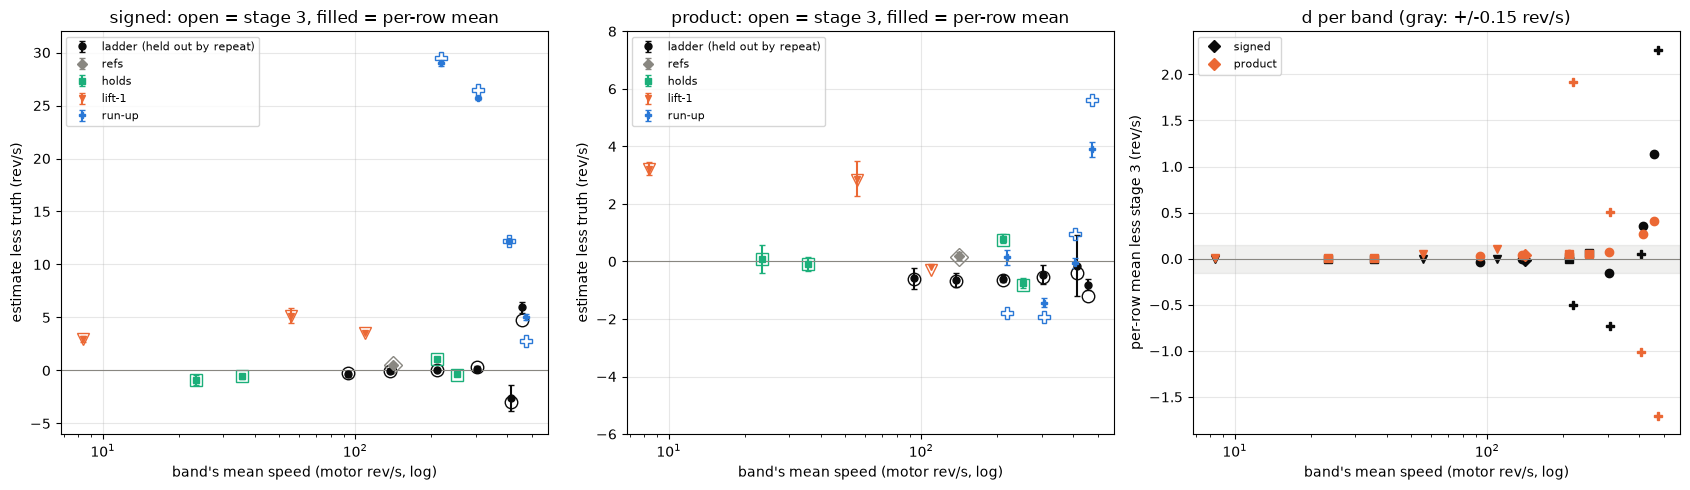

In [27]:
style = {"ladder (held out by repeat)": (INK, "o"), "refs": (MUTED, "D"),
         "holds": (GREEN, "s"), "lift-1": (ORANGE, "v"),
         "run-up": (BLUE, "P")}
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for j, form in enumerate(("signed", "product")):
    g = whole[whole["form"] == form]
    for name, (c, mk) in style.items():
        q = g[g["set"] == name]
        ax[j].plot(q["rev_s"], q["s3_bias"], ls="none", marker=mk,
                   mfc="none", mec=c, ms=9)
        ax[j].errorbar(q["rev_s"], q["row_bias"], yerr=q["row_se"], fmt=mk,
                       color=c, ms=5, capsize=2, label=name)
    ax[j].axhline(0, color=MUTED, lw=0.8)
    ax[j].set_xscale("log")
    ax[j].set_ylim(-6, 32 if form == "signed" else 8)
    ax[j].legend(fontsize=8, loc="upper left")
    figures.label(ax[j], x="band's mean speed (motor rev/s, log)",
                  y="estimate less truth (rev/s)",
                  title=f"{form}: open = stage 3, filled = per-row mean")
for form, c in (("signed", INK), ("product", ORANGE)):
    g = whole[whole["form"] == form]
    for name, (_, mk) in style.items():
        q = g[g["set"] == name]
        ax[2].plot(q["rev_s"], q["d_mean"], ls="none", marker=mk, color=c,
                   ms=6, label=form if name == "refs" else None)
ax[2].axhline(0, color=MUTED, lw=0.8)
ax[2].axhspan(-0.15, 0.15, color=MUTED, alpha=0.12)
ax[2].set_xscale("log")
ax[2].legend(fontsize=8)
figures.label(ax[2], x="band's mean speed (motor rev/s, log)",
              y="per-row mean less stage 3 (rev/s)",
              title="d per band (gray: +/-0.15 rev/s)")
figures.finish(fig)

What you are looking at. Left and middle, each set's bias by band for the signed table and the product form, stage 3's window solve as open marks and the mean of the per-row solve as filled marks with their standard error. Right, the difference between the two per band, with a band of +/-0.15 rev/s in gray. The run-ups carry the row-to-row L di/dt term.

## 3. What each input costs

A controller has other inputs than stage 3's. Each is swapped in alone with stage 3's zero kept, and the change of the window's per-row mean is read by set and band for the signed table, with the product form's mean beside it.

- The rail for the edge lags from the row's own V_on instead of the sweep's probe.
- k_d = 0 instead of the ladder's candidate.
- The causal L di/dt from the row before on the steady windows (the run-ups carry it already).

In [28]:
SETS_B = (("ladder", FIT, {}), ("refs", REFS, {}), ("holds", HOLDS, {}),
          ("run-up", RU, dict(with_l=True, runup=True)), ("lift-1", LIFT1, {}))
rows_b = []
for name, W, kw in SETS_B:
    base = per_row(W, TABLE3_CLIP, TABLE3_SIGN, **kw)
    alts = {"rail from the row's V_on": per_row(
                W, TABLE3_CLIP, TABLE3_SIGN, rail="row", **kw),
            "k_d = 0": per_row(W, TABLE3_CLIP, TABLE3_SIGN, motor=MOTOR, **kw)}
    if name != "run-up":
        alts["L di/dt on (causal)"] = per_row(
            W, TABLE3_CLIP, TABLE3_SIGN, with_l=True, **kw)
    for what, alt in alts.items():
        for band, g in W.groupby("band"):
            if band == "other":
                continue
            x = g.index
            dlt = (alt.loc[x, "w_signed"] - base.loc[x, "w_signed"]).to_numpy()
            dp = alt.loc[x, "w_product"] - base.loc[x, "w_product"]
            rows_b.append({
                "input": what, "set": name, "band": band, "n": len(g),
                "d_mean": dlt.mean(),
                "d_sd": dlt.std(ddof=1) if len(g) > 1 else np.nan,
                "d_max": np.abs(dlt).max(), "d_product_mean": dp.mean(),
                "row_sd_base": base.loc[x, "sd_signed"].mean(),
                "row_sd_alt": alt.loc[x, "sd_signed"].mean()})
INPUTS = pd.DataFrame(rows_b)
INPUTS["o"] = INPUTS["band"].map(ORDER)
INPUTS = (INPUTS.sort_values(["input", "set", "o"], kind="stable")
          .drop(columns="o").reset_index(drop=True))
print(INPUTS.round(3).to_string(index=False))

                   input    set    band    n  d_mean  d_sd  d_max  d_product_mean  row_sd_base  row_sd_alt
     L di/dt on (causal)  holds    0-30   18  -0.000 0.003  0.006           0.001        3.955       6.160
     L di/dt on (causal)  holds  30-100   57  -0.004 0.005  0.019           0.002        4.945       7.544
     L di/dt on (causal)  holds 160-250   24  -0.020 0.085  0.247           0.025       10.483      24.812
     L di/dt on (causal)  holds 250-350    2   0.096 0.030  0.117           0.020       10.864      26.116
     L di/dt on (causal) ladder  30-100   13  -0.005 0.013  0.026          -0.004        8.470      13.870
     L di/dt on (causal) ladder 100-160   18  -0.038 0.046  0.116           0.018        9.598      18.109
     L di/dt on (causal) ladder 160-250   18   0.014 0.057  0.095           0.038       10.712      25.146
     L di/dt on (causal) ladder 250-350   18  -0.655 0.097  0.772           0.072       11.230      33.377
     L di/dt on (causal) ladder 350-4

None of the three inputs is a term to carry. The rail from the row's own V_on moves the window's estimate by +0.022 to +0.075 rev/s, a few hundredths, with no window over 0.20. k_d = 0 changes nothing under 350 rev/s on the free shaft, where the ladder's spins carry no dropouts, and +1.267 rev/s at 350-450 (sd 2.042). In the run-ups it reads +0.608, +1.357, +2.973 and +3.675 rev/s higher by band, inside the run-ups' own spread. The causal L di/dt from the row before is worth nothing at steady speed on average (the ladder's -0.655 at 250-350 and +2.341 on the top rung are most likely the ripple carried through the table's bend) and multiplies the rows' sd inside a window, from 8.5, 9.6, 10.7 and 11.2 rev/s to 13.9, 18.1, 25.1 and 33.4 on the ladder's bands under 350 rev/s and to 61.2 and 61.4 on the top rungs. The L term from a two-row difference is not usable per row. Its filter is section 8's.

### The tracked zero in place of the coast's

The last input is the zero. Stage 3 read it from each sweep's coast tail, which looks ahead. A controller reads the tracked zero of section 1. On every set the window's estimate with the tracked zero is set against the same with the coast tail. dz is the tracked zero less the tail in counts, dw the change of the window's estimate in rev/s (signed table), each by band and by state, warm or after a start (a cold sweep or the first after a rail move). The score against the truth with each zero is beside them. The current-zero notebook's design runs the same way.

In [29]:
ZEROS = {"tracked (gate 30 %, coast, torque off)": Z_TRACK,
         "the design (current-zero's)": Z_DESIGN}
rows_c, per_win = [], []
for name, W, kw in SETS_B:
    base = per_row(W, TABLE3_CLIP, TABLE3_SIGN, **kw)
    for zname, z in ZEROS.items():
        alt = per_row(W, TABLE3_CLIP, TABLE3_SIGN, z=z, **kw)
        per_win.append(pd.DataFrame({
            "set": name, "zero": zname, "band": W["band"], "cls": W["cls"],
            "truth": W["truth"], "sweep": W["sweep"],
            "dz_counts": alt["zero"] - base["zero"],
            "dw_signed": alt["w_signed"] - base["w_signed"],
            "dw_product": alt["w_product"] - base["w_product"],
            "e_signed_s3zero": base["w_signed"] - W["truth"],
            "e_signed": alt["w_signed"] - W["truth"],
            "e_product_s3zero": base["w_product"] - W["truth"],
            "e_product": alt["w_product"] - W["truth"]}))
PW = pd.concat(per_win, ignore_index=True)
PW["state"] = np.where(PW["cls"] == "warm", "warm", "after a start")
print(f"{len(PW)} window scores, {PW['sweep'].nunique()} sweeps")

7542 window scores, 142 sweeps


In [30]:
def rms_of(x):
    return float(np.sqrt((np.asarray(x, float) ** 2).mean()))


for (zname, name, band, st), g in PW.groupby(["zero", "set", "band",
                                              "state"]):
    if band == "other":
        continue
    a = stats(g["dw_signed"], g["truth"])
    rows_c.append({
        "zero": zname, "set": name, "band": band, "state": st, "n": a["n"],
        "sweeps": g["sweep"].nunique(), "rev_s": g["truth"].mean(),
        "dz_mean": g["dz_counts"].mean(), "dz_rms": rms_of(g["dz_counts"]),
        "dw_mean": a["bias"], "dw_sd": a["sd"], "dw_rms": a["rms"],
        "dw_worst": g["dw_signed"].abs().max(), "dw_mean_pct": a["bias_pct"],
        "dw_rms_pct": a["rms_pct"],
        "dw_product_mean": g["dw_product"].mean(),
        "dw_product_rms": rms_of(g["dw_product"]),
        "rms_s3zero": rms_of(g["e_signed_s3zero"]),
        "rms_tracked": rms_of(g["e_signed"]),
        "bias_s3zero": g["e_signed_s3zero"].mean(),
        "bias_tracked": g["e_signed"].mean()})
ZC = pd.DataFrame(rows_c)
ZC["o"] = ZC["band"].map(ORDER)
ZC = (ZC.sort_values(["zero", "set", "o", "state"], kind="stable")
      .drop(columns="o").reset_index(drop=True))
cols = ["set", "band", "state", "n", "sweeps", "rev_s", "dz_mean", "dz_rms",
        "dw_mean", "dw_sd", "dw_rms", "dw_worst", "dw_rms_pct",
        "bias_s3zero", "bias_tracked", "rms_s3zero", "rms_tracked"]
for zname in ZEROS:
    print(f"zero: {zname}")
    print(ZC[ZC["zero"] == zname][cols].round(3).to_string(index=False))

zero: tracked (gate 30 %, coast, torque off)
   set    band         state    n  sweeps   rev_s  dz_mean  dz_rms  dw_mean  dw_sd  dw_rms  dw_worst  dw_rms_pct  bias_s3zero  bias_tracked  rms_s3zero  rms_tracked
 holds    0-30          warm   18      11  23.425    0.571   0.701    0.303  0.222   0.372     0.836       1.531       -0.901        -0.598       2.191        1.965
 holds  30-100 after a start    6       3  41.023    0.723   0.835    0.383  0.243   0.443     0.721       1.086       -0.398        -0.015       1.047        0.867
 holds  30-100          warm   51      27  34.923    0.740   0.918    0.393  0.291   0.488     1.162       1.456       -0.588        -0.195       1.802        1.665
 holds 160-250          warm   24      13 210.383    0.767   0.895    0.387  0.240   0.453     0.949       0.220        1.103         1.490       1.265        1.642
 holds 250-350          warm    2       2 253.576    0.827   0.891    0.422  0.240   0.455     0.592       0.181       -0.354     

The same, pooled over every window of a state, with the change per sweep and the speed one count of zero is worth.

In [31]:
for zname in ZEROS:
    print(f"zero: {zname}")
    g = PW[PW["zero"] == zname]
    for st, gg in g.groupby("state"):
        k = (gg["dw_signed"] / gg["dz_counts"]).replace([np.inf, -np.inf],
                                                         np.nan)
        ps = gg.groupby("sweep")["dw_signed"].mean()
        print(f"  {st}: {len(gg)} windows in {gg['sweep'].nunique()} sweeps;"
              f" dz mean {gg['dz_counts'].mean():+.2f} rms "
              f"{rms_of(gg['dz_counts']):.2f} counts; dw mean "
              f"{gg['dw_signed'].mean():+.3f} rms {rms_of(gg['dw_signed']):.3f}"
              f" worst {gg['dw_signed'].abs().max():.2f} rev/s; by sweep mean"
              f" {ps.mean():+.3f} sd {ps.std(ddof=1):.3f} (se "
              f"{ps.std(ddof=1) / np.sqrt(len(ps)):.3f}); rev/s per count "
              f"(median) {k.median():+.3f}; product dw rms "
              f"{rms_of(gg['dw_product']):.3f}")
PW_TRACK = PW[PW["zero"] == list(ZEROS)[0]]
for name in ("ladder", "run-up", "holds", "lift-1", "refs"):
    g = PW_TRACK[PW_TRACK["set"] == name]
    print(f"classes in {name}: " + ", ".join(
        f"{c} {n}" for c, n in g.groupby("cls")["sweep"].nunique().items())
        + " sweeps")

zero: tracked (gate 30 %, coast, torque off)
  after a start: 16 windows in 8 sweeps; dz mean +0.42 rms 2.11 counts; dw mean +0.252 rms 0.936 worst 2.37 rev/s; by sweep mean +0.252 sd 0.898 (se 0.318); rev/s per count (median) +0.517; product dw rms 1.193
  warm: 3755 windows in 134 sweeps; dz mean +0.32 rms 0.61 counts; dw mean +0.153 rms 0.288 worst 1.16 rev/s; by sweep mean +0.302 sd 0.220 (se 0.019); rev/s per count (median) +0.471; product dw rms 0.336
zero: the design (current-zero's)
  after a start: 16 windows in 8 sweeps; dz mean +0.06 rms 0.30 counts; dw mean +0.029 rms 0.148 worst 0.31 rev/s; by sweep mean +0.029 sd 0.118 (se 0.042); rev/s per count (median) +0.519; product dw rms 0.165
  warm: 3755 windows in 134 sweeps; dz mean +0.00 rms 0.48 counts; dw mean +0.002 rms 0.227 worst 0.81 rev/s; by sweep mean +0.049 sd 0.192 (se 0.017); rev/s per count (median) +0.471; product dw rms 0.266
classes in ladder: rail moved 3, warm 40 sweeps
classes in run-up: warm 18 sweeps
class

Two summaries. The score's rms against the truth with the tracked zero, less the same with the coast tail, over the warm windows of the free-shaft sets (ladder, references, holds, lift-1). And the cold start, which no window here covers. The tracker's own error at a cold start is read from the drive runs of every sweep, each against its coast tail as `oscnb.zero` scores them, and turned into speed with the median speed per count of zero of these windows.

In [32]:
free = ZC[(ZC["zero"] == list(ZEROS)[0]) & (ZC["state"] == "warm")
          & ZC["set"].isin(["ladder", "refs", "holds", "lift-1"])]
moved = free["rms_tracked"] - free["rms_s3zero"]
print(f"warm free-shaft windows ({int(free['n'].sum())}): score rms moves "
      f"{moved.min():+.2f} to {moved.max():+.2f} rev/s with the tracked zero")
STORE_T = zero.with_truth(STORE)
k_all = (PW_TRACK["dw_signed"] / PW_TRACK["dz_counts"]).replace(
    [np.inf, -np.inf], np.nan)
REV_S_PER_COUNT = float(k_all.median())     # rev/s per count of zero
COLD_Z = {}
for rname, rule in (("stage 1", zero.Rule()), ("design", DESIGN_RULE)):
    runs = zero.classes(zero.score(rule, STORE_T), SW, HALF_COUNT_V,
                        LONG_GAP_S)
    for c, g in runs[runs["truth"].notna()].groupby("cls"):
        e = g["err_mean"].to_numpy()        # the run-mean error, counts
        v = COLD_Z[f"{rname}, {c}"] = dict(
            runs=len(g), sweeps=g["sweep"].nunique(), rms=rms_of(e),
            worst=e[np.argmax(np.abs(e))])
        print(f"{rname}, {c}: {v['runs']} runs in {v['sweeps']} sweeps, "
              f"run-mean error rms {v['rms']:.2f} counts, worst "
              f"{v['worst']:+.2f}; x {REV_S_PER_COUNT:.3f} rev/s per count "
              f"= {v['rms'] * REV_S_PER_COUNT:.2f} rms, worst "
              f"{abs(v['worst']) * REV_S_PER_COUNT:.2f} rev/s")

warm free-shaft windows (309): score rms moves -0.23 to +0.38 rev/s with the tracked zero


stage 1, cold: 21 runs in 7 sweeps, run-mean error rms 1.67 counts, worst -4.04; x 0.471 rev/s per count = 0.79 rms, worst 1.90 rev/s
stage 1, rail moved: 43 runs in 10 sweeps, run-mean error rms 2.24 counts, worst +7.20; x 0.471 rev/s per count = 1.05 rms, worst 3.39 rev/s
stage 1, warm: 911 runs in 226 sweeps, run-mean error rms 0.73 counts, worst +2.45; x 0.471 rev/s per count = 0.34 rms, worst 1.16 rev/s
design, cold: 21 runs in 7 sweeps, run-mean error rms 0.31 counts, worst +0.67; x 0.471 rev/s per count = 0.15 rms, worst 0.32 rev/s
design, rail moved: 43 runs in 10 sweeps, run-mean error rms 0.36 counts, worst +1.47; x 0.471 rev/s per count = 0.17 rms, worst 0.69 rev/s
design, warm: 911 runs in 226 sweeps, run-mean error rms 0.41 counts, worst +1.79; x 0.471 rev/s per count = 0.19 rms, worst 0.84 rev/s


Stage 1's tracker costs little when warm. Over 3755 warm windows in 134 sweeps it sits +0.32 counts above the coast tail, 0.61 counts rms, and moves the estimate by +0.302 rev/s per sweep (sd 0.220, se 0.019), with a worst window of 1.16 rev/s. By band it is +0.30 and +0.39 rev/s on the holds at 0-30 and 30-100, +0.42 to +0.21 on the ladder and +0.13 to +0.15 in the run-ups, where nothing feeds the zero at 100 %. One count of zero is worth 0.471 rev/s on the warm windows and 0.517 after a start. Against the truth the score's rms moves -0.23 to +0.38 rev/s on the 309 warm free-shaft windows, so no grade of sections 2 and 4 changes its ranking with the zero (high confidence, 134 sweeps).

After a start stage 1's tracker has not converged. The 16 windows in 8 sweeps that follow a rail move read 0.936 rev/s rms and 2.37 rev/s in the worst, a ladder spin at 437.7 rev/s whose zero sat 5.99 counts under the tail (moderate confidence, 8 sweeps). No window here follows a cold start. Over the 21 drive runs of the 7 cold sweeps the tracker's own error is 1.67 counts rms and -4.04 counts in the worst, about 0.79 rev/s rms and 1.90 rev/s in the worst at 0.471 rev/s per count (low confidence, derived and not scored on windows).

The design takes most of both away. Warm, it moves the estimate by +0.049 rev/s per sweep (sd 0.192, se 0.017), +0.00 counts from the coast tail on average and 0.48 counts rms, with a worst window of 0.81 rev/s. After a rail move its 16 windows read 0.148 rev/s rms and 0.31 rev/s in the worst. Over the drive runs it reads 0.31 counts rms on the cold sweeps (worst +0.67) and 0.36 after a rail move (worst +1.47), about 0.15 and 0.17 rev/s. Its constants come from the current-zero notebook's result.

## 4. The brush term's two forms side by side

The brush term has two forms, both fitted to X = u - Ke x truth.

- The table, the signed speed table $V_b(\omega, \text{dir})$, X's rung means per direction at stage 3's knots, not clipped at zero.
- The product, $V_b = c_0 + c_{dir}\,[\text{dir} = +1] + b\,\omega\,i_w$, by least squares.

From here on the estimate is the controller's, with `k_d = 0`, the row's V_on for the edge lags, the NTC from the sweep's probe. L di/dt appears only in the run-ups, as the slope over the last `L_ROWS` rows (causal), a stand-in for the filter of section 8. Dropout rows are left out of the run-ups' row scores. Each form is fitted on part of the data and scored on the rest. The ladder is graded by repeat. Then each form is fitted on the whole free ladder and scored on everything else. The zero is the sweep's coast tail (the baseline plus the awake line where a sweep has no coast), with the tracked zero beside it.

`SetRows` holds one set's rows with u and the current per row under one zero.

In [33]:
L_ROWS = 100            # rows, the run-ups' causal L slope (5 ms)


class SetRows:
    """A set's rows: u and i_w per row under one zero ('tail' or
    'tracked'), the controller's inputs."""

    def __init__(self, W, zero="tail", runup=False):
        self.W, self.runup = W, runup
        self.R = R = Rows(W, DROPPED if runup else None)
        z = R.per_row("zero_s3") if zero == "tail" else Z_TRACK[R.idx]
        self.u, self.i = signals(R, z, MOTOR, rail="row",
                                 with_l=L_ROWS if runup else False,
                                 rate=False)
        self.um, self.im = R.mean(self.u), R.mean(self.i)  # window means
        self.truth_rows = R.per_row("truth")
        self.band_rows = W["band"].to_numpy()[R.wid]

    def solve(self, form):
        """The per-row speed under a brush form."""
        if isinstance(form, speed.BrushProduct):
            return speed.solve_product(self.u, self.i, self.R.d, form, KE)
        return speed.solve_bisect(self.u, self.R.d, form, KE)


def fit_product(x_v, w, i_w, d, wt=None):
    """(BrushProduct, se) by least squares of X on [1, dir +1, w i_w]."""
    A = np.column_stack([np.ones(len(w)), (np.asarray(d) == 1).astype(float),
                         np.asarray(w) * np.asarray(i_w)])
    wt = np.ones(len(w)) if wt is None else wt
    Aw = A * wt[:, None]
    beta, *_ = np.linalg.lstsq(Aw, x_v * wt, rcond=None)
    res = (x_v - A @ beta) * wt
    cov = np.linalg.pinv(Aw.T @ Aw) * (res @ res / (len(w) - 3))
    return speed.BrushProduct(*beta), np.sqrt(np.diag(cov))

The fits. On the ladder by repeat, each form on two repeats, the third held out. Then each on the whole free ladder, 85 spins, which is the pair of forms the rest of the notebook carries.

In [34]:
S_FIT = {z: SetRows(FIT, z) for z in ("tail", "tracked")}
X_FIT = S_FIT["tail"].um - KE * FIT["truth"].to_numpy()     # V
FOLD_FORMS, consts = [], []
for rep in sorted(FIT["repeat"].unique()):
    tr = (FIT["repeat"] != rep).to_numpy()
    tab = fit_table(FIT[tr], S_FIT["tail"].um[tr], clip=False)
    prod, se = fit_product(X_FIT[tr], FIT["truth"].to_numpy()[tr],
                           S_FIT["tail"].im[tr], FIT["dir"].to_numpy()[tr])
    FOLD_FORMS.append((int(rep), tab, prod))
    consts.append({"fold": int(rep), "c0_mv": prod.c0_v * 1e3,
                   "c_dir_mv": prod.c_dir_v * 1e3,
                   "b_mv_per_rev_s_a": prod.b_v_per_rev_s_a * 1e3,
                   "se_c0": se[0] * 1e3, "se_c_dir": se[1] * 1e3,
                   "se_b": se[2] * 1e3})
FOLDS = pd.DataFrame(consts)
print(FOLDS.round(3).to_string(index=False))

 fold   c0_mv  c_dir_mv  b_mv_per_rev_s_a  se_c0  se_c_dir  se_b
    0 -40.754    11.829             2.053  3.791     4.297 0.064
    1 -41.232    13.479             2.090  3.188     3.669 0.055
    2 -39.333    11.871             2.033  3.467     3.998 0.060


In [35]:
TAB_FORM = fit_table(FIT, S_FIT["tail"].um, clip=False)   # the table
RUNGS = rung_means(FIT, X_FIT * 1e3)
TAB_CLIP = table_from_rungs(RUNGS, clip=True)   # a control, not a form
PROD_FORM, SE_PROD = fit_product(X_FIT, FIT["truth"].to_numpy(),
                                 S_FIT["tail"].im, FIT["dir"].to_numpy())
p, w_f = PROD_FORM, FIT["truth"].to_numpy()
res_l = (X_FIT - (p.c0_v + p.c_dir_v * (FIT["dir"].to_numpy() == 1)
                  + p.b_v_per_rev_s_a * w_f * S_FIT["tail"].im)) * 1e3
print(f"product, whole free ladder ({len(FIT)} spins, k_d = 0): c0 "
      f"{p.c0_v * 1e3:+.2f} +/- {SE_PROD[0] * 1e3:.2f} mV, c_dir "
      f"{p.c_dir_v * 1e3:+.2f} +/- {SE_PROD[1] * 1e3:.2f} mV, b "
      f"{p.b_v_per_rev_s_a * 1e3:.4f} +/- {SE_PROD[2] * 1e3:.4f} mV per "
      f"(rev/s x A); rms {np.sqrt((res_l ** 2).mean()):.1f} mV, under 350 "
      f"rev/s {np.sqrt((res_l[w_f < 350] ** 2).mean()):.1f} mV")
(kp, tp), (kn, tn) = TAB_FORM.clean()
for d, k, t in ((+1, kp, tp), (-1, kn, tn)):
    print(f"signed table, dir {d:+d} (mV): "
          + " ".join(f"{a:.0f}:{v * 1e3:+.0f}" for a, v in zip(k, t)))
im = S_FIT["tail"].im
print(f"the ladder's own current {im.min() * 1e3:.0f} to {im.max() * 1e3:.0f}"
      f" mA at {w_f.min():.0f} to {w_f.max():.0f} rev/s; corr(w, i_w) "
      f"{np.corrcoef(w_f, im)[0, 1]:.3f}")

product, whole free ladder (85 spins, k_d = 0): c0 -40.43 +/- 2.83 mV, c_dir +12.39 +/- 3.24 mV, b 2.0584 +/- 0.0485 mV per (rev/s x A); rms 14.7 mV, under 350 rev/s 7.7 mV
signed table, dir +1 (mV): 50:-24 100:-14 150:-8 200:+13 250:+29 300:+53 350:+100 400:+131 450:+369
signed table, dir -1 (mV): 50:-19 100:-15 150:-8 200:-0 250:+13 300:+20 350:+67 400:+103 450:+163
the ladder's own current 64 to 289 mA at 82 to 458 rev/s; corr(w, i_w) 0.902


### The scores

Each form's error is kept per window (the mean of the window's rows less the truth) and per row (each row less its window's truth), for the pooled table below. The ladder's third repeat is scored on the forms of the other two. The references, the free holds, the run-ups, the lifts of the three load sittings and the load holds at rest are scored on the forms fitted on the whole free ladder, with stage 3's clipped table beside them as a control, not a contender. Every set is scored twice, with the coast-tail zero and with the tracked zero.

In [36]:
WIN, ROWACC = [], {}    # per-window errors; per-row errors by key


def score(S, forms, fit, name, zero, sub=None):
    """Keep each form's error per window and per row of SetRows S, on
    the windows `sub` (all by default)."""
    W, R = S.W, S.R
    sel = np.ones(len(W), bool) if sub is None else sub
    rows_sel = sel[R.wid] & R.keep              # the rows that count
    keep = W.loc[sel, ["set", "k", "dir", "band", "truth", "sweep"]].copy()
    keep["fit"], keep["name"], keep["zero"] = fit, name, zero
    keep["i_a"] = S.im[sel]                     # A, the window's current
    for fname, form in forms.items():
        w = S.solve(form)                       # rev/s per row
        keep["e_" + fname] = R.mean(w)[sel] - W["truth"].to_numpy()[sel]
        ROWACC.setdefault((fit, name, zero, fname), []).append(
            (w[rows_sel] - S.truth_rows[rows_sel], S.truth_rows[rows_sel],
             S.band_rows[rows_sel]))
    WIN.append(keep)


for rep, tab, prod in FOLD_FORMS:               # the ladder by repeat
    te = (FIT["repeat"] == rep).to_numpy()      # the held-out repeat
    for z in ("tail", "tracked"):
        score(S_FIT[z], {"table": tab, "product": prod},
              "ladder, two repeats", "ladder (third repeat)", z, te)
OUT_SETS = (("refs", REFS, False), ("holds (free, low)", HOLDS, False),
            ("run-up", RU, True), ("lifts", LIFTS, False),
            ("load holds", LOADH, False))
SR = {}                                         # (set, zero) -> SetRows
for name, W, runup in OUT_SETS:
    for z in ("tail", "tracked"):
        SR[name, z] = SetRows(W, z, runup)
        score(SR[name, z], {"table": TAB_FORM, "product": PROD_FORM,
                            "table, clipped": TAB_CLIP},
              "ladder alone", name, z)
print(len(WIN), "scored blocks,", len(ROWACC), "row keys")

16 scored blocks, 34 row keys


### The product form with run-ups in its fit

Stage 3 also fitted the product form on the ladder and the run-ups together. Here that fit is held out by sitting. The ladder and the run-ups of two sittings are fitted and the third sitting's run-ups scored. The slower run-up turns enter with stage 3's weight, about 100 spins' worth in all.

In [37]:
S_RU = SR["run-up", "tail"]
x_ru = S_RU.um - KE * RU["truth"].to_numpy()        # V, X per run-up turn
lo460 = (RU["truth"] < 460).to_numpy()


def fit_with_runups(tr):
    """The product form on the ladder plus the run-up turns `tr`."""
    wt = np.r_[np.ones(len(FIT)),                  # stage 3's weight
               np.full(tr.sum(), 1 / np.sqrt(tr.sum() / 100))]
    return fit_product(
        np.r_[X_FIT, x_ru[tr]],
        np.r_[FIT["truth"].to_numpy(), RU["truth"].to_numpy()[tr]],
        np.r_[S_FIT["tail"].im, S_RU.im[tr]],
        np.r_[FIT["dir"].to_numpy(), RU["dir"].to_numpy()[tr]], wt)


for sit in sorted(RU["sitting"].unique()):
    tr = (RU["sitting"] != sit).to_numpy() & lo460
    prod, se = fit_with_runups(tr)
    print(f"sitting {sit} left out: c0 {prod.c0_v * 1e3:+.2f} mV, c_dir "
          f"{prod.c_dir_v * 1e3:+.2f} mV, b {prod.b_v_per_rev_s_a * 1e3:.4f}"
          f" +/- {se[2] * 1e3:.4f}")
    for z in ("tail", "tracked"):
        score(SR["run-up", z], {"product": prod},
              "ladder + run-ups of two sittings", "run-up (sitting left out)",
              z, (RU["sitting"] == sit).to_numpy())
PROD_LR, SE_LR = fit_with_runups(lo460)
print(f"run-up turns under 460 rev/s in the fits: {int(lo460.sum())} of "
      f"{len(RU)}")
print(f"ladder + every run-up (k_d = 0): c0 {PROD_LR.c0_v * 1e3:+.2f} +/- "
      f"{SE_LR[0] * 1e3:.2f} mV, c_dir {PROD_LR.c_dir_v * 1e3:+.2f} +/- "
      f"{SE_LR[1] * 1e3:.2f} mV, b {PROD_LR.b_v_per_rev_s_a * 1e3:.4f} +/- "
      f"{SE_LR[2] * 1e3:.4f} mV per (rev/s x A)")
for name in ("refs", "holds (free, low)", "lifts", "load holds"):
    for z in ("tail", "tracked"):
        score(SR[name, z], {"product": PROD_LR}, "ladder + run-ups", name, z)

sitting 1 left out: c0 -47.98 mV, c_dir +39.58 mV, b 2.0533 +/- 0.0187
sitting 6 left out: c0 -44.49 mV, c_dir +32.22 mV, b 2.0368 +/- 0.0184
sitting 7 left out: c0 -46.94 mV, c_dir +36.33 mV, b 2.0668 +/- 0.0187
run-up turns under 460 rev/s in the fits: 2417 of 3446
ladder + every run-up (k_d = 0): c0 -46.45 +/- 1.92 mV, c_dir +36.02 +/- 1.80 mV, b 2.0522 +/- 0.0153 mV per (rev/s x A)


The pooled table. Per fit, set, band, zero and form, the bias, its standard error over windows, the sd and the rms, at the window level and at the row level.

In [38]:
WN = pd.concat(WIN, ignore_index=True)          # every window's errors
FORM_COLS = [c for c in WN.columns if c.startswith("e_")]
rows_sc = []
for (fit, name, zero, band), g in WN.groupby(["fit", "name", "zero", "band"]):
    if band == "other":
        continue
    for col in FORM_COLS:
        if g[col].isna().all():
            continue
        fname = col[2:]
        a = stats(g[col], g["truth"])
        base = {"form": fname, "fit": fit, "set": name, "band": band,
                "zero": zero, "rev_s": g["truth"].mean(),
                "i_a": g["i_a"].mean(), "sweeps": g["sweep"].nunique()}
        rows_sc.append({**base, "level": "window", "n": a["n"],
                        "bias": a["bias"], "se": a["se"], "sd": a["sd"],
                        "rms": a["rms"], "rms_pct": a["rms_pct"]})
        acc = ROWACC[fit, name, zero, fname]
        e = np.concatenate([x[0][x[2] == band] for x in acc])
        t = np.concatenate([x[1][x[2] == band] for x in acc])
        rows_sc.append({**base, "level": "row", "n": len(e),
                        "bias": e.mean(), "se": a["se"],
                        "sd": e.std(ddof=1), "rms": np.sqrt((e ** 2).mean()),
                        "rms_pct": np.sqrt(((e / t) ** 2).mean()) * 100})
SC = pd.DataFrame(rows_sc)
SC["o"] = SC["band"].map(ORDER)
SC = (SC.sort_values(["zero", "fit", "set", "o", "form", "level"],
                     kind="stable").drop(columns="o").reset_index(drop=True))
print(len(SC), "rows in the pooled table")

256 rows in the pooled table


Side by side, with the coast-tail zero. Per window, the bias +/- its standard error / the rms, and the per-row rms in brackets, rev/s.

In [39]:
side = []
tail = SC[SC["zero"] == "tail"]
for (fit, name, band), g in tail.groupby(["fit", "set", "band"], sort=False):
    win = g[g["level"] == "window"]
    r = {"fit": fit, "set": name, "band": band, "n": int(win["n"].iloc[0]),
         "rev_s": round(g["rev_s"].iloc[0], 1),
         "mA": round(g["i_a"].iloc[0] * 1e3)}
    for fname in ("table", "product", "table, clipped"):
        w_ = win[win["form"] == fname]
        r_ = g[(g["form"] == fname) & (g["level"] == "row")]
        r[fname] = (f"{w_['bias'].iloc[0]:+.2f}+/-{w_['se'].iloc[0]:.2f} / "
                    f"{w_['rms'].iloc[0]:.2f} [{r_['rms'].iloc[0]:.1f}]"
                    if len(w_) else "")
    side.append(r)
SIDE = pd.DataFrame(side)
print(SIDE.to_string(index=False))

                             fit                       set    band    n  rev_s  mA                        table                     product               table, clipped
                ladder + run-ups         holds (free, low)    0-30   18   23.4  39                                +0.46+/-0.68 / 2.83 [4.9]                             
                ladder + run-ups         holds (free, low)  30-100   57   35.6  42                                -0.14+/-0.37 / 2.78 [5.7]                             
                ladder + run-ups         holds (free, low) 160-250   24  210.4  98                               +0.46+/-0.38 / 1.89 [11.8]                             
                ladder + run-ups         holds (free, low) 250-350    2  253.6 105                               +0.42+/-0.17 / 0.46 [12.1]                             
                ladder + run-ups                     lifts    0-30  154   11.5 195                                +3.49+/-0.25 / 4.66 [6.6]                

The per-row noise of the two forms on the ladder's held-out repeat, product over table, band by band.

In [40]:
lad_rows = tail[(tail["set"] == "ladder (third repeat)")
                & (tail["level"] == "row")]
ratio = (lad_rows[lad_rows["form"] == "product"].set_index("band")["rms"]
         / lad_rows[lad_rows["form"] == "table"].set_index("band")["rms"])
print("per-row rms, product over table:",
      {b: round(v, 2) for b, v in ratio.items()})

per-row rms, product over table: {'30-100': 1.03, '100-160': 1.06, '160-250': 1.1, '250-350': 1.2, '350-450': 1.37, '450-600': 1.16}


### Paired, per window

The two forms on the same windows. Per window, |error| of the table less |error| of the product, averaged per sweep, with its standard error over sweeps. Positive means the product is closer.

In [41]:
pairs = []
g0 = WN[(WN["zero"] == "tail")
        & WN["fit"].isin(["ladder, two repeats", "ladder alone"])]
for (fit, name, band), g in g0.groupby(["fit", "name", "band"]):
    if band == "other" or g["e_table"].isna().all():
        continue
    dlt = g["e_table"].abs() - g["e_product"].abs()
    by = dlt.groupby(g["sweep"]).mean()         # one value per sweep
    se = by.std(ddof=1) / np.sqrt(len(by)) if len(by) > 1 else np.nan
    pairs.append({
        "fit": fit, "set": name, "band": band, "windows": len(g),
        "sweeps": len(by), "rev_s": g["truth"].mean(), "i_a": g["i_a"].mean(),
        "bias_table": g["e_table"].mean(),
        "bias_product": g["e_product"].mean(),
        "rms_table": np.sqrt((g["e_table"] ** 2).mean()),
        "rms_product": np.sqrt((g["e_product"] ** 2).mean()),
        "d_abs": by.mean(), "se": se,
        "sigma": by.mean() / se if se and np.isfinite(se) and se > 0
        else np.nan})
PR = pd.DataFrame(pairs)
PR["o"] = PR["band"].map(ORDER)
PR = (PR.sort_values(["fit", "set", "o"], kind="stable").drop(columns="o")
      .reset_index(drop=True))
print(PR.round(3).to_string(index=False))

                fit                   set    band  windows  sweeps   rev_s   i_a  bias_table  bias_product  rms_table  rms_product  d_abs    se  sigma
       ladder alone     holds (free, low)    0-30       18      11  23.425 0.039      -0.882         0.889      2.139        2.115 -0.444 0.482 -0.921
       ladder alone     holds (free, low)  30-100       57      30  35.565 0.042      -0.548         0.727      1.698        1.834 -0.357 0.155 -2.298
       ladder alone     holds (free, low) 160-250       24      13 210.383 0.098       1.118         1.351      1.274        1.517 -0.228 0.034 -6.794
       ladder alone     holds (free, low) 250-350        2       2 253.576 0.105      -0.325        -0.402      0.337        0.435 -0.077 0.077 -0.993
       ladder alone                 lifts    0-30      154      20  11.549 0.195       3.456         4.317      4.437        4.945 -0.254 0.318 -0.800
       ladder alone                 lifts  30-100      142      36  58.568 0.205       5.216  

### Per rung, the ladder held out

The ladder's held-out errors per rung, mean and sd over the repeats, with the share the rung was still settling inside its window.

In [42]:
g = WN[(WN["zero"] == "tail") & (WN["fit"] == "ladder, two repeats")].merge(
    FIT[["set", "k", "dir", "volts_set", "duty_pct", "settle_pct"]],
    on=["set", "k", "dir"])
RG = (g.groupby(["volts_set", g["duty_pct"].round(), "dir"])
      .agg(n=("e_table", "size"), rev_s=("truth", "mean"), i_a=("i_a", "mean"),
           e_table=("e_table", "mean"), sd_table=("e_table", "std"),
           e_product=("e_product", "mean"), sd_product=("e_product", "std"),
           settle_pct=("settle_pct", "mean"))
      .reset_index().sort_values("rev_s").reset_index(drop=True))
print(RG.round(2).to_string(index=False))
flat, top = RG[RG["rev_s"] < 350], RG[RG["rev_s"] >= 350]
FLAT_RUNGS = {"n": len(flat), "table": (flat["e_table"].min(),
                                        flat["e_table"].max()),
              "product": (flat["e_product"].min(), flat["e_product"].max()),
              "table_above": (top["e_table"].min(), top["e_table"].max()),
              "product_above": (top["e_product"].min(),
                                top["e_product"].max())}
print(f"flat band under 350 rev/s ({len(flat)} rungs): table "
      f"{FLAT_RUNGS['table'][0]:+.2f} to {FLAT_RUNGS['table'][1]:+.2f}, "
      f"product {FLAT_RUNGS['product'][0]:+.2f} to "
      f"{FLAT_RUNGS['product'][1]:+.2f} rev/s; above: table "
      f"{FLAT_RUNGS['table_above'][0]:+.2f} to "
      f"{FLAT_RUNGS['table_above'][1]:+.2f}, product "
      f"{FLAT_RUNGS['product_above'][0]:+.2f} to "
      f"{FLAT_RUNGS['product_above'][1]:+.2f}")
above = RG[RG["rev_s"] >= 250]
print(f"rungs from 250 rev/s: still settling by {above['settle_pct'].min():.1f}"
      f" to {above['settle_pct'].max():.1f} % inside the window, by rung:",
      above["settle_pct"].round(1).tolist())

 volts_set  duty_pct  dir  n  rev_s  i_a  e_table  sd_table  e_product  sd_product  settle_pct
       5.0      20.0   -1  1  82.10 0.07     0.52       NaN       1.38         NaN       -2.37
       3.7      30.0    1  3  93.79 0.08    -0.93      0.70      -1.48        0.57       -4.23
       7.4      15.0    1  3  94.01 0.07     0.38      0.27       0.08        0.21        2.18
       3.7      30.0   -1  3  95.74 0.08    -1.41      0.69      -0.34        0.13        0.47
       7.4      15.0   -1  3  96.46 0.06     0.47      1.01       1.82        0.20        0.90
       7.4      20.0    1  3 134.89 0.08     0.04      0.18      -0.64        0.07       -0.99
       5.0      30.0    1  3 136.32 0.09     0.98      0.25       0.09        0.13       -1.41
       3.7      40.0    1  3 137.52 0.09    -0.49      0.32      -1.31        0.12       -0.69
       3.7      40.0   -1  3 137.85 0.09    -0.87      0.21      -0.15        0.07       -0.59
       7.4      20.0   -1  3 138.04 0.08     0.13 

In [43]:
for name in ("run-up", "lifts", "load holds"):
    S = SR[name, "tail"]
    print(f"{name}: {len(S.W)} windows, {S.W['sweep'].nunique()} sweeps, i_w "
          f"{np.percentile(S.im, 5) * 1e3:.0f} to "
          f"{np.percentile(S.im, 95) * 1e3:.0f} mA (5-95 %), truth "
          f"{np.percentile(S.W['truth'], 5):.1f} to "
          f"{np.percentile(S.W['truth'], 95):.1f} rev/s")

run-up: 3446 windows, 18 sweeps, i_w 223 to 608 mA (5-95 %), truth 245.5 to 491.8 rev/s
lifts: 312 windows, 36 sweeps, i_w 130 to 282 mA (5-95 %), truth -0.0 to 100.0 rev/s
load holds: 60 windows, 60 sweeps, i_w 70 to 376 mA (5-95 %), truth -0.1 to 0.0 rev/s


### X at low speed

Where both forms are off, X = u - Ke x truth per window is what the brush term has to equal. By set and band, its mean in mV with the standard error over sweeps, and each form's value at the band's mean speed and current beside it.

In [44]:
xr = []
for name in ("holds (free, low)", "refs", "lifts", "load holds"):
    S = SR[name, "tail"]
    x = (S.um - KE * S.W["truth"].to_numpy()) * 1e3      # mV per window
    for band, g in S.W.groupby("band"):
        if band == "other":
            continue
        m = g.index.to_numpy()
        w_, i_, d_ = g["truth"].mean(), S.im[m].mean(), g["dir"].to_numpy()
        by = pd.Series(x[m]).groupby(g["sweep"].to_numpy()).mean()
        tab_mv = speed.table_eval(TAB_FORM, d_, np.full(len(m), max(w_, 0.0)))
        p = PROD_FORM
        xr.append({
            "set": name, "band": band, "n": len(m), "sweeps": len(by),
            "rev_s": w_, "mA": i_ * 1e3, "x_mv": x[m].mean(),
            "se": by.std(ddof=1) / np.sqrt(len(by)) if len(by) > 1 else np.nan,
            "sd": x[m].std(ddof=1), "table_mv": tab_mv.mean() * 1e3,
            "product_mv": (p.c0_v + p.c_dir_v * (d_ == 1).mean()
                           + p.b_v_per_rev_s_a * w_ * i_) * 1e3})
XR = pd.DataFrame(xr)
XR["o"] = XR["band"].map(ORDER)
XR = (XR.sort_values(["set", "o"], kind="stable").drop(columns="o")
      .reset_index(drop=True))
print(XR.round(2).to_string(index=False))

              set    band   n  sweeps  rev_s     mA   x_mv   se    sd  table_mv  product_mv
holds (free, low)    0-30  18      11  23.43  39.03 -27.25 4.41 13.99    -20.83      -33.73
holds (free, low)  30-100  57      30  35.56  42.18 -25.52 2.11 11.34    -21.53      -30.82
holds (free, low) 160-250  24      13 210.38  97.53  18.49 1.71  8.81     10.02        8.51
holds (free, low) 250-350   2       2 253.58 104.51  10.67 0.04  0.06     13.50       14.12
            lifts    0-30 154      20  11.55 194.75   3.65 3.66 19.85    -21.53      -29.29
            lifts  30-100 142      36  58.57 205.27  19.25 4.89 36.37    -20.07       -9.75
            lifts 100-160  16      10 111.46 218.11  42.11 9.00 26.55    -12.80       15.03
       load holds    0-30  60      60  -0.00 198.00   0.15 4.40 34.06    -20.29      -36.92
             refs 100-160  35      18 141.43  80.83  -4.97 1.16  6.31     -9.10      -10.88


Inside the lifts the arm's angle moves the current at a given duty, so X can be fitted on speed and current within one set, as X = a + a_dir [dir +1] + c_w w + c_i i. The windows of one lift are not independent, so the standard errors come from a cluster bootstrap over the sweeps, seeded.

In [45]:
S = SR["lifts", "tail"]
x = (S.um - KE * S.W["truth"].to_numpy()) * 1e3          # mV per window
A = np.column_stack([np.ones(len(x)),
                     (S.W["dir"].to_numpy() == 1).astype(float),
                     S.W["truth"].to_numpy(), S.im * 1e3])
LIFT_BETA, *_ = np.linalg.lstsq(A, x, rcond=None)
res = x - A @ LIFT_BETA
rng = np.random.default_rng(4)                  # the bootstrap's seed
swp = S.W["sweep"].to_numpy()
ids = np.unique(swp)
boot = []
for _ in range(400):                            # resample whole sweeps
    pick = rng.choice(ids, len(ids))
    rows_ = np.concatenate([np.flatnonzero(swp == q) for q in pick])
    boot.append(np.linalg.lstsq(A[rows_], x[rows_], rcond=None)[0])
LIFT_SE = np.std(boot, axis=0, ddof=1)
LIFT_RMS = np.sqrt((res ** 2).mean())
LIFT_CORR = np.corrcoef(S.W["truth"], S.im)[0, 1]
b_, s_ = LIFT_BETA, LIFT_SE
print(f"lifts, {len(x)} windows, {len(ids)} sweeps: a {b_[0]:+.1f} +/- "
      f"{s_[0]:.1f} mV, a_dir {b_[1]:+.1f} +/- {s_[1]:.1f} mV, c_w "
      f"{b_[2]:+.3f} +/- {s_[2]:.3f} mV per rev/s, c_i {b_[3]:+.3f} +/- "
      f"{s_[3]:.3f} mV per mA; rms {LIFT_RMS:.1f} mV; corr(w, i) "
      f"{LIFT_CORR:+.2f}")
w_bar = S.W["truth"].mean()
print(f"the product form's speed slope b x i at 0.2 A: "
      f"{PROD_FORM.b_v_per_rev_s_a * 0.2 * 1e3:.2f} mV per rev/s; its current "
      f"slope at the mean speed {w_bar:.0f} rev/s: "
      f"{PROD_FORM.b_v_per_rev_s_a * w_bar:.3f} mV per mA")
lb = WN[(WN["zero"] == "tail") & (WN["fit"] == "ladder alone")
        & (WN["name"] == "lifts")]
print("lifts by sitting, bias (rev/s): " + ", ".join(
    f"{n} product {g['e_product'].mean():+.2f} table {g['e_table'].mean():+.2f}"
    f" (n {len(g)})" for n, g in lb.groupby("set")))
co = LIFT_W.drop_duplicates(["set", "k", "dir"])
print(f"lifts: coast tail read with the arm at rest in "
      f"{int(co['awake_at_rest'].sum())} of {len(co)} coasts")

lifts, 312 windows, 36 sweeps: a -37.9 +/- 6.2 mV, a_dir +12.3 +/- 3.3 mV, c_w +0.400 +/- 0.050 mV per rev/s, c_i +0.146 +/- 0.027 mV per mA; rms 25.6 mV; corr(w, i) +0.17
the product form's speed slope b x i at 0.2 A: 0.41 mV per rev/s; its current slope at the mean speed 38 rev/s: 0.078 mV per mA
lifts by sitting, bias (rev/s): lift-1 product +3.76 table +3.90 (n 104), lift-2 product +3.33 table +3.92 (n 104), lift-3 product +4.95 table +5.56 (n 104)
lifts: coast tail read with the arm at rest in 3 of 36 coasts


What the lifts' current slope would do if it ran on linearly. X at the free holds' crawl against the lifts' slowest band, and the slope carried from the free holds' current to the run-ups' current at 160 to 250 rev/s, in speed.

In [46]:
xs = XR.set_index(["set", "band"])
x_hold = xs.loc[("holds (free, low)", "30-100")]
x_lift = xs.loc[("lifts", "0-30")]
print(f"X from the free holds at {x_hold['mA']:.0f} mA to the lifts at "
      f"{x_lift['mA']:.0f} mA: {x_lift['x_mv'] - x_hold['x_mv']:+.1f} mV; "
      f"the slope c_i over the same span "
      f"{LIFT_BETA[3] * (x_lift['mA'] - x_hold['mA']):+.1f} mV")
i_run = SC[(SC["set"] == "run-up") & (SC["band"] == "160-250")]["i_a"].iloc[0]
lin = LIFT_BETA[3] * (i_run * 1e3 - x_hold["mA"]) / (KE * 1e3)
print(f"carried to the run-ups' {i_run * 1e3:.0f} mA: {lin:.1f} rev/s; the "
      f"lifts. c_i over its se {LIFT_BETA[3] / LIFT_SE[3]:.1f}")

X from the free holds at 42 mA to the lifts at 195 mA: +29.2 mV; the slope c_i over the same span +22.3 mV
carried to the run-ups' 655 mA: 12.3 rev/s; the lifts. c_i over its se 5.4


### The same table under the tracked zero

The window bias with the tracked zero less with the coast tail, per form, set by set.

In [47]:
piv = SC[SC["level"] == "window"].pivot_table(
    index=["fit", "set", "band", "form"], columns="zero",
    values=["bias", "rms"], sort=False)
DZ = pd.DataFrame({
    "d_bias": piv["bias"]["tracked"] - piv["bias"]["tail"],
    "d_rms": piv["rms"]["tracked"] - piv["rms"]["tail"],
    "bias_tracked": piv["bias"]["tracked"],
    "rms_tracked": piv["rms"]["tracked"]}).reset_index()
for name, g in DZ.groupby("set", sort=False):
    print(f"  {name:28s} d_bias {g['d_bias'].min():+.2f} to "
          f"{g['d_bias'].max():+.2f}, d_rms {g['d_rms'].min():+.2f} to "
          f"{g['d_rms'].max():+.2f} over {len(g)} band-forms")
lh = DZ[(DZ["set"] == "load holds") & (DZ["fit"] == "ladder alone")]
tw = SC[SC["level"] == "window"].pivot_table(
    index=["fit", "set", "band", "zero"], columns="form", values="bias",
    sort=False).dropna(subset=["table", "product"]).reset_index()
tw["table_closer"] = tw["table"].abs() < tw["product"].abs()
fl = tw.pivot_table(index=["fit", "set", "band"], columns="zero",
                    values="table_closer", sort=False)
print(f"set-bands where the closer form changes with the zero: "
      f"{int((fl['tail'] != fl['tracked']).sum())} of {len(fl)}")
chg = fl[fl["tail"] != fl["tracked"]].index
print(tw.set_index(["fit", "set", "band"]).loc[chg].reset_index()
      [["set", "band", "zero", "table", "product"]].round(2)
      .to_string(index=False))
print("  load holds with the tracked zero: " + ", ".join(
    f"{r.form} {r.bias_tracked:+.2f} (rms {r.rms_tracked:.2f})"
    for r in lh.itertuples()))

  holds (free, low)            d_bias +0.30 to +0.47, d_rms -0.37 to +0.51 over 16 band-forms
  lifts                        d_bias +0.16 to +0.35, d_rms +0.08 to +0.28 over 12 band-forms
  load holds                   d_bias +0.60 to +0.63, d_rms +0.04 to +0.45 over 4 band-forms
  refs                         d_bias +0.39 to +0.42, d_rms -0.17 to +0.31 over 4 band-forms
  run-up (sitting left out)    d_bias +0.14 to +0.17, d_rms -0.06 to +0.12 over 4 band-forms
  run-up                       d_bias +0.12 to +0.17, d_rms -0.05 to +0.15 over 12 band-forms
  ladder (third repeat)        d_bias -0.45 to +0.40, d_rms -0.43 to +0.48 over 12 band-forms
set-bands where the closer form changes with the zero: 5 of 19
                  set    band    zero  table  product
    holds (free, low) 250-350    tail  -0.32    -0.40
    holds (free, low) 250-350 tracked   0.10     0.07
ladder (third repeat)  30-100    tail  -0.31     0.12
ladder (third repeat)  30-100 tracked   0.08     0.53
ladder (thir

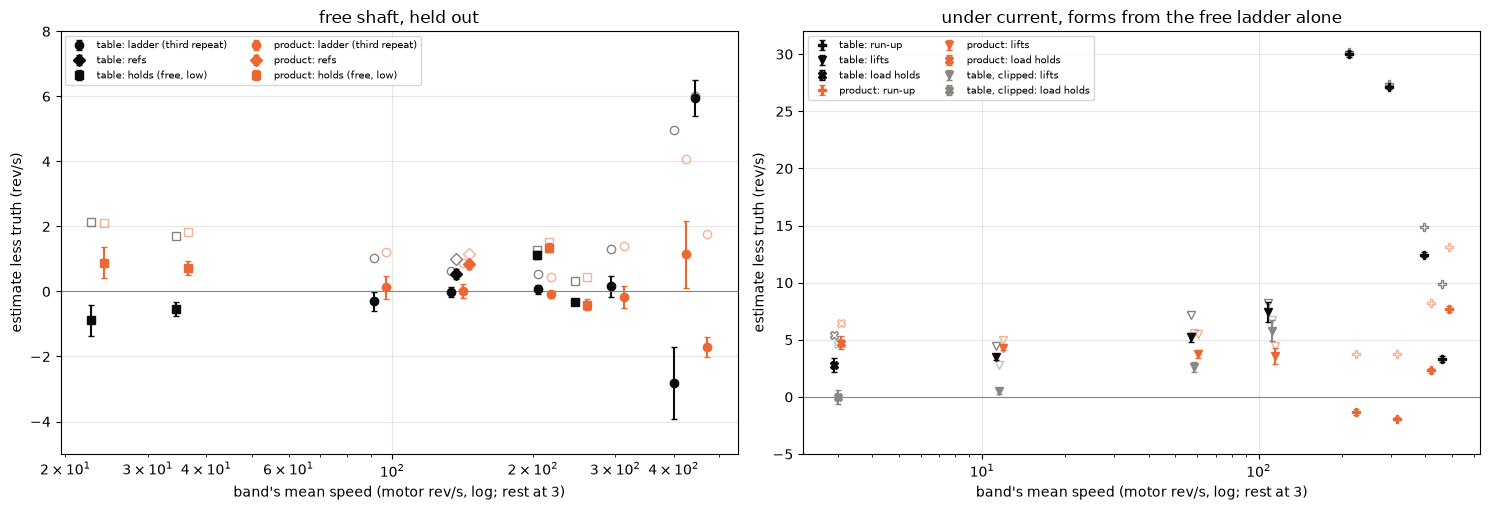

In [48]:
S_W = SC[(SC["zero"] == "tail") & (SC["level"] == "window")
         & SC["fit"].isin(["ladder, two repeats", "ladder alone"])]
panels = (("free shaft, held out",
           ("ladder (third repeat)", "refs", "holds (free, low)"), (-5, 8)),
          ("under current, forms from the free ladder alone",
           ("run-up", "lifts", "load holds"), (-5, 32)))
marks = {"ladder (third repeat)": "o", "refs": "D", "holds (free, low)": "s",
         "run-up": "P", "lifts": "v", "load holds": "X"}
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
for j, (title, names, ylim) in enumerate(panels):
    for form, c, dx in (("table", INK, 0.97), ("product", ORANGE, 1.03),
                        ("table, clipped", MUTED, 1.0)):
        for name in names:
            q = S_W[(S_W["set"] == name) & (S_W["form"] == form)]
            if not len(q) or (form == "table, clipped"
                              and name not in ("lifts", "load holds")):
                continue
            x = np.maximum(q["rev_s"], 3.0) * dx    # rest drawn at 3
            ax[j].errorbar(x, q["bias"], yerr=q["se"], fmt=marks[name],
                           color=c, ms=6, capsize=2, label=f"{form}: {name}")
            ax[j].plot(x, q["rms"], ls="none", marker=marks[name], mfc="none",
                       mec=c, ms=6, alpha=0.5)
    ax[j].axhline(0, color=MUTED, lw=0.8)
    ax[j].set_xscale("log")
    ax[j].set_ylim(*ylim)
    ax[j].legend(fontsize=7, ncol=2, loc="upper left")
    figures.label(ax[j], x="band's mean speed (motor rev/s, log; rest at 3)",
                  y="estimate less truth (rev/s)", title=title)
figures.finish(fig)

What you are looking at. Each form's window bias by band with its standard error (filled) and its rms (open), the table in black, the product in orange, stage 3's clipped table in gray as a control. Left, the free shaft held out. Right, the sets under current, scored on forms fitted on the free ladder alone. The load holds at rest are drawn at 3 rev/s on the log axis.

**Findings.**

- **On the free shaft the ladder held out by repeat does not separate the two forms.** Paired per window the table less the product reads -0.21, -0.23, +0.09, -0.17 and -0.86 rev/s from 30 to 450 rev/s, 1.0, 2.0, 1.6, 1.3 and 0.7 standard errors from zero. On the other free-shaft sets the table is closer, by 0.29 +/- 0.055 rev/s on the references, 0.23 +/- 0.034 on the sag's cycles at 210 rev/s and 0.36 +/- 0.155 on the free holds at 36 rev/s. The edge is real and small. Confidence high that the table is at least as good on the free shaft.
- **The product form's per-row noise is higher**, by a factor of 1.03, 1.06, 1.1 and 1.2 from 30 to 350 rev/s and 1.37 and 1.16 on the two top bands, most likely because the current's noise enters its denominator.
- **Under current at speed the product form is right and the table is not.** On the run-ups the table reads +30.00, +27.10 and +12.45 rev/s high from 160 to 450 rev/s, the product -1.34, -1.92 and +2.31. Paired, the product is closer by 27.3, 24.1 and 8.0 rev/s, about 42 standard errors each. The product was fitted on the free ladder alone and never saw a loaded row. Above 450 rev/s the two are not separated (-0.45 +/- 0.46). Confidence high under 450 rev/s.
- **Adding run-ups to the product's fit does not help.** Held out by sitting it reads -2.01, -2.55, +1.61 and +7.31 rev/s on the left-out run-ups, and its direction term moves from +12.39 to +32.22 to +39.58 mV.
- **At low speed under current both forms read high.** On the lifts the table reads +3.46, +5.22 and +7.42 rev/s and the product +4.32, +3.73 and +3.58 from 0 to 160 rev/s, and on the load holds at rest +2.81 and +4.75. Each carries the free shaft's negative low-speed offset, -20.83 to -21.53 mV for the table and -29.29 to -36.92 for the product at the crawl, into conditions where X is +0.15 +/- 4.40 mV at rest and +3.65 to +42.11 mV on the lifts.
- **The product's speed-times-current slope holds at partial duty.** Inside the lifts X rises with speed by 0.400 +/- 0.050 mV per rev/s, against the product's b x i of 0.41 at 0.2 A. Confidence moderate, since the lifts' truth is the pot through stage 3's table.
- **Both forms miss a term in the current alone at low speed.** Inside the lifts X rises by 0.146 +/- 0.027 mV per mA of current, 5.4 standard errors, and X from the free holds at 42 mA to the lifts at 195 mA rises by 29.2 mV. Carried on linearly to the run-ups' 655 mA the slope would read 12.3 rev/s, while the product reads the run-ups within about 2 rev/s. So the term bends or saturates somewhere between 195 and 655 mA, and this data does not say where.
- **At rest the table is closer by 1.60 +/- 0.20 rev/s**, only because its low-speed offset is smaller.
- **The ladder's rungs under 350 rev/s sit flat.** Per rung, held out, the table reads -1.41 to +1.92 and the product -1.90 to +1.82 rev/s over 23 rungs. Above 350 rev/s they spread to -9.94 to +5.96 and -3.37 to +5.72, and the rungs from 250 rev/s up were still settling by 12.8 to 19.0 % inside their window, one top rung by 4.5 %.
- **The tracked zero changes no conclusion above.** With it the load holds read +3.44 (table), +5.35 (product) and +0.65 (clipped table), and the biases of the other sets move by -0.45 to +0.63 rev/s. The closer form changes in 5 of 19 set-bands, all of them on the free shaft where both forms sit within 0.53 rev/s of the truth.

On the lifts the pot is the truth, and the coast tail that gives the lifts their zero was read with the arm at rest in 3 of 36 coasts. On the load holds the pot only selects the holds at rest, and the truth is zero.

**Both forms are carried.** The choice between them is open. The table reads the free shaft 0.2 to 0.3 rev/s closer and reads +12 to +30 rev/s high under current at speed. The product reads within about 2 rev/s there. Both read +3 to +5 rev/s high at low speed under current. The capture that decides it is a set of holds at one speed and two currents, at a few speeds across the crawl and the lower ladder. It gives the shape of X against current at a fixed speed (a line or a bend that saturates), whether b at partial duty and steady speed equals the run-ups', and how the offset fades to zero at rest. It does not decide the top of the range, which needs settled rungs.

The section's results, packed for the result file.

In [49]:
q, pm = results.quantity, results.pm


def form_mv(p, se):
    """A product form in mV with its standard errors as brackets."""
    return {"c0_mv": pm(p.c0_v * 1e3, se[0] * 1e3, "mV, +/- se"),
            "c_dir_mv": pm(p.c_dir_v * 1e3, se[1] * 1e3, "mV, +/- se"),
            "b_mv_per_rev_s_a": pm(p.b_v_per_rev_s_a * 1e3, se[2] * 1e3,
                                   "mV per (rev/s x A), +/- se")}


lbl = ["c0", "a_dir", "c_w", "c_i"]
R_S4 = {
    "brush_forms": {
        "table_signed_mv": {"knots_rev_s": TAB_FORM.knots,
                            "+1": TAB_FORM.pos * 1e3, "-1": TAB_FORM.neg * 1e3},
        "product_ladder_alone": form_mv(PROD_FORM, SE_PROD),
        "product_ladder_runups": form_mv(PROD_LR, SE_LR),
        "folds": FOLDS.to_dict("records")},
    "brush_heldout_scores": SC.to_dict("records"),
    "brush_paired_by_set_band": PR.to_dict("records"),
    "brush_per_rung_ladder": RG.to_dict("records"),
    "brush_flat_band_rev_s": {
        k: q(np.mean(v), v[0], v[1], "rev/s, range over rungs")
        for k, v in FLAT_RUNGS.items() if k != "n"},
    "x_low_speed_by_set_band": XR.to_dict("records"),
    "lift_x_regression": {
        **{k: pm(b_, s_, u) for k, b_, s_, u in zip(
            lbl, LIFT_BETA, LIFT_SE, ["mV", "mV", "mV per rev/s",
                                      "mV per mA"])},
        "rms": q(LIFT_RMS, unit="mV"), "corr_w_i": q(LIFT_CORR, unit=""),
        "n": q(len(SR["lifts", "tail"].W), unit="windows"),
        "sweeps": q(SR["lifts", "tail"].W["sweep"].nunique(), unit="sweeps")}}
print(len(R_S4), "keys:", ", ".join(R_S4))

7 keys: brush_forms, brush_heldout_scores, brush_paired_by_set_band, brush_per_rung_ladder, brush_flat_band_rev_s, x_low_speed_by_set_band, lift_x_regression


## 5. The solve

The product form is closed, one line per row:

$$\omega = \frac{u - c_0 - c_{dir}\,[\text{dir} = +1]}{K_e + b\,i_w}$$

The table form needs the root of $K_e\,\omega + V_b(\omega, \text{dir}) = u$. A controller has no time for a bisection, so the question is how few steps per row, seeded from the row before, land within the estimate's own noise. Two kinds of step:

- newton, $\omega \leftarrow \omega - (K_e\,\omega + V_b(\omega) - u) / (K_e + V_b'(\omega))$, the table's line through the seed's segment solved exactly.
- fixed, $\omega \leftarrow (u - V_b(\omega)) / K_e$, the table read at the seed.

`speed.solve_steps` keeps one state per direction of drive, the previous row's speed (negated when the drive flips), and reads Ke and the table's knots. It runs once per row at the control tick. The rows are the controller's (the tracked zero, the row's V_on, k_d = 0, the signed table from the whole free ladder), with the L term (the last 100 rows' slope) in the run-ups only. Each step count is scored against the bisection per row.

First, the table's slopes by segment, and each as a share of Ke, which is the fixed step's contraction per step.

In [50]:
SOLVERS = [("newton", 1), ("newton", 2), ("newton", 3),
           ("fixed", 1), ("fixed", 2), ("fixed", 3)]
SLOPES = speed.table_slopes(TAB_FORM)       # per direction: knots, V/rev/s
for name, (kn, sl) in zip(("+1", "-1"), SLOPES):
    print(f"  {name}: " + "  ".join(f"{k:.0f}:{s * 1e3:+.2f} ({s / KE:+.2f})"
                                    for k, s in zip(kn, sl)))
allsl = np.concatenate([s for _, s in SLOPES])
print(f"steepest {allsl.max() * 1e3:+.2f} mV per rev/s = "
      f"{allsl.max() / KE:.2f} Ke; most negative {allsl.min() * 1e3:+.2f} = "
      f"{allsl.min() / KE:+.2f} Ke; unsafe: fixed at |slope| >= Ke "
      f"({KE * 1e3:.2f}), newton at slope <= -Ke")

  +1: 50:+0.20 (+0.03)  100:+0.12 (+0.02)  150:+0.42 (+0.06)  200:+0.31 (+0.04)  250:+0.49 (+0.07)  300:+0.94 (+0.13)  350:+0.62 (+0.09)  400:+4.77 (+0.65)
  -1: 50:+0.09 (+0.01)  100:+0.12 (+0.02)  150:+0.16 (+0.02)  200:+0.27 (+0.04)  250:+0.15 (+0.02)  300:+0.93 (+0.13)  350:+0.72 (+0.10)  400:+1.21 (+0.17)
steepest +4.77 mV per rev/s = 0.65 Ke; most negative +0.09 = +0.01 Ke; unsafe: fixed at |slope| >= Ke (7.28), newton at slope <= -Ke


In [51]:
def rows_of(g0, g1, ntc_c, with_l, drive_sign=False, hole_rows=0):
    """(idx, u, i_w, d, first) of the driven rows of [g0, g1). The
    direction is `dir` there, or the duty's sign with drive_sign (the
    reversals). A hole of up to hole_rows rows keeps the seed."""
    idx = np.arange(g0, g1)
    drv = ARR["bridge"][g0:g1] == DRIVE
    idx = idx[drv]
    d = (SGN[g0:g1][drv] if drive_sign else ARR["dirn"][idx]).astype(np.int64)
    first = np.r_[True, np.diff(idx) > 1] | (ARR["pre_gap"][idx] > hole_rows)
    v_on = speed.tap_volts(ARR["va"][idx], ARR["vb"][idx], d, CHAIN)
    i_w, v_c, _, _ = speed.construct(ARR["raw"][idx], Z_TRACK[idx], v_on,
                                     ARR["duty"][idx], CHAIN, MOTOR)
    didt = (speed.trailing_didt(i_w, FS, L_ROWS, first) if with_l else None)
    u = speed.u_rows(i_w, v_c, np.full(len(idx), ntc_c), MOTOR, didt)
    return idx, u, i_w, d, first


def solve_all(u, d, first, cold="zero"):
    """The bisection and every step solver on the same rows."""
    out = {"bisect": speed.solve_bisect(u, d, TAB_FORM, KE)}
    for kind, n in SOLVERS:
        out[f"{kind} {n}"] = speed.solve_steps(u, d, first, TAB_FORM, KE, n,
                                               kind, cold)
    return out


SOLVE_ROWS, COLD = [], []   # (scenario, group per row, bisect, errors)


def add(scen, group, sol, mask=None):
    m = np.ones(len(group), bool) if mask is None else mask
    SOLVE_ROWS.append((scen, np.asarray(group, object)[m], sol["bisect"][m],
                       {k: (v - sol["bisect"])[m] for k, v in sol.items()
                        if k != "bisect"}))

Three scenarios. Steady speed, the ladder's and the references' spins scored on their last 100 ms. Through a run-up, 100 % from rest, by rows since the start. Through a reversal, the steps and pot-table reversal sets, where the drive flips with the shaft still turning, by rows since the flip.

In [52]:
LAD_S = LAD_W[tach_ok].reset_index(drop=True)
LAD_S["band"] = band_of(LAD_S["truth"])
for r in LAD_S.itertuples():                    # steady speed
    idx, u, i_w, d, first = rows_of(int(r.run0), int(r.g1), r.ntc_c, False)
    add("steady", np.full(len(idx), r.band), solve_all(u, d, first),
        idx >= r.g0)
    COLD.append(("ladder spin", u, d, first))
for _, g in RUN_W.groupby(["set", "k", "dir"]):     # through a run-up
    idx, u, i_w, d, first = rows_of(int(g["run0"].iloc[0]), int(g["g1"].max()),
                                    float(g["ntc_c"].iloc[0]), True)
    n = np.arange(len(idx))
    add("run-up", np.where(n < 10, "rows 0-9", np.where(
        n < 100, "rows 10-99", np.where(n < 300, "rows 100-299",
                                        "rows 300 on"))),
        solve_all(u, d, first))
    COLD.append(("run-up", u, d, first))
rev = SW[SW["ds"].isin(["reversal-1", "reversal-9"])]
n_flip, REV_IMIN = 0, []
for s in rev.itertuples():                      # through a reversal
    idx, u, i_w, d, first = rows_of(int(s.i0), int(s.i1), MOTOR.t0_c, False,
                                    drive_sign=True, hole_rows=200)
    REV_IMIN.append(float(i_w.min()))
    flip = np.flatnonzero((d[1:] != d[:-1]) & ~first[1:]) + 1
    n_flip += len(flip)
    since = np.full(len(idx), 10 ** 9)
    for f in flip:
        since[f:] = np.arange(len(idx) - f)
    lab = np.where(since < 10, "rows 0-9 after the flip", np.where(
        since < 100, "rows 10-99", np.where(since < 1000, "rows 100-999",
        np.where(since < 10 ** 9, "rows 1000 on", "before the flip"))))
    add("reversal", lab, solve_all(u, d, first))
    COLD.append(("reversal", u, d, first))
print(f"steady: {len(LAD_S)} spins; reversals: {len(rev)} sweeps, {n_flip} "
      "direction flips under drive")

steady: 120 spins; reversals: 5 sweeps, 10 direction flips under drive


The error against the bisection per row. The estimate's own noise per row is the sd of the bisection's row-to-row difference over the square root of 2. It is conservative, since the ripple is correlated from row to row.

In [53]:
out = []
for scen in ("steady", "run-up", "reversal"):
    parts = [x for x in SOLVE_ROWS if x[0] == scen]
    grp = np.concatenate([x[1] for x in parts])
    bis = np.concatenate([x[2] for x in parts])
    step = np.concatenate([np.r_[np.nan, np.diff(x[2])] for x in parts])
    for gname in pd.unique(grp):
        m = grp == gname
        noise = np.nanstd(step[m]) / np.sqrt(2)     # rev/s per row
        for sname in parts[0][3]:
            e = np.concatenate([x[3][sname] for x in parts])[m]
            er = np.sqrt((e ** 2).mean())
            out.append({"scenario": scen, "rows": gname, "solver": sname,
                        "n": int(m.sum()), "w_mean": bis[m].mean(),
                        "noise_sd": noise, "err_rms": er,
                        "err_p99": np.percentile(np.abs(e), 99),
                        "err_max": np.abs(e).max(),
                        "rms_over_noise": er / noise,
                        "share_over_0p1": float((np.abs(e) > 0.1).mean())})
SOLVE = pd.DataFrame(out)
SOLVE["o"] = SOLVE["rows"].map(lambda r: ORDER.get(r, 99))
SOLVE = (SOLVE.sort_values(["scenario", "o", "rows", "solver"], kind="stable")
         .drop(columns="o").reset_index(drop=True))
cell = [f"{r:.3f} / {p:.2f} / {m:.1f}" for r, p, m in
        zip(SOLVE["err_rms"], SOLVE["err_p99"], SOLVE["err_max"])]
tab = SOLVE.assign(cell=cell).pivot_table(
    index=["scenario", "rows"], columns="solver", values="cell",
    aggfunc="first", sort=False)
grp = SOLVE.groupby(["scenario", "rows"], sort=False)
tab.insert(0, "noise_sd", grp["noise_sd"].first().round(1))
tab.insert(0, "w", grp["w_mean"].first().round(0))
tab.insert(0, "n", grp["n"].first())
print("rms / 99th percentile / max of the error (rev/s)")
print(tab.to_string())

rms / 99th percentile / max of the error (rev/s)
solver                                 n      w  noise_sd                fixed 1               fixed 2             fixed 3               newton 1             newton 2            newton 3
scenario rows                                                                                                                                                                             
reversal before the flip           65265   59.0       1.8     0.056 / 0.28 / 2.8    0.002 / 0.01 / 0.2  0.000 / 0.00 / 0.0     0.021 / 0.00 / 2.8   0.000 / 0.00 / 0.0  0.000 / 0.00 / 0.0
         rows 0-9 after the flip     100    7.0      31.6     0.420 / 1.43 / 2.0    0.009 / 0.04 / 0.0  0.000 / 0.00 / 0.0     0.353 / 1.43 / 2.0   0.000 / 0.00 / 0.0  0.000 / 0.00 / 0.0
         rows 10-99                  900  -38.0       3.6     0.000 / 0.00 / 0.0    0.000 / 0.00 / 0.0  0.000 / 0.00 / 0.0     0.000 / 0.00 / 0.0   0.000 / 0.00 / 0.0  0.000 / 0.00 / 0.0
         rows 10

In [54]:
WORST = SOLVE.groupby("solver").agg(
    rms_over_noise_max=("rms_over_noise", "max"),
    err_rms_max=("err_rms", "max"), err_max=("err_max", "max"))
print("per solver over every scenario and row group: the largest rms / "
      "noise, the largest rms, the largest error")
print(WORST.round(3).to_string())
st = SOLVE[SOLVE["scenario"] == "steady"]
print("\nsteady speed: rms error as a share of the rows' noise sd, by band")
print(st.pivot_table(index="rows", columns="solver", values="rms_over_noise",
                     sort=False).round(4).to_string())

per solver over every scenario and row group: the largest rms / noise, the largest rms, the largest error
          rms_over_noise_max  err_rms_max  err_max
solver                                            
fixed 1                0.473       18.821   54.014
fixed 2                0.200        2.209   14.365
fixed 3                0.135        1.454    9.403
newton 1               0.244       18.821   72.115
newton 2               0.012        0.218   11.051
newton 3               0.000        0.000    0.000

steady speed: rms error as a share of the rows' noise sd, by band
solver   fixed 1  fixed 2  fixed 3  newton 1  newton 2  newton 3
rows                                                            
30-100    0.0321   0.0008   0.0000    0.0014     0.000       0.0
100-160   0.0262   0.0007   0.0000    0.0048     0.000       0.0
160-250   0.0619   0.0029   0.0001    0.0061     0.000       0.0
250-350   0.1331   0.0152   0.0019    0.0281     0.000       0.0
350-450   0.4725   0.1997   0

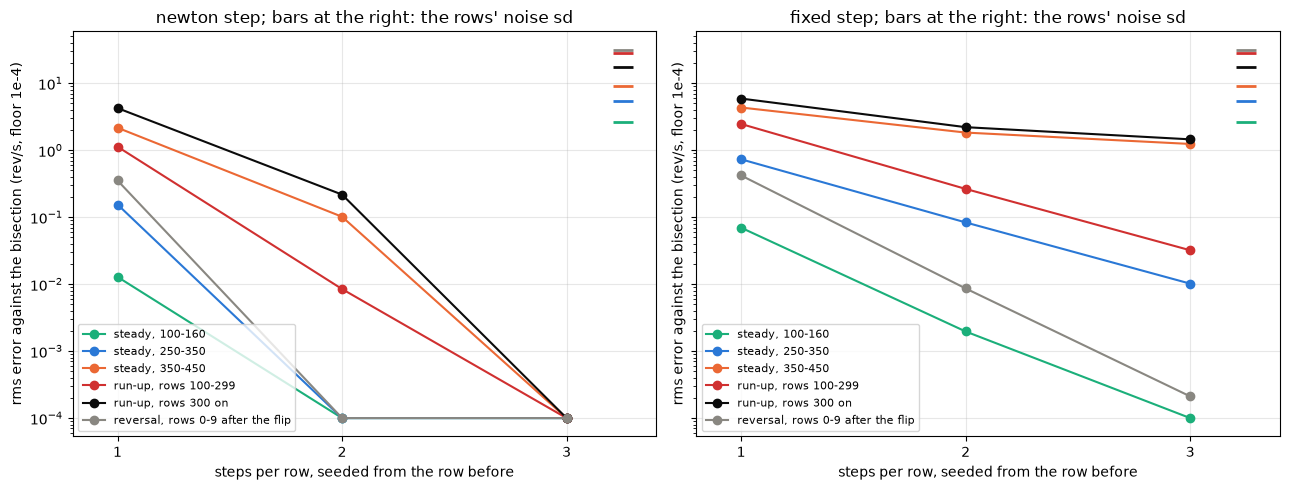

In [55]:
Q = SOLVE.assign(kind=SOLVE["solver"].str.split().str[0],
                 steps=SOLVE["solver"].str.split().str[1].astype(int))
groups = [("steady", "100-160", GREEN), ("steady", "250-350", BLUE),
          ("steady", "350-450", ORANGE), ("run-up", "rows 100-299", RED),
          ("run-up", "rows 300 on", INK),
          ("reversal", "rows 0-9 after the flip", MUTED)]
fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for j, kind in enumerate(("newton", "fixed")):
    for scen, rows, c in groups:
        g = Q[(Q["scenario"] == scen) & (Q["rows"] == rows)
              & (Q["kind"] == kind)].sort_values("steps")
        if not len(g):
            continue
        ax[j].plot(g["steps"], np.maximum(g["err_rms"], 1e-4), "-o",
                   color=c, label=f"{scen}, {rows}")
        ax[j].plot([3.25], [g["noise_sd"].iloc[0]], marker="_", color=c,
                   ms=14, mew=2)        # the rows' own noise sd
    ax[j].set_yscale("log")
    ax[j].set_xticks([1, 2, 3])
    ax[j].set_xlim(0.8, 3.4)
    ax[j].legend(fontsize=8, loc="lower left")
    figures.label(ax[j], x="steps per row, seeded from the row before",
                  y="rms error against the bisection (rev/s, floor 1e-4)",
                  title=f"{kind} step; bars at the right: the rows' noise sd")
figures.finish(fig)

What you are looking at. The rms error of a fixed number of steps per row against the bisection, newton steps on the left and fixed-point steps on the right, for three steady bands, two stretches of the run-ups and the first rows after a flip. The short bars at the right of each panel are the rows' own noise sd in the same color. A curve under its bar is a solve inside the estimate's own noise, and an error of zero is drawn at the floor of 1e-4 rev/s.

The cold seed. On the first rows after torque on there is no row before, so the step is seeded at zero or at the plain estimate u / Ke. The |error| against the bisection on rows 0 to 3 of every run, median and largest, with the bisection's own speed at row 0.

In [56]:
cold = []
for seed in ("zero", "plain"):
    for kind, n in SOLVERS:
        errs = {}
        for scen, u, d, first in COLD:
            w = speed.solve_steps(u, d, first, TAB_FORM, KE, n, kind, seed)
            bis = speed.solve_bisect(u, d, TAB_FORM, KE)
            for f in np.flatnonzero(first):
                for j in range(4):      # rows 0..3 inside the same run
                    if f + j < len(u) and not first[f + 1:f + j + 1].any():
                        errs.setdefault(j, []).append(abs(w[f + j]
                                                          - bis[f + j]))
                errs.setdefault("w0", []).append(bis[f])
        cold.append({"seed": seed, "solver": f"{kind} {n}",
                     "runs": len(errs[0]),
                     **{f"row {j}": (np.median(errs[j]), np.max(errs[j]))
                        for j in range(4)},
                     "w0": (np.median(errs["w0"]), np.max(errs["w0"]))})
COLD_T = pd.DataFrame(cold)
show_cold = COLD_T.copy()
for c in [f"row {j}" for j in range(4)] + ["w0"]:
    show_cold[c] = [f"{a:.3f} / {b:.2f}" for a, b in show_cold[c]]
print("median / max |error| (rev/s); w0 = the bisection at row 0")
print(show_cold.to_string(index=False))

median / max |error| (rev/s); w0 = the bisection at row 0
 seed   solver  runs         row 0         row 1         row 2        row 3               w0
 zero newton 1   166 3.764 / 54.01 0.415 / 54.01 0.000 / 11.60 0.078 / 3.90 227.436 / 549.32
 zero newton 2   166  0.000 / 6.11  0.000 / 4.74  0.000 / 1.01 0.000 / 0.00 227.436 / 549.32
 zero newton 3   166  0.000 / 0.00  0.000 / 0.00  0.000 / 0.00 0.000 / 0.00 227.436 / 549.32
 zero  fixed 1   166 3.764 / 54.01 1.001 / 54.01 0.518 / 27.81 0.466 / 7.66 227.436 / 549.32
 zero  fixed 2   166  0.034 / 4.94  0.005 / 7.43  0.009 / 3.47 0.011 / 0.83 227.436 / 549.32
 zero  fixed 3   166  0.001 / 1.17  0.000 / 4.86  0.000 / 0.26 0.000 / 0.10 227.436 / 549.32
plain newton 1   166  0.000 / 4.95 0.349 / 54.01 0.000 / 11.60 0.078 / 3.90 227.436 / 549.32
plain newton 2   166  0.000 / 0.00  0.000 / 4.74  0.000 / 1.01 0.000 / 0.00 227.436 / 549.32
plain newton 3   166  0.000 / 0.00  0.000 / 0.00  0.000 / 0.00 0.000 / 0.00 227.436 / 549.32
plain  fixed

In [57]:
B_PROD = PROD_FORM.b_v_per_rev_s_a
I_DEN = -KE / B_PROD                    # A, where Ke + b i_w reaches zero
I_REV = min(REV_IMIN)                   # A, the reversals' lowest current
print(f"product form: its denominator Ke + b i_w stays positive while i_w > "
      f"{I_DEN:.2f} A (b {B_PROD * 1e3:.3f} mV per rev/s per A)")
print(f"the most negative i_w in the reversals: {I_REV:.3f} A, Ke + b i_w = "
      f"{(KE + B_PROD * I_REV) * 1e3:.2f} mV per rev/s "
      f"({(KE + B_PROD * I_REV) / KE:.2f} Ke)")

product form: its denominator Ke + b i_w stays positive while i_w > -3.54 A (b 2.058 mV per rev/s per A)
the most negative i_w in the reversals: -0.126 A, Ke + b i_w = 7.02 mV per rev/s (0.96 Ke)


**Findings.**

- **One newton step per row stays inside the estimate's own noise under 350 rev/s**, at 0.0281 of the row noise or less. On the steep segment at 350 to 450 rev/s it reaches 0.2357. One fixed step also stays inside the noise under 350 rev/s (0.1331 or less) but reaches 0.4725 on the steep segment.
- **Two newton steps are indistinguishable from the bisection.** The largest rms over every scenario is 0.012 of the row noise. Three are exact, since the table is piecewise linear and rising. Confidence high for this table, over the steady spins, the run-ups and the 10 drive flips.
- **The worst single rows** are 72.1 rev/s for one newton step, 11.1 for two and 9.4 for three fixed steps, all on the steep segment.
- **The cold seed.** Seeded at zero, one newton step misses by a median of 3.764 rev/s on the first row after torque on, 54.01 at worst, and two steps by 0 and 6.11 at worst. Seeded at the plain estimate u / Ke, one newton step misses by 0 / 4.95 on that row and two by nothing. Three are exact from either seed.
- **Where a step is unsafe.** A fixed step diverges where a segment's slope reaches Ke (7.28 mV per rev/s). This table's steepest is 0.65 Ke, from 400 to 450 rev/s in direction +1, resting on the rungs with dropouts. A newton step loses a unique root where a slope reaches -Ke. The most negative here is +0.01 Ke. For any servo the identification can check every segment's slope against the interval from -Ke / 2 to Ke and flatten or refuse a table outside it.
- **The estimate itself is not valid on the first rows after torque on.** With no L term it reads the applied volts as speed until the current builds, a median of 227.436 rev/s at row 0 and up to 549.32 on a shaft at rest. That is the valid flag's job (section 9), not a solve error.
- **The product form needs no solve.** Its denominator stays positive while the current is above -3.54 A. The most negative current in the reversals is -0.126 A, where the denominator is 0.96 Ke.

**The solve for the table form**: two newton steps per row at the control tick, seeded from the row before and negated when the drive flips, the plain seed u / Ke after torque on. Its state is the previous row's speed and direction, and it reads Ke and the table's knots and values.

The section's results, packed for the result file.

In [58]:
R_S5 = {
    "solve_error_by_scenario": SOLVE.to_dict("records"),
    "solve_cold_seed": [
        {"seed": r["seed"], "solver": r["solver"], "runs": r["runs"],
         **{c: {"median": r[c][0], "max": r[c][1]}
            for c in [f"row {j}" for j in range(4)] + ["w0"]}}
        for r in COLD_T.to_dict("records")],
    "table_slopes_share_of_ke": {
        d: {"knots_rev_s": kn, "slope_mv_per_rev_s": sl * 1e3,
            "share_of_ke": sl / KE}
        for d, (kn, sl) in zip(("+1", "-1"), SLOPES)},
    "solve_recommendation": {
        "kind": "newton", "steps": 2,
        "seed": "the row before, negated on a flip; u / Ke after torque on",
        "slope_guard": "every segment's slope inside (-Ke / 2, Ke)",
        "worst_rms_over_noise": q(WORST.loc["newton 2", "rms_over_noise_max"],
                                  unit="share of the row noise"),
        "product_denominator_zero_a": q(I_DEN, unit="A")}}
print(len(R_S5), "keys:", ", ".join(R_S5))

4 keys: solve_error_by_scenario, solve_cold_seed, table_slopes_share_of_ke, solve_recommendation


## 6. The noise per row

### The estimate as the controller sees it

From here to section 9 the estimate is the controller's throughout. It reads the tracked zero (stage 1's tracker in float, the state after the row before), the row's own V_on for the edge lags, k_d = 0, the drive's direction from the duty's sign, and the two brush forms of section 4 fitted on the whole free ladder. The table is solved with two newton steps seeded from the row before (section 5), the product form in closed form. No L term unless a line says so.

`est` takes the driven rows of a global row range as a controller meets them. A row is `first` when nothing comes before it, after a break in the driven rows longer than 200 rows. A row is a `flip` when the drive's direction changed against the row before. The NTC is the sweep's probe.

In [59]:
TAU_E_ROWS = MOTOR.l_h / MOTOR.r_ohm * FS    # the winding's L / R in rows
SWEEP_I1 = SW["i1"].to_numpy()


def est(g0, g1, ntc_c=None, hole_rows=200, zero=None):
    """The driven rows of [g0, g1) as the controller sees them: idx, d,
    first, flip, v_on, i_w, v_c, u (no L term), duty, crest, zero, tap,
    ntc, D, s."""
    g0, g1 = int(g0), int(g1)
    idx = np.arange(g0, g1)[ARR["bridge"][g0:g1] == DRIVE]
    d = SGN[idx].astype(np.int64)
    idx, d = idx[d != 0], d[d != 0]
    first = np.r_[True, np.diff(idx) > 1] | (ARR["pre_gap"][idx] > hole_rows)
    if len(first):
        first[0] = True
    flip = np.r_[False, d[1:] != d[:-1]] & ~first
    if ntc_c is None:
        ntc_c = NTC_SWEEP[int(np.searchsorted(SWEEP_I1, g0, side="right"))]
    crest = ARR["raw"][idx].astype(float)
    z = (Z_TRACK[idx] if zero is None
         else np.broadcast_to(np.asarray(zero, float), idx.shape))
    duty = ARR["duty"][idx].astype(float)
    tap = (ARR["va"][idx].astype(float) - ARR["vb"][idx].astype(float)) * d
    v_on = (tap - CHAIN.tap_offset_counts) / CHAIN.tap_counts_per_v
    i_w, v_c, D, s = speed.construct(crest, z, v_on, duty, CHAIN, MOTOR)
    u = speed.u_rows(i_w, v_c, np.full(len(idx), float(ntc_c)), MOTOR)
    return dict(idx=idx, d=d, first=first, flip=flip, v_on=v_on, i_w=i_w,
                v_c=v_c, u=u, duty=duty, crest=crest, zero=z, tap=tap,
                ntc=float(ntc_c), D=D, s=s)

In [60]:
def u_of(crest, zero, tap, duty, ntc_c):
    """u (no L term) and i_w from the four row inputs: the construction,
    for the per-input splits."""
    v_on = (tap - CHAIN.tap_offset_counts) / CHAIN.tap_counts_per_v
    i_w, v_c, _, _ = speed.construct(crest, zero, v_on, duty, CHAIN, MOTOR)
    return speed.u_rows(i_w, v_c, np.full(len(crest), float(ntc_c)),
                        MOTOR), i_w


def solve(E, didt=None, form="both"):
    """(w table, w product) per row, rev/s in the drive's direction; didt
    (A/s) adds the L term."""
    u = E["u"] if didt is None else E["u"] - MOTOR.l_h * np.asarray(didt)
    wt = wp = None
    if form in ("both", "table"):
        wt = speed.solve_steps(u, E["d"], E["first"], TAB_FORM, KE, 2,
                               "newton", "plain")
    if form in ("both", "product"):
        wp = speed.solve_product(u, E["i_w"], E["d"], PROD_FORM, KE)
    return wt, wp


def detrend(x, deg=1):
    """x less its least-squares polynomial of degree deg."""
    k = np.arange(len(x)) - (len(x) - 1) / 2
    return x - np.polyval(np.polyfit(k, x, deg), k)


def rms(x):
    """rms over the finite values."""
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    return float(np.sqrt(np.mean(x ** 2))) if len(x) else np.nan

In [61]:
a_rev = CHAIN.a_per_count * MOTOR.r_ohm / KE
print(f"L {MOTOR.l_h * 1e3:.3f} mH, R {MOTOR.r_ohm:.4f} ohm: L/R "
      f"{TAU_E_ROWS:.2f} rows = {TAU_E_ROWS / FS * 1e6:.0f} us; "
      f"{PER_REV} commutation events per rev")
print(f"one count of current through R = {a_rev:.3f} rev/s; one count of "
      f"tap difference = {1 / CHAIN.tap_counts_per_v / KE:.3f} rev/s x s; "
      f"L x fs = {MOTOR.l_h * FS:.1f} ohm = "
      f"{MOTOR.l_h * FS * CHAIN.a_per_count / KE:.2f} rev/s per count of "
      "row-to-row current difference")

L 0.820 mH, R 4.1767 ohm: L/R 3.93 rows = 196 us; 6 commutation events per rev
one count of current through R = 0.505 rev/s; one count of tap difference = 0.553 rev/s x s; L x fs = 16.4 ohm = 1.98 rev/s per count of row-to-row current difference


The steady windows of sections 6 and 7 are stage 3's ladder spins and reference rungs, the holds, and the load holds at rest (the pot held still within `windows.STILL_COUNTS` counts). Here the pot only selects, and the truth is zero.

In [62]:
def steady_windows():
    """Ladder, reference, hold and rest windows with kind and band."""
    L = LAD_W[LAD_W["g0"].notna() & LAD_W["truth"].notna()].copy()
    L["kind"] = np.where(L["set"].str.startswith("ref"), "reference",
                         "ladder")
    H = HOLD_W[HOLD_W["g0"].notna() & HOLD_W["truth"].notna()].copy()
    H["kind"] = "hold"
    R = LOAD_W[LOAD_W["still"]].copy()
    R["kind"], R["truth"] = "rest", 0.0
    cols = ["kind", "set", "sweep", "g0", "g1", "run0", "truth", "ntc_c",
            "dir"]
    W = pd.concat([L[cols], H[cols], R[cols]], ignore_index=True)
    W["band"] = np.where(W["kind"] == "rest", "rest", band_of(W["truth"]))
    return W


STEADY = steady_windows()
print(STEADY.groupby("kind").size().to_dict(), "windows")

{'hold': 106, 'ladder': 108, 'reference': 36, 'rest': 70} windows


### The duty steps' truth

The steps set's duty steps get the ripple tach's truth for a transient. `windows.steps_truth` fits a first-order response to the phase of the commutation crossings after each step, on the tracked zero, and `windows.steps_kept` keeps the fits with a residual under `windows.KEEP_CYCLES` of a commutation period and a time constant inside `windows.KEEP_TAU_MS`.

In [63]:
STEPS_T = windows.steps_truth(STORE, Z_TRACK, PAIR_DIR, STEPS_DATASET,
                               PER_REV)
STEPS_KEPT = windows.steps_kept(STEPS_T)
k = STEPS_T[STEPS_KEPT]
print(f"{len(STEPS_T)} step fits, {int(STEPS_T['ok'].sum())} under the "
      f"residual, {int(STEPS_KEPT.sum())} kept, in "
      f"{k['sweep'].nunique() if 'sweep' in k else 'n/a'} sweeps")
print(list(STEPS_T.columns))

85 step fits, 71 under the residual, 60 kept, in 21 sweeps
['sweep', 'chain', 'base_pct', 'step_pct', 'sign', 'dir', 'run0', 'g0', 'g_step', 'g1', 'hole', 'w0', 'dw', 'tau_ms', 'res_cycles', 'n_cross', 'ok']


### The noise per row and where it comes from

Each steady window's per-row estimate is taken about its own parabola (the rungs above 250 rev/s are still settling inside their window), and its variance is split four ways from its periodogram.

- The tick pattern, the mean by tick counter mod 16 less what the bins' own noise leaves in the means. It is not taken where the commutation rate sits on the pattern's lines, a band then marked confounded.
- The white floor, the 20th percentile of the bins above 5 kHz read as a level over every bin.
- The commutation part, what stands over the floor from half the commutation rate up, the ripple and its harmonics.
- The sub part, what stands over the floor under half the commutation rate, the rotation's own orders or the shaft's real wander. At rest, with no commutation, the split point is 1 kHz.

The estimate is also recomputed with only one input moving, the crest current, the taps or the zero, the other two held at the window's mean. That splits the noise by input. A window needs 400 rows to count.

In [64]:
import warnings

LAGS = [1, 2, 3, 4, 5, 8, 10, 16, 20, 32, 50, 100, 200]  # rows, the ACF's
MODS = [2, 3, 4, 5, 6, 7, 8, 10, 12, 16, 20, 24, 32, 48, 64]  # tick folds
NPER = 400              # rows per Welch segment of the spectra


def fold_var(x, phase, m):
    """Variance of the mean of x by phase (0..m-1), less what the bins'
    own noise leaves in the means; and the means."""
    cnt = np.bincount(phase, minlength=m).astype(float)
    ok = cnt > 1
    mean = np.bincount(phase, weights=x, minlength=m)[ok] / cnt[ok]
    within = ((np.bincount(phase, weights=x * x, minlength=m)[ok] / cnt[ok]
               - mean ** 2) * cnt[ok] / (cnt[ok] - 1))
    g = np.average(mean, weights=cnt[ok])
    v = (np.average((mean - g) ** 2, weights=cnt[ok])
         - np.mean(within / cnt[ok]) * (ok.sum() - 1) / ok.sum())
    return v, mean


def pgram(x):
    """One-sided periodogram, Hann window, scaled so it sums to the
    variance."""
    n = len(x)
    w = np.hanning(n)
    P = np.abs(np.fft.rfft((x - x.mean()) * w)) ** 2
    P[1:] *= 2                          # one-sided: fold the negative side
    return P / (n * np.sum(w ** 2))


def acf(x, lags):
    """Autocorrelation of x at the lags (rows)."""
    x = x - x.mean()
    v = np.dot(x, x)
    return [float(np.dot(x[k:], x[:-k]) / v) for k in lags]

In [65]:
def split(x, truth, phase16):
    """Variances of x about its window's parabola: total = tick + white +
    comm + sub (see above); r1 the lag-1 correlation of what is left."""
    x = detrend(x, 2)
    n, var = len(x), float(np.var(x))
    fc = PER_REV * truth                    # Hz, the commutation rate
    v16, pat = fold_var(x, phase16, 16)
    k16 = fc / (FS / 16)                    # the rate on the pattern's lines
    conf = truth > 5 and abs(k16 - round(k16)) < 0.08 and round(k16) >= 1
    if conf:                                # the fold sees the ripple too
        v16, r = np.nan, x
    else:
        v16 = max(v16, 0.0)
        r = x - pat[phase16] + pat.mean()   # the tick pattern taken out
    P = pgram(r)
    P *= np.var(r) / P.sum()
    f = np.fft.rfftfreq(n, 1 / FS)
    wbin = np.quantile(P[f > 5000], 0.2) / -np.log(0.8)   # the floor per bin
    white = min(wbin * (len(P) - 1), float(np.var(r)))
    cut = 0.5 * fc if truth > 5 else 1000.0     # Hz, sub / comm split
    sub = float(np.sum(P[(f > 0) & (f < cut)] - wbin))
    comm = float(np.var(r)) - white - sub
    r1 = float(np.corrcoef(r[1:], r[:-1])[0, 1])
    return dict(var=var, tick=v16, white=white, comm=comm, sub=sub, r1=r1,
                conf=float(conf), pp16=float(np.ptp(pat)))

`noise_window` runs one window. It takes the estimate from the spin's first row, so the solve's seed is warm at the window, keeps the rows inside the window, and returns the split of the table form, the product form, the plain u / Ke and the three single-input estimates, the folds by every tick modulus, the autocorrelation and the spectra.

In [66]:
def noise_window(r):
    """(record, folds, acf, spectra) of one steady window, or None."""
    E = est(r.run0, r.g1, r.ntc_c)
    wt, wp = solve(E)
    m = E["idx"] >= r.g0                    # the window's own rows
    if m.sum() < 400:
        return None
    tick = TICK[E["idx"][m]]
    ph = (tick % 16).astype(np.int64)
    cr, z, tap, du = E["crest"][m], E["zero"][m], E["tap"][m], E["duty"][m]
    mz, mt, mc = z.mean(), tap.mean(), cr.mean()  # held at the means
    hold = lambda v: np.full_like(cr, v)    # noqa: E731
    parts = {"table": wt[m], "product": wp[m], "plain": E["u"][m] / KE,
             "current": u_of(cr, hold(mz), hold(mt), du, E["ntc"])[0] / KE,
             "taps": u_of(hold(mc), hold(mz), tap, du, E["ntc"])[0] / KE,
             "zero": u_of(hold(mc), z, hold(mt), du, E["ntc"])[0] / KE}
    sc, st = split(cr, r.truth, ph), split(tap, r.truth, ph)
    rec = dict(kind=r.kind, set=r.set, band=r.band, sweep=r.sweep,
               truth=r.truth, n=int(m.sum()), duty=float(np.median(du)),
               i_ma=float(E["i_w"][m].mean() * 1e3),
               bias_table=float(wt[m].mean() - r.truth),
               crest_sd=float(np.std(detrend(cr, 2))),
               tap_sd=float(np.std(detrend(tap, 2))),
               zero_sd=float(np.std(detrend(z, 2))), crest_pp16=sc["pp16"],
               tap_pp16=st["pp16"], crest_tick=sc["tick"],
               tap_tick=st["tick"])
    for name, x in parts.items():
        rec.update({f"{name}_{k}": v
                    for k, v in split(x, r.truth, ph).items()})
    xt = detrend(wt[m], 2)
    folds = [dict(band=r.band, kind=r.kind, mod=mod, tot=float(np.var(xt)),
                  var=fold_var(xt, (tick % mod).astype(np.int64), mod)[0])
             for mod in MODS]
    ac = dict(band=r.band, kind=r.kind, **dict(zip(
        [f"lag{k}" for k in LAGS], acf(xt, LAGS))))
    spec = {nm: welch(detrend(parts[nm], 2), FS, nperseg=NPER)
            for nm in ("current", "taps")}
    spec[""] = welch(xt, FS, nperseg=NPER, detrend="linear")
    return rec, folds, ac, spec

In [67]:
rows_q1, folds_q1, acfs_q1, PSD = [], [], [], {}
with warnings.catch_warnings():     # a constant input (the zero inside a
    warnings.simplefilter("ignore")     # window) has no spectrum
    for r in STEADY.itertuples():
        got = noise_window(r)
        if got is None:
            continue
        rec, folds, ac, spec = got
        rows_q1.append(rec)
        folds_q1 += folds
        acfs_q1.append(ac)
        for nm, (f_hz, p) in spec.items():
            key = (r.kind, r.band) + ((nm,) if nm else ())
            PSD.setdefault(key, []).append(p)
PSD_F = f_hz                                # Hz, the spectra's bins
PSD = {k: np.mean(v, axis=0) for k, v in PSD.items()}  # mean per band
Q1_WIN = pd.DataFrame(rows_q1)
print(f"{len(Q1_WIN)} windows scored of {len(STEADY)}:",
      Q1_WIN.groupby("kind").size().to_dict())

320 windows scored of 320: {'hold': 106, 'ladder': 108, 'reference': 36, 'rest': 70}


The windows pooled by kind and band. The sd of each part is the root of its mean variance over the windows, the bracket the range of the windows' own sd.

In [68]:
def band_record(kind, band, g):
    """One kind and band of the per-window noise, pooled."""
    t = g.truth.mean()
    rec = dict(kind=kind, band=band, n_win=len(g), sweeps=g.sweep.nunique(),
               rows=int(g.n.sum()), truth=t, i_ma=g.i_ma.mean(),
               duty_pct=g.duty.mean() / CHAIN.half_period_ticks * 100,
               rows_per_commutation=FS / (PER_REV * t) if t > 0 else np.nan,
               crest_sd_counts=np.sqrt((g.crest_sd ** 2).mean()),
               tap_sd_counts=np.sqrt((g.tap_sd ** 2).mean()),
               zero_sd_counts=np.sqrt((g.zero_sd ** 2).mean()),
               confounded=int(g.table_conf.sum()),
               crest_pp16=g.crest_pp16.median(), tap_pp16=g.tap_pp16.median(),
               crest_tick_sd=np.sqrt(np.nanmean(g.crest_tick)),
               tap_tick_sd=np.sqrt(np.nanmean(g.tap_tick)))
    for name in ("table", "product", "plain", "current", "taps", "zero"):
        v = g[f"{name}_var"].mean()
        rec[f"{name}_sd"] = np.sqrt(v)
        rec[f"{name}_sd_lo"] = np.sqrt(g[f"{name}_var"].min())
        rec[f"{name}_sd_hi"] = np.sqrt(g[f"{name}_var"].max())
        for part in ("comm", "sub", "tick", "white"):
            col = g[f"{name}_{part}"]
            pv = np.nanmean(col) if col.notna().any() else np.nan
            rec[f"{name}_{part}_share"] = pv / v if v > 0 else np.nan
            rec[f"{name}_{part}_sd"] = (np.sqrt(max(pv, 0.0))
                                        if np.isfinite(pv) else np.nan)
        rec[f"{name}_r1"] = g[f"{name}_r1"].median()
    return rec


with warnings.catch_warnings():     # an all-NaN tick part where confounded
    warnings.simplefilter("ignore")
    Q1_BANDS = pd.DataFrame([band_record(k, b, g) for (k, b), g in
                             Q1_WIN.groupby(["kind", "band"], sort=False)])

In [69]:
band_order = {b: i for i, b in enumerate(["rest"] + BAND_NAMES)}
Q1_BANDS = Q1_BANDS.sort_values(
    ["kind", "band"], key=lambda c: c.map(band_order) if c.name == "band"
    else c).reset_index(drop=True)
print("noise per row (rev/s): table sd [range], product; the table's "
      "comm / sub / tick / white; lag-1 r; per input current / taps / zero;"
      " crest and tap sd (counts); confounded windows")
for r in Q1_BANDS.itertuples():
    print(f"{r.kind:9s} {r.band:8s} {r.n_win:3d} {r.truth:6.1f} {r.i_ma:4.0f}"
          f" mA {r.duty_pct:5.1f} % {r.rows_per_commutation:6.1f} rows | "
          f"{r.table_sd:5.2f} [{r.table_sd_lo:4.1f}-{r.table_sd_hi:4.1f}] "
          f"{r.product_sd:5.2f} | {r.table_comm_sd:5.2f} {r.table_sub_sd:5.2f}"
          f" {r.table_tick_sd:4.2f} {r.table_white_sd:5.2f} | "
          f"{r.table_r1:+.2f} | {r.current_sd:5.2f} {r.taps_sd:4.2f} "
          f"{r.zero_sd:5.3f} | {r.crest_sd_counts:5.2f} "
          f"{r.tap_sd_counts:5.2f} | {r.confounded}")
print("per input, comm / sub / tick / white (rev/s): only the current "
      "moving, only the taps; the tick pattern mod 16 in counts")
for r in Q1_BANDS.itertuples():
    print(f"{r.kind:9s} {r.band:8s} current {r.current_comm_sd:5.2f} "
          f"{r.current_sub_sd:5.2f} {r.current_tick_sd:4.2f} "
          f"{r.current_white_sd:5.2f} | taps {r.taps_comm_sd:4.2f} "
          f"{r.taps_sub_sd:4.2f} {r.taps_tick_sd:4.2f} {r.taps_white_sd:4.2f}"
          f" | crest {r.crest_pp16:4.2f} pp ({r.crest_tick_sd:4.2f} sd), "
          f"taps {r.tap_pp16:4.2f} pp ({r.tap_tick_sd:4.2f} sd)")

noise per row (rev/s): table sd [range], product; the table's comm / sub / tick / white; lag-1 r; per input current / taps / zero; crest and tap sd (counts); confounded windows
hold      0-30      23   21.9   40 mA   7.9 %  152.1 rows |  3.84 [ 2.5- 5.4]  3.83 |  3.34  1.75 0.10  0.71 | +0.95 |  3.56 0.56 0.009 |  6.70 17.40 | 0
hold      30-100    57   35.6   42 mA   9.6 %   93.7 rows |  4.86 [ 4.0- 6.5]  4.88 |  4.27  2.15 0.08  0.88 | +0.96 |  4.77 0.14 0.009 |  8.99  2.92 | 0
hold      160-250   24  210.4   97 mA  30.0 %   15.8 rows | 10.40 [ 9.9-11.0] 11.55 | 10.13  1.38 0.00  1.92 | +0.87 | 10.34 0.56 0.002 | 19.71  3.34 | 11
hold      250-350    2  253.6  104 mA  30.0 %   13.1 rows | 10.83 [10.8-10.8] 12.04 | 10.54  2.04 0.00  1.44 | +0.86 | 10.61 0.57 0.004 | 20.22  3.41 | 0
ladder    0-30       2   28.9   64 mA  20.0 %  115.4 rows |  5.88 [ 5.7- 6.0]  5.97 |  5.72  0.90 0.00  1.00 | +0.97 |  5.73 0.23 0.002 | 10.85  2.06 | 0
ladder    30-100    34   70.0   65 mA  19.1 %   47.6

In [70]:
Q1_FOLDS = (pd.DataFrame(folds_q1)
            .groupby(["kind", "band", "mod"], sort=False)
            .agg(var=("var", "mean"), tot=("tot", "mean")))
Q1_FOLDS["share"] = Q1_FOLDS["var"] / Q1_FOLDS["tot"]
Q1_FOLDS = Q1_FOLDS.reset_index()
Q1_ACF = (pd.DataFrame(acfs_q1).groupby(["kind", "band"], sort=False)
          .mean().reset_index())
rest_f = Q1_FOLDS[Q1_FOLDS["kind"] == "rest"]
print("at rest, share of the table form's variance by tick modulus: "
      + "  ".join(f"{int(m)}:{v:.3f}"
                  for m, v in zip(rest_f["mod"], rest_f["share"])))
print("autocorrelation of the table form by band, lags "
      + ", ".join(str(k) for k in LAGS))
for r in Q1_ACF.itertuples():
    print(f"{r.kind:9s} {r.band:8s} "
          + " ".join(f"{getattr(r, f'lag{k}'):+.2f}" for k in LAGS))

at rest, share of the table form's variance by tick modulus: 2:0.004  3:-0.000  4:0.009  5:0.001  6:0.004  7:-0.001  8:0.076  10:0.006  12:0.008  16:0.089  20:0.011  24:0.076  32:0.089  48:0.089  64:0.089
autocorrelation of the table form by band, lags 1, 2, 3, 4, 5, 8, 10, 16, 20, 32, 50, 100, 200
ladder    30-100   +0.95 +0.91 +0.86 +0.80 +0.73 +0.45 +0.23 -0.32 -0.48 +0.01 -0.20 +0.19 -0.03
ladder    0-30     +0.96 +0.95 +0.92 +0.88 +0.84 +0.66 +0.50 -0.05 -0.40 -0.81 +0.46 -0.22 -0.42
ladder    100-160  +0.92 +0.81 +0.67 +0.48 +0.27 -0.39 -0.71 -0.45 +0.39 -0.36 +0.81 +0.54 -0.02
ladder    160-250  +0.86 +0.64 +0.34 -0.00 -0.34 -0.83 -0.56 +0.80 -0.13 +0.65 +0.06 -0.15 -0.05
ladder    250-350  +0.74 +0.36 -0.11 -0.53 -0.77 -0.15 +0.65 -0.77 +0.36 +0.60 -0.60 +0.14 -0.12
ladder    350-450  +0.46 +0.04 -0.30 -0.47 -0.41 +0.46 +0.06 +0.31 -0.20 -0.11 -0.01 -0.02 -0.07
ladder    450-600  +0.38 -0.10 -0.47 -0.52 -0.24 +0.40 -0.43 +0.11 +0.06 -0.15 +0.01 -0.06 +0.02
reference 100-160  +0

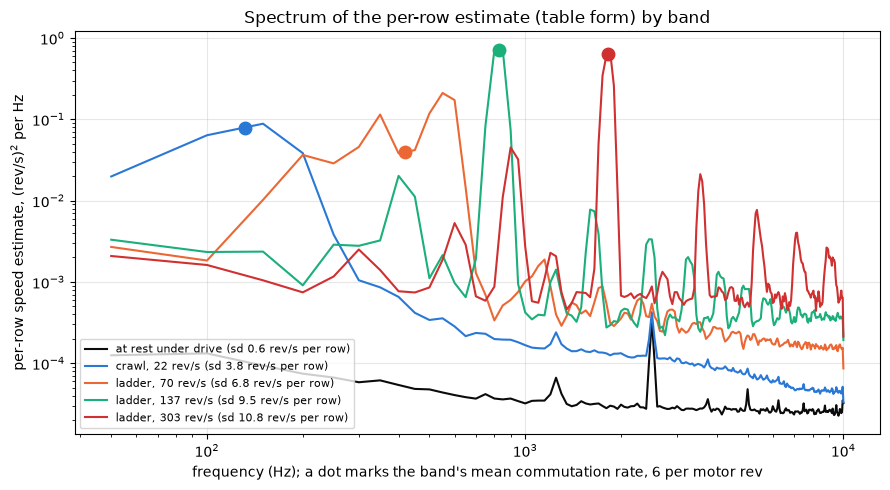

In [71]:
SPEC = [("rest", "rest", "at rest under drive"), ("hold", "0-30", "crawl"),
        ("ladder", "30-100", "ladder"), ("ladder", "100-160", "ladder"),
        ("ladder", "250-350", "ladder")]
B1 = Q1_BANDS.set_index(["kind", "band"])
fig, ax = plt.subplots(figsize=(9, 5))
for (kind, band, what), c in zip(SPEC, (INK, BLUE, ORANGE, GREEN, RED)):
    p, row = PSD[(kind, band)], B1.loc[(kind, band)]
    lab = (f"{what}, {row['truth']:.0f} rev/s" if kind != "rest" else what)
    ax.loglog(PSD_F[1:], p[1:], color=c,
              label=f"{lab} (sd {row['table_sd']:.1f} rev/s per row)")
    if kind != "rest":                      # the band's commutation rate
        fc = PER_REV * row["truth"]
        ax.plot([fc], [np.interp(fc, PSD_F, p)], "o", ms=9, color=c)
ax.legend(loc="lower left", fontsize=8)
figures.label(ax, x="frequency (Hz); a dot marks the band's mean "
              "commutation rate, 6 per motor rev",
              y="per-row speed estimate, (rev/s)$^2$ per Hz",
              title="Spectrum of the per-row estimate (table form) by band")
figures.finish(fig)

What you are looking at. The mean Welch spectrum of the per-row estimate, table form, about each window's parabola, for the rest holds and four speed bands, on log axes. A dot marks each band's mean commutation rate, six events per motor revolution. The legend gives each band's sd per row.

The findings below read a few more numbers, the flat band of the per-row sd, the commutation part's share of the variance, the product form over the table and the tick pattern at rest.

In [72]:
flat = Q1_WIN[(Q1_WIN.truth >= 100) & (Q1_WIN.truth < 350)]
sd_w = np.sqrt(flat["table_var"])
print(f"per-row sd from 100 to 350 rev/s: {sd_w.min():.1f} to "
      f"{sd_w.max():.1f} rev/s over {len(flat)} windows, commutation at "
      f"{PER_REV * flat.truth.min() / 1e3:.1f} to "
      f"{PER_REV * flat.truth.max() / 1e3:.1f} kHz")
for r in Q1_BANDS.itertuples():
    pt = r.product_sd / r.table_sd          # product over table, per row
    print(f"{r.kind:9s} {r.band:8s} comm share {r.table_comm_share * 100:5.1f}"
          f" %, sub {r.table_sub_share * 100:5.1f} %, product / table "
          f"{pt:.2f} ({(pt - 1) * 100:+.0f} %)")
rs = rest_f.set_index("mod")["share"] * 100
rb = B1.loc[("rest", "rest")]
print(f"at rest: tick pattern {rb['table_tick_sd']:.2f} rev/s sd, "
      f"{rb['table_tick_share'] * 100:.1f} % of the variance; by modulus "
      f"mod 8 {rs[8]:.1f} %, mod 16 {rs[16]:.1f} %, mod 2 to 7 at most "
      f"{rs.loc[2:7].max():.1f} %")
print(f"at rest in counts: crest {rb['crest_pp16']:.2f} pp "
      f"({rb['crest_tick_sd']:.2f} sd), tap difference {rb['tap_pp16']:.2f}"
      f" pp ({rb['tap_tick_sd']:.2f} sd)")

per-row sd from 100 to 350 rev/s: 9.1 to 11.1 rev/s over 116 windows, commutation at 0.8 to 1.9 kHz
hold      0-30     comm share  75.6 %, sub  20.8 %, product / table 1.00 (-0 %)
hold      30-100   comm share  77.0 %, sub  19.5 %, product / table 1.00 (+0 %)
hold      160-250  comm share  94.8 %, sub   1.8 %, product / table 1.11 (+11 %)
hold      250-350  comm share  94.6 %, sub   3.6 %, product / table 1.11 (+11 %)
ladder    0-30     comm share  94.6 %, sub   2.3 %, product / table 1.02 (+2 %)
ladder    30-100   comm share  89.8 %, sub   6.4 %, product / table 1.04 (+4 %)
ladder    100-160  comm share  91.2 %, sub   4.3 %, product / table 1.05 (+5 %)
ladder    160-250  comm share  92.8 %, sub   2.7 %, product / table 1.11 (+11 %)
ladder    250-350  comm share  91.6 %, sub   2.4 %, product / table 1.21 (+21 %)
ladder    350-450  comm share  45.7 %, sub   5.0 %, product / table 1.35 (+35 %)
ladder    450-600  comm share  52.4 %, sub  -0.3 %, product / table 1.18 (+18 %)
reference 100-

**Findings.**

- **The per-row noise is the commutation ripple of the current through R.** From 100 to 350 rev/s the commutation part holds 91.2 to 94.8 % of the variance (9.04 to 10.36 of 9.43 to 10.83 rev/s sd), the crest current's sd is 17.37 to 21.25 counts and one count is 0.505 rev/s. It is periodic, not random. The autocorrelation swings to -0.83 at half a commutation period and back to +0.80 at a whole one at 212 rev/s (lags 8 and 16), and to +0.81 at lag 50 at 137.5 rev/s. Confidence high.
- **It moves with the speed.** A commutation period is 152.1 rows at 22 rev/s, 24.2 at 137.5, 11.0 at 303 and 8.1 at 413. No fixed window nulls it at every speed.
- **The flat band.** The per-row sd is 9.1 to 11.1 rev/s over 116 windows from 100 to 350 rev/s. It leaves that band below 100 rev/s (2.5 to 8.8, growing with speed and current) and on the two top rungs (9.9 to 18.5).
- **Under 100 rev/s about a fifth of the variance sits under half the commutation rate** (1.73 to 2.15 rev/s sd). It is either the shaft's real wander at a crawl or the rotation's own orders. This section does not separate the two (section 10 lists the check).
- **The white floor is small and grows with speed.** It is 0.50 rev/s at rest (the current sample's 1.13 counts and the taps' 1.29), 0.71 to 0.88 at the crawl, 1.31 at 70, 1.98 at 137.5 and 2.62 at 303 rev/s. On the two top rungs the split is not resolved. Their windows are 25 to 50 ms on a rung still settling, and the 8.95 and 8.00 rev/s read as white there are most likely smeared ripple, not a floor.
- **The pattern locked to the tick is nearly absent from the speed estimate.** At rest it is 0.18 rev/s sd (8.9 % of the variance), almost all of it period 8 (mod 8 holds 7.6 % against 8.9 % at mod 16, mod 2 to 7 nothing). In counts at rest the crest current carries 1.27 counts peak to peak (0.38 sd) and the tap difference 1.92 (0.53 sd). Under rotation it is 0.10 rev/s or less wherever it can be read. At 212 rev/s (15.7 rows per period) and on the top rungs (8.1 and 7.3) the commutation sits on the pattern's lines and the fold does not tell them apart. Confidence high at rest (70 windows), moderate under rotation.
- **Per input.** The current sample carries everything that matters (3.56 to 14.26 rev/s). The taps carry 0.14 to 1.48 rev/s, their noise multiplied by the duty share. The tracked zero carries under 0.01 rev/s inside a window. Confidence high.
- **The product form is noisier than the table.** It is within 2 % under 50 rev/s, +5 % at 137.5, +11 % at 212, +21 % at 303 and +18 to +35 % on the top rungs, because the current's noise enters its denominator.
- **At rest under a narrow drive the estimate is nearly white**, 0.59 rev/s per row with a lag-1 correlation of +0.16.

The crawl holds at 22 rev/s pool to 17.40 counts of tap sd against about 3 elsewhere, at a mean duty of 7.9 %, at the tap floor of section 9. Most likely a few windows straddle the floor. It moves the estimate by 0.56 rev/s sd at most and is not traced here.

**Alternative readings.** The ripple is real speed ripple rather than an artifact of a constant R and Ke. That is unlikely above 100 rev/s, since a rotor does not follow the commutation rate of 0.8 to 1.9 kHz at 9.1 to 11.1 rev/s sd, and possible at a crawl for the part under half the commutation rate (confidence low and moderate). The floor's growth with speed is brush noise rather than the ripple's sharp edges spread wide. The two are not separated here, and either way the floor is the current's.

In [73]:
nb_cols = ["kind", "band", "n_win", "sweeps", "rows", "truth", "i_ma",
           "duty_pct", "rows_per_commutation", "table_sd", "table_sd_lo",
           "table_sd_hi", "product_sd", "table_comm_sd", "table_sub_sd",
           "table_tick_sd", "table_white_sd", "table_comm_share",
           "table_sub_share", "table_tick_share", "table_white_share",
           "table_r1", "current_sd", "taps_sd", "zero_sd", "crest_sd_counts",
           "tap_sd_counts", "zero_sd_counts", "confounded", "crest_pp16",
           "tap_pp16", "crest_tick_sd", "tap_tick_sd"]
NOISE_CSV = Q1_BANDS[nb_cols].copy()        # the per-row noise and split
q = results.quantity


def band_noise(r):
    """One band's noise for the result file."""
    rc = r.rows_per_commutation
    return {"n": int(r.n_win), "rev_s": q(r.truth, unit="rev/s"),
            "i_ma": q(r.i_ma, unit="mA"),
            "rows_per_commutation": (q(rc, unit="rows") if np.isfinite(rc)
                                     else None),
            "sd": q(r.table_sd, r.table_sd_lo, r.table_sd_hi,
                    "rev/s, range of the windows"),
            "sd_product": q(r.product_sd, r.product_sd_lo, r.product_sd_hi,
                            "rev/s, range of the windows"),
            **{f"{p}_sd": (q(getattr(r, f"table_{p}_sd"), unit="rev/s")
                           if np.isfinite(getattr(r, f"table_{p}_sd"))
                           else None)
               for p in ("comm", "sub", "tick", "white")},
            "lag1": q(r.table_r1, unit="correlation"),
            "current_sd": q(r.current_sd, unit="rev/s"),
            "taps_sd": q(r.taps_sd, unit="rev/s"),
            "zero_sd": q(r.zero_sd, unit="rev/s")}

In [74]:
R_S6 = {
    "row_noise_by_band": {
        kind: {r.band: band_noise(r) for r in g.itertuples()}
        for kind, g in Q1_BANDS.groupby("kind", sort=False)},
    "row_noise_flat_band": q(np.sqrt((flat["table_var"]).mean()),
                             sd_w.min(), sd_w.max(),
                             "rev/s per row, 100 to 350 rev/s, range of "
                             f"{len(flat)} windows"),
    "tick_pattern_rest": {
        "speed_sd": q(rb["table_tick_sd"], unit="rev/s"),
        "share": q(rb["table_tick_share"], unit="of the variance"),
        "share_by_modulus": {str(int(m)): q(v / 100, unit="of the variance")
                             for m, v in rs.items()},
        "period": q(8, unit="ticks"),
        "crest_pp_counts": q(rb["crest_pp16"], unit="counts"),
        "tap_pp_counts": q(rb["tap_pp16"], unit="counts")},
    "row_acf_by_band": {
        f"{r.kind} {r.band}": {str(k): float(getattr(r, f"lag{k}"))
                               for k in LAGS}
        for r in Q1_ACF.itertuples()},
    "row_psd_by_band": {
        f"{k[0]} {k[1]}": {"f_hz": PSD_F[::10].tolist(),
                           "psd_rev_s2_per_hz": PSD[k][::10].tolist()}
        for k in [(a, b) for a, b, _ in SPEC]},
}
print(len(R_S6), "keys for section 6;", len(NOISE_CSV), "noise rows")

5 keys for section 6; 13 noise rows


## 7. The filters

### The candidates

Each candidate runs on the per-row estimate, causal, one update per row at the control tick, and restarts on a `first` row. The DC delay is the one a constant input sees.

- Boxcar of N rows, the mean of the last N rows. State, the last N rows. Delay (N - 1) / 2 rows.
- One-pole of N rows, $y \mathrel{+}= \alpha\,(x - y)$ with $\alpha = 1 - e^{-1/N}$. State, y. Delay $(1 - \alpha)/\alpha$ rows.
- Median of 3, ahead of either or alone. State, the last 3 rows. One row of delay.
- Boxcar locked to k commutation periods, the window per row from a causal speed, a one-pole on the per-row estimate read one row back, and clipped to a shortest and a longest window (the cell below prints the constants). State, the reference and the last rows up to the longest window. Its delay is (N - 1) / 2 rows of the window it holds, so it moves with the speed.

N runs from 8 to 400 rows (0.4 to 20 ms at 20 kHz). The locked boxcar spans 1, 2 or 6 periods (6 is one motor revolution).

In [75]:
SIZES = [8, 16, 32, 64, 100, 200, 400]  # rows: 0.4 to 20 ms at 20 kHz
LOCKS = [1, 2, 6]                       # commutation periods (6 = one rev)
REF_ROWS = 100                          # rows, the lock's speed reference
LOCK_MIN, LOCK_MAX = 4, 800             # rows, the locked window's clip


def lock_n(w, first, k):
    """The locked window per row: k periods at a causal speed."""
    ref = speed.one_pole(w, speed.pole_alpha(REF_ROWS), first)
    ref = np.r_[ref[0], ref[:-1]]           # read one row back: causal
    return speed.lock_rows(ref, FS, PER_REV, k, LOCK_MIN, LOCK_MAX)


def candidates():
    """(name, family, size, nominal delay rows or None, fn(w, first))."""
    out = [("raw", "raw", 0, 0.0, lambda w, f: np.asarray(w, float)),
           ("med3", "med3", 3, 1.0, lambda w, f: speed.median3(w, f))]
    for n in SIZES:
        a = speed.pole_alpha(n)
        out += [
            (f"box {n}", "box", n, (n - 1) / 2,
             lambda w, f, n=n: speed.boxcar(w, n, f)),
            (f"pole {n}", "pole", n, (1 - a) / a,
             lambda w, f, a=a: speed.one_pole(w, a, f)),
            (f"med3+box {n}", "med3+box", n, 1 + (n - 1) / 2,
             lambda w, f, n=n: speed.boxcar(speed.median3(w, f), n, f)),
            (f"med3+pole {n}", "med3+pole", n, 1 + (1 - a) / a,
             lambda w, f, a=a: speed.one_pole(speed.median3(w, f), a, f))]
    for k in LOCKS:
        out += [
            (f"lock {k}", "lock", k, None, lambda w, f, k=k:
             speed.locked_boxcar(w, lock_n(w, f, k), f)),
            (f"med3+lock {k}", "med3+lock", k, None, lambda w, f, k=k:
             speed.locked_boxcar(speed.median3(w, f), lock_n(w, f, k), f))]
    return out


CANDS = candidates()
print(f"{len(CANDS)} candidates; sizes {SIZES} rows, locks {LOCKS} "
      f"periods, reference {REF_ROWS} rows, clip {LOCK_MIN} to {LOCK_MAX}")

36 candidates; sizes [8, 16, 32, 64, 100, 200, 400] rows, locks [1, 2, 6] periods, reference 100 rows, clip 4 to 800


### Noise at steady speed

Each filter runs from the spin's first row, so its state is warm at the window. The noise is the sd of its output over the window about the window's line (a parabola above 250 rev/s, where the rung still settles), pooled as the root of the mean variance. At rest the filters start on the hold's first row, so the first 60 ms are left out and holds shorter than twice that do not count. A 100 ms window holds few independent spans of a 10 or 20 ms filter and the line takes some of them out, so those cells read low.

In [76]:
SEED_ROWS = 1200        # rows, 60 ms for a filter to forget its seed
rows_q2 = []
for r in STEADY.itertuples():
    E = est(r.run0, r.g1, r.ntc_c)
    wt, wp = solve(E)
    m = E["idx"] >= r.g0
    if r.kind == "rest":                    # the hold starts at its window
        m = E["idx"] >= r.g0 + SEED_ROWS
        if m.sum() < SEED_ROWS:
            continue
    if m.sum() < 400:
        continue
    deg = 2 if r.truth > 250 else 1         # still settling above 250
    for name, fam, size, delay, fn in CANDS:
        yt, yp = fn(wt, E["first"]), fn(wp, E["first"])
        nmean = np.nan
        if fam.endswith("lock"):            # the window it held, on average
            nmean = float(lock_n(wt, E["first"], size)[m].mean())
            delay = (nmean - 1) / 2 + (1 if fam.startswith("med3") else 0)
        rows_q2.append(dict(
            kind=r.kind, band=r.band, sweep=r.sweep, filter=name,
            family=fam, size=size, delay=delay,
            var_t=float(np.var(detrend(yt[m], deg))),
            var_p=float(np.var(detrend(yp[m], deg))),
            mean_t=float(yt[m].mean() - wt[m].mean()), n=int(m.sum()),
            lock_rows=nmean))
Q2N = pd.DataFrame(rows_q2)
sq = lambda v: np.sqrt(v.mean())            # noqa: E731
Q2_NOISE = Q2N.groupby(["kind", "band", "filter", "family", "size"],
                       sort=False).agg(
    n_win=("var_t", "size"), sweeps=("sweep", "nunique"),
    delay=("delay", "mean"), sd_table=("var_t", sq),
    sd_product=("var_p", sq), sd_lo=("var_t", lambda v: np.sqrt(v.min())),
    sd_hi=("var_t", lambda v: np.sqrt(v.max())), shift=("mean_t", "mean"),
    lock_rows=("lock_rows", "mean")).reset_index()
print(f"{len(Q2_NOISE)} filter-band cells; rest holds from "
      f"{SEED_ROWS / FS * 1e3:.0f} ms in, {2 * SEED_ROWS / FS * 1e3:.0f} ms "
      "long at least")

468 filter-band cells; rest holds from 60 ms in, 120 ms long at least


In [77]:
SHOW = ["raw", "med3", "box 8", "box 16", "box 32", "box 64", "box 100",
        "box 200", "box 400", "pole 8", "pole 16", "pole 32", "pole 64",
        "pole 100", "pole 200", "pole 400", "med3+box 16", "med3+pole 32",
        "lock 1", "lock 2", "lock 6", "med3+lock 1"]
KEYS = [("rest", "rest"), ("hold", "0-30"), ("hold", "30-100"),
        ("ladder", "30-100"), ("ladder", "100-160"), ("ladder", "160-250"),
        ("ladder", "250-350"), ("ladder", "350-450"), ("ladder", "450-600")]
NZ = Q2_NOISE.set_index(["kind", "band", "filter"])


def cell(k, f, col):
    return NZ.loc[(k[0], k[1], f), col]


print("noise (rev/s, table form) by band")
print(f"{'filter':13s}" + "".join(f"{k[0][:4]:>5s} {k[1]:>7s}" for k in KEYS))
for f in SHOW:
    print(f"{f:13s}" + "".join(f"{cell(k, f, 'sd_table'):13.2f}"
                               for k in KEYS))
for f in ("lock 1", "lock 2", "lock 6"):
    print(f"{f} mean window rows: "
          + " ".join(f"{cell(k, f, 'lock_rows'):6.1f}" for k in KEYS))
print(f"windows per column: {[int(cell(k, 'raw', 'n_win')) for k in KEYS]}")
RATIO = {f: [cell(k, f, "sd_product") / cell(k, f, "sd_table")
             for k in KEYS] for f in ("box 16", "box 100")}
for f, v in RATIO.items():
    print(f"product / table noise, {f}: " + " ".join(f"{x:.2f}" for x in v))

noise (rev/s, table form) by band
filter        rest    rest hold    0-30 hold  30-100 ladd  30-100 ladd 100-160 ladd 160-250 ladd 250-350 ladd 350-450 ladd 450-600
raw                   0.56         4.03         4.93         7.03         9.50        10.54        10.83        12.95        12.09
med3                  0.41         3.98         4.85         6.89         9.22        10.02         9.85         9.62         9.78
box 8                 0.27         3.92         4.78         6.51         7.77         6.58         3.95         4.20         2.77
box 16                0.23         3.86         4.62         5.52         4.34         1.84         2.47         2.78         1.60
box 32                0.21         3.69         4.10         3.40         2.59         1.30         0.93         1.92         1.06
box 64                0.18         3.17         2.81         2.51         1.95         1.16         0.66         1.37         0.68
box 100               0.17         2.61         2

The rest column of the boxcars, against all 70 rest holds scored without the 60 ms seed cut, shows how far the 3 long holds stand for the rest.

In [78]:
all_rest = []
for r in STEADY[STEADY["kind"] == "rest"].itertuples():
    E = est(r.run0, r.g1, r.ntc_c)
    wt, _ = solve(E, form="table")
    m = E["idx"] >= r.g0
    if m.sum() < 400:
        continue
    for n in SIZES:
        y = speed.boxcar(wt, n, E["first"])
        all_rest.append(dict(n=n, var=float(np.var(detrend(y[m], 1)))))
AR = pd.DataFrame(all_rest).groupby("n")["var"].agg(["size", sq])
print(f"rest, all holds without the seed cut ({int(AR['size'].iloc[0])}"
      " holds), boxcar 8 to 400 (rev/s): "
      + " / ".join(f"{v:.2f}" for v in AR.iloc[:, 1]))

rest, all holds without the seed cut (70 holds), boxcar 8 to 400 (rev/s): 0.29 / 0.25 / 0.21 / 0.19 / 0.17 / 0.15 / 0.13


### The duty steps' truth

The steps set holds chains that each run a base duty, then base plus a step, then the base again, in each direction. The truth through a step is the ripple tach, never the pot. The upward crossings of the commutation ripple in the crest current are phase samples, one per commutation period, and a first-order response is fitted to that phase,

$$j = j_0 + 6\,\big[\omega_0\,(t - t_0) + \Delta\omega\,\big((t - t_0) - \tau\,(1 - e^{-(t - t_0)/\tau})\big)\big],\quad t > t_0,$$

with $\omega_0$ the count over the last 100 ms of the segment before (fixed), $t_0$ the row the duty changes, and $j_0$, $\Delta\omega$, $\tau$ ("tau") fitted. A fit counts when its residual is under 0.15 of a commutation period rms.

In [79]:
T = STEPS_T
print(f"steps: {len(T)} transients in {T.sweep.nunique()} sweeps, "
      f"{int(T.ok.sum())} under the residual; residual median "
      f"{T.res_cycles.median():.3f} of a period, max of those "
      f"{T.res_cycles[T.ok].max():.3f}; {int(STEPS_KEPT.sum())} also with "
      "a time constant of 5 to 60 ms and dw the sign of the duty's change")
g = T[T.ok].groupby(["base_pct", "step_pct", "sign"]).agg(
    n=("dw", "size"), w0=("w0", "mean"), dw=("dw", "mean"),
    dw_sd=("dw", "std"), tau_ms=("tau_ms", "median"),
    tau_lo=("tau_ms", "min"), tau_hi=("tau_ms", "max"))
print(g.round(2).to_string())
k = T[STEPS_KEPT]
print(f"kept: tau {k.tau_ms.quantile(0.1):.1f} to {k.tau_ms.quantile(0.9):.1f}"
      f" ms (10th to 90th percentile), median {k.tau_ms.median():.1f} ms")

steps: 85 transients in 26 sweeps, 71 under the residual; residual median 0.070 of a period, max of those 0.147; 60 also with a time constant of 5 to 60 ms and dw the sign of the duty's change
                        n      w0     dw  dw_sd  tau_ms  tau_lo  tau_hi
base_pct step_pct sign                                                 
20       2        -1    4   96.70 -10.76   0.93   16.27   13.23   19.44
                   1    6   84.34  12.86   3.68   14.62   12.90   51.39
         5        -1    4  113.22 -27.20   1.22   16.50   15.09   20.06
                   1    5   85.73  27.94   0.76   17.46   16.44   20.77
         10       -1    5  140.17 -54.65   1.79   19.48   18.00   20.94
                   1    6   84.18  56.52   2.99   18.97   17.37   20.07
30       2        -1    6  151.02 -11.60   1.55   27.89   14.69   72.49
                   1    4  136.51  16.24   5.55   18.27    8.56   36.28
         5        -1    6  162.69 -36.12  23.64   25.39   21.72  300.00
               

### Delay, measured

Each filtered estimate is set against the truth through a transient. The lag is the shift of the truth, in rows, that leaves the smallest rms of the filtered estimate less the shifted truth over the transient's rows, refined by a parabola through the grid's minimum. The unfiltered estimate's own lag in the same transient is taken off as `added`. The peak and rms are of the filtered estimate less the truth (on the steps, less the filter's own offset over a stretch of rows before the step, which is the estimate's and not the filter's).

- Run-ups, product form (the table reads +12 to +30 rev/s high there, section 4). Truth, stage 3's order count per turn, with a point at rest at the run's first row. Rows from the first counted turn to where the truth passes 95 % of its last value.
- Duty steps, table form. Truth, the step's fit. The first four time constants after the step.

No L term here (section 8).

In [80]:
def lag_of(y, k, truth_at, max_rows, lead_rows=12):
    """(lag rows, rms at the lag): the shift of the truth that leaves
    the smallest rms, a parabola through the grid's minimum."""
    taus = np.arange(-float(lead_rows), max_rows + 1.0)
    sd = np.array([np.sqrt(np.mean((y[k] - truth_at(k - t)) ** 2))
                   for t in taus])
    j = int(np.argmin(sd))
    if 0 < j < len(taus) - 1:
        a, b_, c = sd[j - 1], sd[j], sd[j + 1]
        den = a - 2 * b_ + c
        return taus[j] + (0.5 * (a - c) / den if den > 0 else 0.0), b_
    return taus[j], sd[j]


def score_delay(tag, meta, E, w, k, truth_at, form, offset_rows=None):
    """One transient, every candidate: lag, rms at the lag, peak, rms."""
    out = []
    for name, fam, size, delay, fn in CANDS:
        y = fn(w, E["first"])
        off = (float(np.mean(y[offset_rows]
                             - truth_at(offset_rows.astype(float))))
               if offset_rows is not None else 0.0)
        span = size if fam != "raw" and not fam.endswith("lock") else 320
        lag, sd = lag_of(y - off, k, truth_at, 60 + 2.5 * span,
                         150 if offset_rows is not None else 12)
        e = y[k] - truth_at(k.astype(float)) - off
        out.append(dict(tag=tag, form=form, filter=name, family=fam,
                        size=size, nominal=delay if delay is not None
                        else np.nan, lag=lag, sd=sd,
                        peak=float(np.max(np.abs(e))),
                        rms=float(np.sqrt(np.mean(e ** 2))),
                        bias=float(np.mean(e)), offset=off, **meta))
    return out

In [81]:
rows_d, RUNUP_EX = [], None
for (name, kk, dd), g in RUN_W.groupby(["set", "k", "dir"]):
    g = g[g["ok"]].sort_values("t")
    run0 = int(g["run0"].iloc[0])
    E = est(run0, int(g["g1"].max()), float(g["ntc_c"].iloc[0]))
    wt, wp = solve(E)
    tk = np.r_[0.0, g["t"].to_numpy() * FS]     # run rows of the turns
    tv = np.r_[0.0, g["truth"].to_numpy()]      # rev/s, a point at rest
    k_all = (E["idx"] - run0).astype(float)     # run row of each row
    stop = tk[np.argmax(tv >= 0.95 * tv[-1])]
    sel = np.flatnonzero((k_all >= tk[1]) & (k_all <= stop))
    meta = dict(set=name, k=int(kk), dir=int(dd),
                sweep=int(g["sweep"].iloc[0]), n_rows=len(sel),
                accel=float((tv[np.argmax(tv >= 0.95 * tv[-1])] - tv[1])
                            / max(stop - tk[1], 1) * FS / 1e3),
                t_first_ms=float(tk[1] / FS * 1e3))

    def truth_at(x, tk=tk, tv=tv, k_all=k_all):
        """The truth at a (fractional) row position of E."""
        return np.interp(np.interp(x, np.arange(len(k_all)), k_all), tk, tv)
    for form, w in (("table", wt), ("product", wp)):
        rows_d += score_delay("run-up", meta, E, w, sel, truth_at, form)
    if RUNUP_EX is None and dd == 1:            # one run-up for the figure
        RUNUP_EX = dict(t_ms=k_all / FS * 1e3,
                        truth=np.interp(k_all, tk, tv), raw=wp,
                        **{nm: fn(wp, E["first"]) for nm, fam, size, dl, fn
                           in CANDS if nm in ("box 16", "box 64", "lock 2",
                                              "pole 64")})
print(f"{len(rows_d)} run-up scores")

2592 run-up scores


In [82]:
TS = STEPS_T[STEPS_KEPT].reset_index(drop=True)
for r in TS.itertuples():
    E = est(r.run0, r.g1)
    wt, wp = solve(E)
    kstep, kseg = (int(x) for x in np.searchsorted(E["idx"],
                                                   [r.g_step, r.g0]))
    tau_rows = r.tau_ms * 1e-3 * FS

    def truth_at(x, r=r, ks=kstep, tr=tau_rows):
        """The step's first-order fit at a row position of E."""
        return r.w0 + r.dw * (1 - np.exp(-np.maximum(x - ks, 0.0) / tr))
    sel = np.arange(kstep, min(kstep + int(4 * tau_rows), len(wt)))
    pre = np.arange(max(kseg - 1000, 0), kseg)  # the filter's offset
    meta = dict(set=f"base {r.base_pct} step {r.sign * r.step_pct:+d}",
                k=int(r.chain), dir=int(r.dir), sweep=int(r.sweep),
                n_rows=len(sel), accel=float(r.dw / r.tau_ms), t_first_ms=0.0)
    for form, w in (("table", wt), ("product", wp)):
        rows_d += score_delay(f"step {r.step_pct}", meta, E, w, sel,
                              truth_at, form, pre)
Q2D = pd.DataFrame(rows_d)
key = ["tag", "form", "set", "k", "dir"]
raw_lag = Q2D[Q2D["filter"] == "raw"].set_index(key)["lag"]
Q2D["added"] = Q2D["lag"] - raw_lag.reindex(
    pd.MultiIndex.from_frame(Q2D[key])).to_numpy()
print(f"{len(TS)} steps scored, {len(Q2D)} scores in all; a step's offset "
      "over the 1000 rows before it")

60 steps scored, 6912 scores in all; a step's offset over the 1000 rows before it


In [83]:
def se(x):
    return x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan


Q2_DELAY = Q2D.groupby(["tag", "form", "filter", "family", "size"],
                       sort=False).agg(
    n=("lag", "size"), sweeps=("sweep", "nunique"),
    nominal=("nominal", "first"), lag=("lag", "mean"), lag_se=("lag", se),
    lag_sd=("lag", "std"), added=("added", "mean"),
    added_se=("added", se), peak=("peak", "median"),
    peak_max=("peak", "max"), rms=("rms", "median"), bias=("bias", "mean"),
    accel=("accel", "mean")).reset_index()
g0 = Q2D[(Q2D.tag == "run-up") & (Q2D["filter"] == "raw")
         & (Q2D.form == "product")]
print(f"run-ups: {len(g0)} runs in {g0.sweep.nunique()} sweeps, transient "
      f"rows {g0.n_rows.median():.0f} (from {g0.t_first_ms.median():.1f} ms),"
      f" mean acceleration {g0.accel.mean():.1f} rev/s per ms")
for tag in ("step 5", "step 10", "step 2"):
    g1 = Q2D[(Q2D.tag == tag) & (Q2D["filter"] == "raw")
             & (Q2D.form == "table")]
    print(f"{tag} %: {len(g1)} transients in {g1.sweep.nunique()} sweeps, "
          f"|acceleration| {g1.accel.abs().mean():.2f} rev/s per ms")
DZ = Q2_DELAY.set_index(["tag", "form", "filter"])
print("rows: nominal | run-up (product) lag +/- se, added, peak, rms | "
      "step 10 % (table) lag +/- se, added, peak, rms | step 5 % lag, added")
for f in SHOW[:-1]:
    a, b_ = DZ.loc[("run-up", "product", f)], DZ.loc[("step 10", "table", f)]
    c = DZ.loc[("step 5", "table", f)]
    print(f"{f:13s} {a.nominal:6.1f} | {a.lag:6.1f} +/- {a.lag_se:4.1f} "
          f"{a.added:6.1f} {a.peak:6.1f} {a.rms:5.1f} | {b_.lag:6.1f} +/- "
          f"{b_.lag_se:4.1f} {b_.added:6.1f} {b_.peak:5.1f} {b_.rms:5.2f} | "
          f"{c.lag:6.1f} +/- {c.lag_se:4.1f} {c.added:6.1f}")

run-ups: 36 runs in 18 sweeps, transient rows 642 (from 8.7 ms), mean acceleration 8.7 rev/s per ms
step 5 %: 19 transients in 7 sweeps, |acceleration| 1.84 rev/s per ms
step 10 %: 20 transients in 7 sweeps, |acceleration| 3.38 rev/s per ms
step 2 %: 21 transients in 7 sweeps, |acceleration| 0.98 rev/s per ms
rows: nominal | run-up (product) lag +/- se, added, peak, rms | step 10 % (table) lag +/- se, added, peak, rms | step 5 % lag, added
raw              0.0 |    1.8 +/-  0.8    0.0  113.6  23.7 |  -41.2 +/- 13.0    0.0  66.7  9.72 |  -42.2 +/- 20.8    0.0
med3             1.0 |    2.9 +/-  1.0    1.1   65.9  16.7 |  -40.8 +/- 12.3    0.4  50.7  9.38 |  -50.7 +/- 15.5   -8.4
box 8            3.5 |    5.4 +/-  0.8    3.6   33.3   9.1 |  -38.5 +/- 12.6    2.7  35.2  8.07 |  -47.8 +/- 15.8   -5.5
box 16           7.5 |    9.8 +/-  0.8    8.0   23.4   8.2 |  -33.8 +/- 12.8    7.4  22.3  5.68 |  -41.8 +/- 16.8    0.5
box 32          15.5 |   18.2 +/-  0.7   16.4   24.3  10.9 |  -25.1 +/- 

In [84]:
FLAT = []
for tag, form in (("run-up", "product"), ("step 10", "table")):
    for fam, sizes in (("box", [8, 16, 32, 64, 100, 200]),
                       ("pole", [8, 16, 32])):
        for n in sizes:
            a = DZ.loc[(tag, form, f"{fam} {n}")]
            FLAT.append(dict(tag=tag, family=fam, size=n,
                             resid=a.added - a.nominal))
FLAT = pd.DataFrame(FLAT)
print("measured added less nominal delay (rows), run-ups and 10 % steps:")
print(FLAT.groupby(["family"])["resid"].agg(["min", "max"]).round(1))
up100 = FLAT[(FLAT.family == "box") & (FLAT["size"] <= 100)]["resid"]
print(f"boxcar up to 100 rows: {up100.min():+.1f} to {up100.max():+.1f}")
long_p = [DZ.loc[("step 10", "table", f"pole {n}")] for n in (64, 100, 200)]
print("one-pole 64 / 100 / 200 on the 10 % steps, added less nominal: "
      + " / ".join(f"{a.added - a.nominal:+.1f} rows "
                   f"({(a.added / a.nominal - 1) * 100:+.0f} %)"
                   for a in long_p))

measured added less nominal delay (rows), run-ups and 10 % steps:
        min  max
family          
box    -3.3  1.0
pole   -0.7  1.3
boxcar up to 100 rows: -0.8 to +1.0
one-pole 64 / 100 / 200 on the 10 % steps, added less nominal: -2.3 rows (-4 %) / -7.6 rows (-8 %) / -26.8 rows (-13 %)


### Noise against delay

The central figure of this notebook. For four speed bands it sets each candidate's steady noise against its delay, the boxcar, the one-pole and the locked boxcar each as one line. The delay is the nominal one for the fixed filters and the mean window's for the locked one. The flat line is the per-row noise.

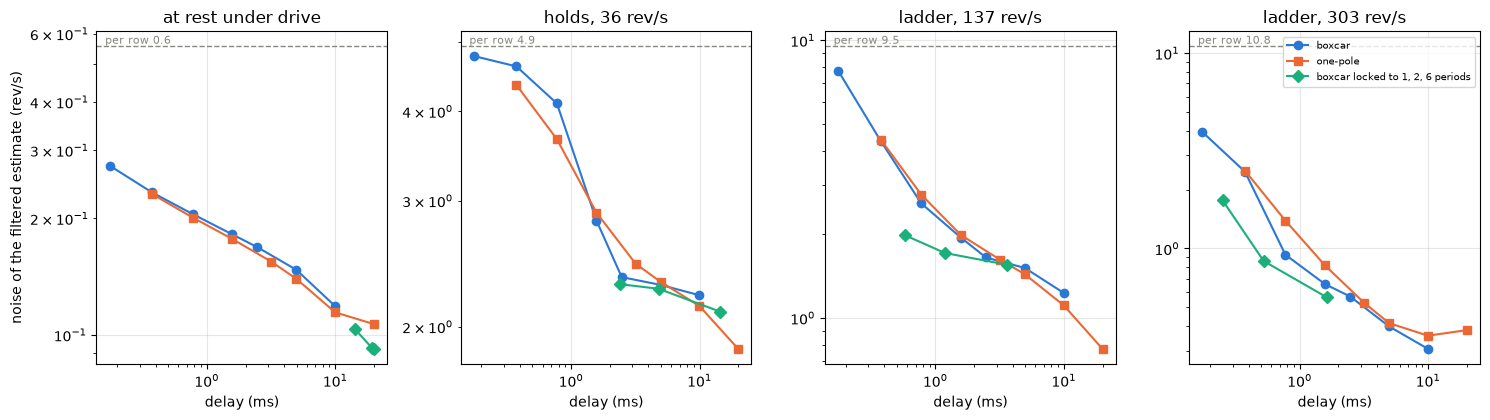

In [85]:
PANELS = [("rest", "rest", "at rest under drive"),
          ("hold", "30-100", "holds, 36 rev/s"),
          ("ladder", "100-160", "ladder, 137 rev/s"),
          ("ladder", "250-350", "ladder, 303 rev/s")]
FAMS = [("box", "boxcar", BLUE, "o"), ("pole", "one-pole", ORANGE, "s"),
        ("lock", "boxcar locked to 1, 2, 6 periods", GREEN, "D")]
ms = 1e3 / FS                               # ms per row
fig, axs = plt.subplots(1, 4, figsize=(15, 4.3), sharex=True)
for ax, (kind, band, title) in zip(axs, PANELS):
    g = Q2_NOISE[(Q2_NOISE.kind == kind) & (Q2_NOISE.band == band)]
    raw = g[g["filter"] == "raw"].sd_table.iloc[0]
    ax.axhline(raw, color=MUTED, lw=1, ls="--")
    ax.text(0.03, raw, f"per row {raw:.1f}", color=MUTED, va="bottom",
            fontsize=8, transform=ax.get_yaxis_transform())
    for fam, lab, c, mk in FAMS:
        h = g[g.family == fam].sort_values("delay")
        ax.loglog(h.delay * ms, h.sd_table, color=c, marker=mk, ms=6,
                  label=lab)
    figures.label(ax, x="delay (ms)", title=title)
axs[0].set_ylabel("noise of the filtered estimate (rev/s)")
axs[3].legend(loc="upper right", fontsize=7.5)
figures.finish(fig)

What you are looking at. Four panels, one per speed band, the steady noise of each filtered estimate (table form, rev/s, log) against its delay (ms, log). Blue is the boxcar from 8 to 400 rows, orange the one-pole over the same range, green the boxcar locked to 1, 2 and 6 commutation periods. The dashed line is the per-row noise.

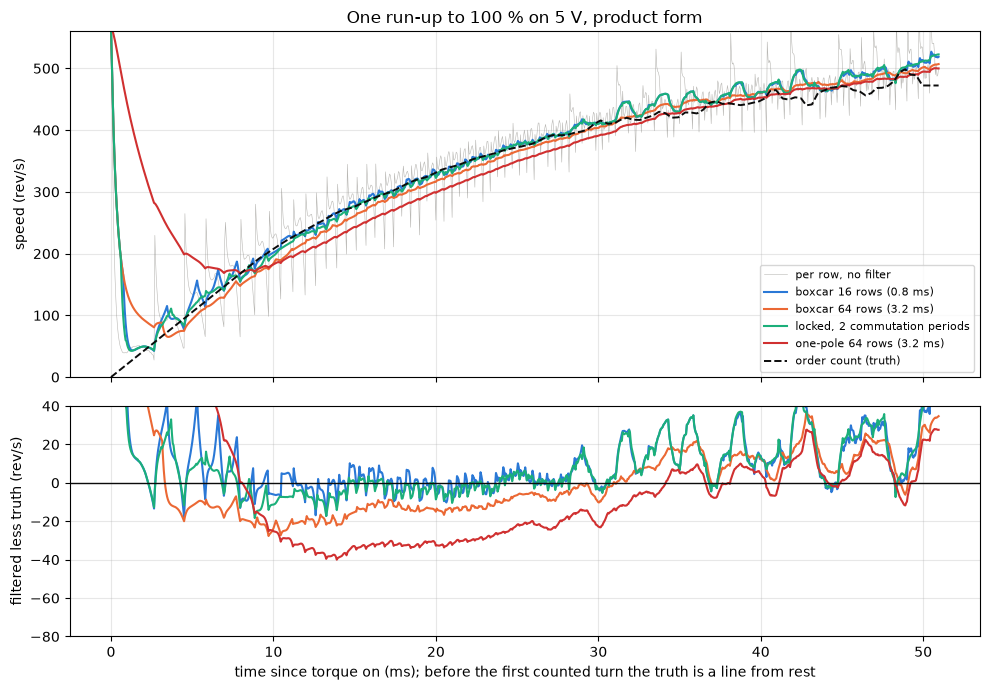

In [86]:
E = RUNUP_EX
t = E["t_ms"]
m = t < 60
show = [("box 16", "boxcar 16 rows (0.8 ms)"),
        ("box 64", "boxcar 64 rows (3.2 ms)"),
        ("lock 2", "locked, 2 commutation periods"),
        ("pole 64", "one-pole 64 rows (3.2 ms)")]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                             gridspec_kw={"height_ratios": [3, 2]})
a1.plot(t[m], E["raw"][m], color=MUTED, lw=figures.TRACE_LW, alpha=0.6,
        label="per row, no filter")
for (key, lab), c in zip(show, (BLUE, ORANGE, GREEN, RED)):
    a1.plot(t[m], E[key][m], color=c, label=lab)
    a2.plot(t[m], (E[key] - E["truth"])[m], color=c)
a1.plot(t[m], E["truth"][m], color=INK, lw=1.4, ls="--",
        label="order count (truth)")
a1.set_ylim(0, 560)
a1.legend(loc="lower right", fontsize=8)
figures.label(a1, y="speed (rev/s)",
              title="One run-up to 100 % on 5 V, product form")
a2.axhline(0, color=INK, lw=1)
a2.set_ylim(-80, 40)
figures.label(a2, x="time since torque on (ms); before the first counted "
              "turn the truth is a line from rest",
              y="filtered less truth (rev/s)")
figures.finish(fig)

What you are looking at. Top, one run-up to 100 % on 5 V, the per-row estimate (product form, gray), four filters on it and stage 3's order count (dashed) over the first 60 ms. Bottom, each filter less the truth. Each filter trails the count by about its delay times the acceleration.

In [87]:
ROWS_FOR = {"rest": ("rest", "rest"), "hold 22": ("hold", "0-30"),
            "hold 36": ("hold", "30-100"), "ladder 70": ("ladder", "30-100"),
            "137": ("ladder", "100-160"), "212": ("ladder", "160-250"),
            "303": ("ladder", "250-350"), "413": ("ladder", "350-450"),
            "457": ("ladder", "450-600")}
for k in (1, 2, 6):                         # the lock against fixed boxcars
    print(f"lock {k}: " + ", ".join(
        f"{lab} {cell(kb, f'lock {k}', 'sd_table'):.2f} (delay "
        f"{cell(kb, f'lock {k}', 'delay'):.1f} rows)"
        for lab, kb in list(ROWS_FOR.items())[3:7]))
med = [(cell(kb, "med3", "sd_table") / cell(kb, "raw", "sd_table") - 1,
        cell(kb, "med3+box 16", "sd_table") / cell(kb, "box 16", "sd_table")
        - 1) for kb in KEYS]
print("median of 3 against none, alone / ahead of a boxcar 16: "
      + "  ".join(f"{lab} {a * 100:+.0f} % / {b * 100:+.0f} %"
                  for lab, (a, b) in zip(ROWS_FOR, med)))

lock 1: ladder 70 2.32 (delay 27.0 rows), 137 1.98 (delay 11.6 rows), 212 1.75 (delay 7.4 rows), 303 1.76 (delay 5.0 rows)
lock 2: ladder 70 2.23 (delay 54.5 rows), 137 1.71 (delay 23.7 rows), 212 1.16 (delay 15.3 rows), 303 0.86 (delay 10.5 rows)
lock 6: ladder 70 2.05 (delay 164.4 rows), 137 1.55 (delay 72.2 rows), 212 0.96 (delay 46.9 rows), 303 0.56 (delay 32.5 rows)
median of 3 against none, alone / ahead of a boxcar 16: rest -26 % / +1 %  hold 22 -1 % / -0 %  hold 36 -2 % / -1 %  ladder 70 -2 % / -1 %  137 -3 % / -1 %  212 -5 % / -1 %  303 -9 % / -5 %  413 -26 % / -17 %  457 -19 % / -12 %


**Findings.**

- **The delay is the nominal DC delay**, (N - 1) / 2 rows for a boxcar and (1 - alpha) / alpha for a one-pole. Measured added less nominal it is -3.3 to +1.0 rows for every boxcar from 8 to 200 rows and -0.6 to +1.3 for every one-pole from 8 to 32 rows, on the run-ups and the 10 % steps alike, and inside -0.8 to +1.0 for the boxcars up to 100 rows. Confidence high (36 run-ups with a lag se of 0.6 to 1.0 rows for the filters up to 100 rows, 20 and 19 steps).
- **A one-pole of 64 rows or more is not a shift of a 30 ms run-up.** It adds 54.4 and 59.1 rows there for 64 and 100 rows nominal, and on the 10 % steps the one-poles of 64, 100 and 200 rows read -2.3, -7.6 and -26.8 rows short of nominal (4, 8 and 13 %).
- **A window locked to the commutation period pays between 70 and 300 rev/s.** One period at 137 rev/s (24.2 rows, delay 11.6) leaves 1.98 rev/s against 2.59 for a fixed 32 (delay 15.5) and 4.34 for a fixed 16. At 303 rev/s (11.0 rows, delay 5.0) it leaves 1.76 against 3.95 for a fixed 8 and 2.47 for a fixed 16. Two periods at 303 (22.0 rows, delay 10.5) leave 0.86 against 0.93 for a fixed 32 at 15.5. In the run-ups one period adds 6.4 rows of lag for 8.5 rev/s rms, against 8.0 rows and 8.2 for a fixed 16. Confidence high for the steady gain (18 windows per band), moderate that it survives a real loop, since the lock rides on its own 5 ms reference.
- **It does not pay at a crawl or at rest.** Under 40 rev/s one period is 96.3 to 254.2 rows and leaves 2.21 to 2.29 rev/s, what a fixed 100 or 200 leaves. The floor there is the part under half the commutation rate of section 6, which no window of 20 ms or less removes.
- **It fails on the top rungs.** At 8.4 rows per period one period leaves 4.21 rev/s against 2.78 for a fixed 16. The window rounds to whole rows and the period is 7 to 8 of them.
- **A fixed boxcar is good only where it happens to span whole periods.** 16 rows leave 1.84 rev/s at 212 rev/s, but 4.34 at 137 and 5.52 at 70.
- **One-pole against boxcar at equal delay.** At 7.5 rows of delay the one-pole is quieter at 70 rev/s (4.85 against 5.52), equal at 137 (4.39 against 4.34) and noisier where the boxcar spans a period (212 rev/s, 3.38 against 1.84). At 31.5 rows the two are close under 160 rev/s (3.17 against 2.93 on the crawl holds, 1.95 against 1.99 at 137), and above it the boxcar is quieter (1.16 against 1.30 at 212, 0.66 against 0.82 at 303).
- **A median of 3 buys little under 350 rev/s.** The ripple is smooth from row to row, so it takes 1 to 9 % off the per-row sd and up to 5 % behind a boxcar of 16, and it costs a row. On the top rungs it takes 26 and 19 % off the per-row sd and 17 and 12 % behind a boxcar of 16. There it removes the single-row dropouts of section 9.
- **No filter of 20 ms or less brings the crawl holds under 1.86 rev/s or the 70 rev/s rung under 1.33.**
- **The product form is noisier behind every filter**, by the same ratio as per row, 0.94 to 1.00 under 100 rev/s, 1.06 at 137, 1.11 at 212, 1.19 to 1.20 at 303 and 1.14 to 1.35 on the top rungs.
- **On the duty steps the unfiltered estimate leads the tach** by 41.2 +/- 13.0 rows on the 10 % steps and 42.2 +/- 20.8 on the 5 % ones. The added delay is free of it. Section 8 returns to the step's excess.

The rest column stands on 3 holds of 120 ms or longer. Its boxcar cells agree within 0.02 rev/s with all 70 rest holds scored without the seed cut, and its one-pole and locked cells stand on the 3 alone, so they carry low confidence. A 100 ms window holds few independent spans of a 10 or 20 ms filter, so the steady noise of the 200 and 400 row filters reads low (confidence high). Each filter keeps the state listed at the head of this section, reads only its size (the locked one also the reference's 100 rows, the clip and the 6 events per revolution) and runs once per row at 20 kHz.

**Alternative readings.** The lock's gain is specific to settled spins and vanishes when the speed moves (confidence low to moderate). In the run-ups it matched a fixed 16 at less delay, but its delay moves with the speed (13.0 rows added on the 10 % steps).

In [88]:
d_cols = ["tag", "form", "filter", "n", "nominal", "lag", "lag_se", "added",
          "added_se", "peak", "rms"]
dl = Q2_DELAY[d_cols].rename(columns={c: f"delay_{c}" for c in d_cols[3:]})
nz = Q2_NOISE[["kind", "band", "filter", "family", "size", "n_win",
               "delay", "sd_table", "sd_product", "sd_lo", "sd_hi",
               "lock_rows"]]
FILTERS_CSV = nz.merge(
    dl[(dl.tag == "run-up") & (dl.form == "product")]
    .drop(columns=["tag", "form"]).add_prefix("runup_")
    .rename(columns={"runup_filter": "filter"}), on="filter", how="left"
).merge(dl[(dl.tag == "step 10") & (dl.form == "table")]
        .drop(columns=["tag", "form"]).add_prefix("step10_")
        .rename(columns={"step10_filter": "filter"}), on="filter",
        how="left")
print(FILTERS_CSV.shape, "filter table rows x columns")

(468, 28) filter table rows x columns


In [89]:
def delay_q(tag, form, f):
    a = DZ.loc[(tag, form, f)]
    return {"n": int(a.n), "nominal_rows": (q(a.nominal, unit="rows")
                                            if np.isfinite(a.nominal)
                                            else None),
            "lag_rows": q(a.lag, a.lag - a.lag_se, a.lag + a.lag_se,
                          "rows, +/- se"),
            "added_rows": q(a.added, unit="rows"),
            "peak_rev_s": q(a.peak, unit="rev/s, median"),
            "rms_rev_s": q(a.rms, unit="rev/s, median")}


def noise_q(f):
    return {lab: q(cell(kb, f, "sd_table"), cell(kb, f, "sd_lo"),
                   cell(kb, f, "sd_hi"), "rev/s, range of the windows")
            for lab, kb in ROWS_FOR.items()
            if (kb[0], kb[1], f) in NZ.index}


TAGS = (("run-up", "product"), ("step 10", "table"), ("step 5", "table"))
R_S7 = {
    "filter_noise_by_band": {f: noise_q(f) for f in SHOW},
    "filter_delay_measured": {f"{t} ({fm})": {f: delay_q(t, fm, f)
                                              for f in SHOW[:-1]}
                              for t, fm in TAGS},
    "filter_delay_flat_band_rows": {
        fam: q(0.0, g["resid"].min(), g["resid"].max(),
               "rows, measured added less nominal, range")
        for fam, g in FLAT.groupby("family")},
    "product_over_table_noise_by_band": {
        f: {lab: q(v, unit="ratio") for lab, v in zip(ROWS_FOR, RATIO[f])}
        for f in RATIO},
}

In [90]:
R_S7["locked_window"] = {
    "periods": list(LOCKS), "min_rows": q(LOCK_MIN, unit="rows"),
    "max_rows": q(LOCK_MAX, unit="rows"),
    "reference_rows": q(REF_ROWS, unit="rows, one-pole, read one back"),
    "noise_by_band": {f"lock {k}": noise_q(f"lock {k}") for k in LOCKS},
    "window_rows_by_band": {
        f"lock {k}": {lab: q(cell(kb, f"lock {k}", "lock_rows"),
                             unit="rows, mean") for lab, kb in
                      ROWS_FOR.items()} for k in LOCKS},
    "added_lag_runup_rows": {f"lock {k}": q(
        DZ.loc[("run-up", "product", f"lock {k}")].added, unit="rows")
        for k in LOCKS},
    "added_lag_step_rows": {f"lock {k}": q(
        DZ.loc[("step 10", "table", f"lock {k}")].added, unit="rows")
        for k in LOCKS}}
kept = STEPS_T[STEPS_KEPT]
R_S7["steps_truth"] = {
    "n": int(len(STEPS_T)), "under_residual": int(STEPS_T.ok.sum()),
    "kept": int(STEPS_KEPT.sum()),
    "residual_periods": q(STEPS_T.res_cycles.median(), unit="periods rms, "
                          "median"),
    "tau_ms_range": q(kept.tau_ms.median(), kept.tau_ms.quantile(0.1),
                      kept.tau_ms.quantile(0.9), "ms, median, 10th to 90th "
                      "percentile of the kept")}
print(len(R_S7), "keys for section 7")

6 keys for section 7


## 8. The L di/dt term

Section 2 found that a two-row difference of the current carries the commutation ripple times L x 20 kHz into the estimate, and that through the table's bend and the product's denominator it moved the run-ups' window means by up to 2.3 rev/s. Section 3 showed the same backward difference on the steady windows, where it multiplies the rows' sd two to five times. This section asks what the term is worth and which causal slope of the current carries it at what cost.

The candidates are no term, the backward difference (`slope_ends` over 1 row), the two-row slope 100 rows apart (section 4's stand-in), the least-squares line over the last 20, 50, 100 and 200 rows (`slope_line`), and a one-pole on the row-to-row difference with time constants of 10, 25 and 50 rows (`slope_pole`), the lines' own delays. Each slope keeps its own trailing rows, or one filtered difference for the one-pole, and restarts on a `first` row. Each is scored three ways.

- The noise it adds per row at steady speed and behind a boxcar, by band, against the estimate with no term.
- The bias it removes on the run-ups' first 50 ms against the order count (product form), on the duty steps' first rows against the tach's phase fit (table form, less the offset before the step), and on the drive flips against the estimate's own later trend carried back (10 flips, not an independent truth).

In [91]:
L_CANDS = [
    ("none", None),
    ("ends 1", lambda i, f: speed.slope_ends(i, 1, FS, f)),
    ("ends 100", lambda i, f: speed.slope_ends(i, 100, FS, f)),
    ("line 20", lambda i, f: speed.slope_line(i, 20, FS, f)),
    ("line 50", lambda i, f: speed.slope_line(i, 50, FS, f)),
    ("line 100", lambda i, f: speed.slope_line(i, 100, FS, f)),
    ("line 200", lambda i, f: speed.slope_line(i, 200, FS, f)),
    ("pole 10", lambda i, f: speed.slope_pole(i, speed.pole_alpha(10), FS, f)),
    ("pole 25", lambda i, f: speed.slope_pole(i, speed.pole_alpha(25), FS, f)),
    ("pole 50", lambda i, f: speed.slope_pole(i, speed.pole_alpha(50), FS, f))]
L_NAMES = [name for name, _ in L_CANDS]


def all_forms(E):
    """{slope: (w table, w product)} per row, each slope's L term on."""
    return {name: solve(E, None if fn is None else fn(E["i_w"], E["first"]))
            for name, fn in L_CANDS}


def se(x):
    """The standard error of a mean."""
    x = np.asarray(x, float)
    return x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan

### The noise it adds

On every steady window of section 6 with 400 rows or more, the per-row sd about the window's line (a parabola above 250 rev/s) for each slope, its sd behind a boxcar, and the shift of the window mean, each against no term.

In [92]:
rows = []
for r in STEADY.itertuples():
    E = est(r.run0, r.g1, r.ntc_c)             # the run up to the window
    m = E["idx"] >= r.g0                       # the window's own rows
    if m.sum() < 400:
        continue
    deg = 2 if r.truth > 250 else 1            # a parabola where settling
    for name, (wt, wp) in all_forms(E).items():
        b32 = speed.boxcar(wt, 32, E["first"])
        rows.append(dict(kind=r.kind, band=r.band, l=name,
                         var_t=np.var(detrend(wt[m], deg)),
                         var_p=np.var(detrend(wp[m], deg)),
                         var_b32=np.var(detrend(b32[m], deg)),
                         mean_t=wt[m].mean(), mean_p=wp[m].mean()))
pooled = ("var_t", "var_p", "var_b32")
LT_NOISE = (pd.DataFrame(rows).groupby(["kind", "band", "l"], sort=False)
            .agg(n=("var_t", "size"),
                 **{c.replace("var", "sd"): (c, lambda v: np.sqrt(v.mean()))
                    for c in pooled},
                 mean_t=("mean_t", "mean"), mean_p=("mean_p", "mean"))
            .reset_index())
none = LT_NOISE[LT_NOISE.l == "none"].set_index(["kind", "band"])
at = pd.MultiIndex.from_frame(LT_NOISE[["kind", "band"]])
for c in ("sd_t", "sd_p", "sd_b32", "mean_t", "mean_p"):
    ref = none[c].reindex(at).to_numpy()       # the no-term value
    LT_NOISE["x_" + c] = LT_NOISE[c].to_numpy() / ref
    LT_NOISE["d_" + c] = LT_NOISE[c].to_numpy() - ref
print(f"{LT_NOISE.groupby(['kind', 'band']).ngroups} kind-bands, "
      f"{int(none['n'].sum())} windows; behind a 32-row boxcar beside")

13 kind-bands, 320 windows; behind a 32-row boxcar beside


In [93]:
KEYS_N = [("rest", "rest"), ("hold", "30-100"), ("ladder", "100-160"),
          ("ladder", "250-350"), ("ladder", "350-450")]
print("per-row sd (table form) as a multiple of no L | behind a 32-row "
      "boxcar | shift of the window mean (rev/s)")
print("          " + "  ".join(f"{k[0][:4]} {k[1]:>7s}" for k in KEYS_N))
for name in L_NAMES[1:]:
    g = LT_NOISE[LT_NOISE.l == name].set_index(["kind", "band"])
    print(f"{name:9s} x "
          + "  ".join(f"{g.x_sd_t[k]:12.2f}" for k in KEYS_N) + " | "
          + " ".join(f"{g.x_sd_b32[k]:5.2f}" for k in KEYS_N) + " | "
          + " ".join(f"{g.d_mean_t[k]:+5.2f}" for k in KEYS_N))
xs = LT_NOISE[LT_NOISE.l != "none"].groupby("l", sort=False)["x_sd_t"]
print("range over every kind-band, per-row sd x no L: " + "; ".join(
    f"{name} {v.min():.2f} to {v.max():.2f}" for name, v in xs))

per-row sd (table form) as a multiple of no L | behind a 32-row boxcar | shift of the window mean (rev/s)
          rest    rest  hold  30-100  ladd 100-160  ladd 250-350  ladd 350-450
ends 1    x         5.34          1.53          1.91          3.08          4.87 |  1.08  1.03  1.26  1.65  1.77 | +0.00 -0.00 -0.04 -0.66 +0.43
ends 100  x         1.07          1.02          1.02          1.03          1.04 |  1.12  1.01  1.01  1.04  1.03 | +0.01 +0.00 +0.00 +0.02 +0.27
line 20   x         1.09          1.13          1.30          1.13          1.03 |  1.11  1.11  1.19  1.13  1.12 | +0.00 +0.00 -0.01 -0.01 +0.28
line 50   x         1.04          1.13          1.00          1.01          1.01 |  1.11  1.12  1.01  1.03  1.06 | +0.00 -0.00 -0.00 +0.02 +0.25
line 100  x         1.03          1.00          1.00          1.00          1.00 |  1.09  1.00  1.00  1.02  1.02 | +0.00 -0.00 +0.00 +0.03 +0.27
line 200  x         1.03          1.00          1.00          1.00          1.00 |  1.07  

### The run-ups

Each of the 36 run-ups to 100 % from its first row, against the order count interpolated to every row, in three bins of time (product form). The acceleration of the truth in each bin gives what a pure lag of L / R predicts, L / R x the acceleration.

In [94]:
BINS = [(0, 15), (15, 30), (30, 50)]          # ms since the run's start
rows = []
for (name, kk, dd), g in RUN_W.groupby(["set", "k", "dir"]):
    g = g[g["ok"]].sort_values("t")
    run0 = int(g["run0"].iloc[0])
    E = est(run0, int(g["g1"].max()), float(g["ntc_c"].iloc[0]))
    k = (E["idx"] - run0).astype(float)         # rows since the start
    tk, tv = g["t"].to_numpy() * FS, g["truth"].to_numpy()
    truth = np.interp(k, tk, tv)                # the order count per row
    acc = np.gradient(truth) * FS / 1e3         # rev/s per ms
    for lname, (wt, wp) in all_forms(E).items():
        for a, b_ in BINS:
            m = (k >= max(a * FS / 1e3, tk[0])) & (k < b_ * FS / 1e3)
            if m.sum() < 20:
                continue
            rows.append(dict(run=f"{name}/{kk}/{dd}", l=lname,
                             bin=f"{a}-{b_} ms",
                             err_p=float(np.mean(wp[m] - truth[m])),
                             err_t=float(np.mean(wt[m] - truth[m])),
                             sd_p=float(np.std(wp[m] - truth[m])),
                             accel=float(acc[m].mean()),
                             w=float(truth[m].mean())))
LT_RUNUP = pd.DataFrame(rows)
print(f"{LT_RUNUP.run.nunique()} run-ups, {len(LT_RUNUP)} bin scores")

36 run-ups, 1080 bin scores


In [95]:
LAG_MS = TAU_E_ROWS / FS * 1e3                  # ms, L / R
piv = LT_RUNUP.pivot_table(index=["run", "bin"], columns="l", values="err_p")
print(f"product form, mean error by bin (rev/s), then the change against "
      f"no L +/- se over {LT_RUNUP.run.nunique()} runs; L/R x acceleration "
      f"predicts +{LAG_MS:.3f} ms x the acceleration")
RUNUP_BINS = {}
for bn in [f"{a}-{b_} ms" for a, b_ in BINS]:
    p = piv.xs(bn, level="bin")
    a = LT_RUNUP[(LT_RUNUP.bin == bn) & (LT_RUNUP.l == "none")]
    RUNUP_BINS[bn] = dict(w=a.w.mean(), accel=a.accel.mean(),
                          predicted=a.accel.mean() * LAG_MS,
                          none=p["none"].mean(), none_se=se(p["none"]),
                          removed={c: ((p[c] - p["none"]).mean(),
                                       se(p[c] - p["none"]))
                                   for c in L_NAMES[1:]})
    q = RUNUP_BINS[bn]
    print(f"  {bn:9s} (n {len(p)}, {q['w']:.0f} rev/s, {q['accel']:.1f} rev/s "
          f"per ms, predicted {q['predicted']:+.2f}): none {q['none']:+.2f}"
          f" +/- {q['none_se']:.2f}; " + "; ".join(
              f"{c} {v[0]:+.2f}+/-{v[1]:.2f}"
              for c, v in q["removed"].items()))
sdp = LT_RUNUP.pivot_table(index="bin", columns="l", values="sd_p",
                           aggfunc=lambda v: np.sqrt(np.mean(v ** 2)))
print("  per-row sd of the error, 15-30 ms: " + "; ".join(
    f"{c} {sdp.loc['15-30 ms', c]:.0f}" for c in L_NAMES))

product form, mean error by bin (rev/s), then the change against no L +/- se over 36 runs; L/R x acceleration predicts +0.196 ms x the acceleration
  0-15 ms   (n 36, 241 rev/s, 14.6 rev/s per ms, predicted +2.87): none -2.60 +/- 0.46; ends 1 +2.85+/-0.23; ends 100 +2.76+/-0.02; line 20 +2.53+/-0.02; line 50 +2.54+/-0.02; line 100 +2.74+/-0.02; line 200 +2.92+/-0.02; pole 10 +2.62+/-0.03; pole 25 +2.62+/-0.02; pole 50 +2.30+/-0.01
  15-30 ms  (n 36, 357 rev/s, 8.8 rev/s per ms, predicted +1.72): none -1.90 +/- 0.38; ends 1 +1.96+/-0.08; ends 100 +1.56+/-0.01; line 20 +1.39+/-0.01; line 50 +1.45+/-0.01; line 100 +1.55+/-0.01; line 200 +1.81+/-0.01; pole 10 +1.45+/-0.01; pole 25 +1.48+/-0.01; pole 50 +1.57+/-0.01
  30-50 ms  (n 36, 458 rev/s, 3.7 rev/s per ms, predicted +0.73): none +7.41 +/- 1.18; ends 1 +1.11+/-0.07; ends 100 +0.73+/-0.01; line 20 +0.68+/-0.01; line 50 +0.69+/-0.01; line 100 +0.72+/-0.01; line 200 +0.80+/-0.01; pole 10 +0.73+/-0.02; pole 25 +0.71+/-0.01; pole 50 +0.74+

The noise first. The backward difference multiplies the rows' sd by 5.34 at rest and by 1.53, 1.91, 3.08 and 4.87 at the crawl, on the ladder's 100-160, 250-350 and 350-450 bands, and it moves the window mean by -0.66 rev/s at 250-350 and +0.43 at 350-450. The lines over 100 and 200 rows cost 1.00 to 1.04 and 1.00 to 1.03 times the rows' sd over every kind and band, and behind a 32-row boxcar the 100-row line costs 1.00 to 1.02 under rotation and 1.09 at rest. The shorter lines and the one-poles cost more (line 20 up to 1.35, line 50 up to 1.13, one-poles of 10, 25 and 50 rows up to 1.36, 1.15 and 1.07), most where the window is near a commutation period. Confidence high.

On the run-ups the estimate with no term reads -2.60 +/- 0.46 rev/s over the first 15 ms and -1.90 +/- 0.38 over the next 15. The current falls as the speed rises, so L di/dt = -(L / R) Ke dw/dt and the missing term is a lag of L / R, 0.196 ms. Against the truth's own acceleration of 14.6, 8.8 and 3.7 rev/s per ms that lag predicts +2.87, +1.72 and +0.73 rev/s. The 100-row line removes +2.74, +1.55 and +0.72 (paired se 0.02 or less), and the other slopes remove as much over the first 15 ms (lines of 20, 50 and 200 rows +2.53, +2.54 and +2.92, one-poles +2.62, +2.62 and +2.30). The backward difference removes +2.85, +1.96 and +1.11 at a per-row sd of 106 rev/s against 22 with no term. Confidence high that under smooth acceleration the term is a pure L / R lag. From 30 ms the product form's own bias at the top of the run (+7.41) dominates and the slopes still remove what the lag predicts.

### The duty steps

The duty steps of the steps set, with the tach's first-order fit as the truth, kept by the fit's residual and time constant (the limits are printed below) when the speed moved the way the duty did. The error is taken in the step's direction, less the estimate's offset over the rows before the step, over four spans of rows after it. The step's size in volts, over Ke, is read from the applied volts 10 to 39 rows after the step against the rows before.

In [96]:
T8 = STEPS_T[STEPS_T.ok & (STEPS_T.tau_ms > 5) & (STEPS_T.tau_ms < 60)
             & (np.sign(STEPS_T.dw) == STEPS_T.sign)].reset_index(drop=True)
SPANS = [(0, 4), (4, 10), (10, 40), (40, 100)]  # rows after the step
rows = []
for r in T8.itertuples():
    E = est(r.run0, r.g1)
    ks, kseg = np.searchsorted(E["idx"], [r.g_step, r.g0])
    tau_rows = r.tau_ms * 1e-3 * FS
    k = np.arange(len(E["idx"]), dtype=float)
    truth = r.w0 + r.dw * (1 - np.exp(-np.maximum(k - ks, 0.0) / tau_rows))
    pre = slice(max(kseg - 1000, 0), kseg)      # the rows before the step
    dv = float(E["v_c"][ks + 10:ks + 40].mean() - E["v_c"][pre].mean())
    di = float(E["i_w"][ks + 10:ks + 40].mean() - E["i_w"][pre].mean())
    for lname, (wt, wp) in all_forms(E).items():
        off = float(np.mean(wt[pre] - r.w0))    # the offset before it
        for a, b_ in SPANS:
            e = wt[ks + a:ks + b_] - truth[ks + a:ks + b_] - off
            rows.append(dict(tr=f"{r.sweep}/{r.g_step}",
                             step=r.sign * r.step_pct, base=r.base_pct,
                             l=lname, span=f"{a}-{b_}",
                             err=float(e.mean()) * r.sign,
                             dv_ke=abs(dv) / KE, dv=dv, di=di, w0=r.w0,
                             dw=r.dw))
LT_STEPS = pd.DataFrame(rows)
tau_lo, tau_hi = windows.KEEP_TAU_MS            # ms, a kept time constant
print(f"{len(T8)} steps kept, {LT_STEPS.tr.nunique()} scored; fit residual"
      f" under {windows.KEEP_CYCLES} periods, time constant {tau_lo:g} to "
      f"{tau_hi:g} ms; the offset over the 1000 rows before the step")
print("spans (rows after the step): "
      + ", ".join(f"{a}-{b_ - 1}" for a, b_ in SPANS))

60 steps kept, 60 scored; fit residual under 0.15 periods, time constant 5 to 60 ms; the offset over the 1000 rows before the step
spans (rows after the step): 0-3, 4-9, 10-39, 40-99


In [97]:
big = LT_STEPS[LT_STEPS.step.abs() >= 5]
piv = big.pivot_table(index=["tr", "span"], columns="l", values="err")
one = big[(big.l == "none") & (big.span == "0-4")]
print(f"duty steps of 5 and 10 % (n {one.tr.nunique()}): the step in volts "
      f"is {one.dv_ke.mean():.0f} rev/s of Ke; error in the step's direction"
      " (rev/s) by rows after the step, mean +/- se")
STEP_SPANS = {}
for sp in [f"{a}-{b_}" for a, b_ in SPANS]:
    p = piv.xs(sp, level="span")
    STEP_SPANS[sp] = {c: (p[c].mean(), se(p[c])) for c in L_NAMES}
    print(f"  rows {sp:6s}: " + "; ".join(
        f"{c} {v[0]:+.1f}+/-{v[1]:.1f}" for c, v in STEP_SPANS[sp].items()))
DV_KE = one.dv_ke.mean()                        # rev/s, the volts' step
share = {sp: STEP_SPANS[sp]["none"][0] / DV_KE for sp in STEP_SPANS}
print("  share of the volts' step, no L: " + "; ".join(
    f"rows {sp} {v:.3f}" for sp, v in share.items()))
q = LT_STEPS[(LT_STEPS.l == "none") & (LT_STEPS.span == "10-40")].copy()
q["dr"] = q.err * q.step.map(np.sign) * KE / q.di   # ohms on the step
q["share"] = q.err / q.dv_ke
STEP_EXCESS = {}
for stp, g in q.groupby(q.step.abs()):
    STEP_EXCESS[int(stp)] = g
    print(f"  step {stp:2d} %: rows 10-40 read {g.err.mean():+.2f} +/- "
          f"{se(g.err):.2f} rev/s past the truth = "
          f"{100 * g.share.mean():.1f} % of the volts' step; current step "
          f"{1e3 * g.di.abs().mean():.0f} mA; as ohms {g.dr.mean():+.2f} "
          f"+/- {se(g.dr):.2f} (n {len(g)})")

duty steps of 5 and 10 % (n 39): the step in volts is 47 rev/s of Ke; error in the step's direction (rev/s) by rows after the step, mean +/- se
  rows 0-4   : none +35.6+/-2.3; ends 1 +11.9+/-2.3; ends 100 +35.0+/-2.3; line 20 +34.6+/-2.4; line 50 +35.5+/-2.3; line 100 +35.5+/-2.3; line 200 +35.6+/-2.3; pole 10 +30.8+/-2.4; pole 25 +33.6+/-2.3; pole 50 +34.6+/-2.3
  rows 4-10  : none +14.2+/-1.2; ends 1 +6.4+/-1.6; ends 100 +12.9+/-1.2; line 20 +7.5+/-1.4; line 50 +12.9+/-1.2; line 100 +13.8+/-1.2; line 200 +14.1+/-1.2; pole 10 +5.8+/-1.4; pole 25 +9.9+/-1.3; pole 50 +11.9+/-1.2
  rows 10-40 : none +5.4+/-0.5; ends 1 +5.2+/-0.6; ends 100 +3.9+/-0.5; line 20 +1.8+/-0.6; line 50 +1.5+/-0.5; line 100 +3.9+/-0.5; line 200 +4.9+/-0.5; pole 10 +2.8+/-0.6; pole 25 +2.7+/-0.5; pole 50 +3.4+/-0.5
  rows 40-100: none +3.6+/-0.4; ends 1 +4.0+/-0.5; ends 100 +2.2+/-0.4; line 20 +3.9+/-0.5; line 50 +3.5+/-0.4; line 100 +2.0+/-0.4; line 200 +2.7+/-0.4; pole 10 +3.8+/-0.5; pole 25 +3.3+/-0.4; pole 50

A duty step reads as speed at once. Over the 39 steps of 5 and 10 % the volts' step is 47 rev/s of Ke, and with no term the estimate reads +35.6 +/- 2.3 rev/s past the truth in the step's direction over rows 0 to 3, +14.2 +/- 1.2 over rows 4 to 9, +5.4 +/- 0.5 over rows 10 to 39 and +3.6 +/- 0.4 over rows 40 to 99. As shares of the volts' step that is 0.751, 0.299, 0.114 and 0.077. Only the backward difference follows the first rows (+11.9, +6.4), at its noise. The 100-row line leaves +35.5 and +13.8 there and takes rows 10 to 39 to +3.9 and rows 40 to 99 to +2.0. Confidence high.

Part of the step's excess is not the L term. At rows 10 to 39, after the L / R spike, the estimate still reads +0.72 +/- 0.50, +3.41 +/- 0.67 and +7.27 +/- 0.62 rev/s past the truth on the 2, 5 and 10 % steps, 5.3, 10.8 and 11.6 % of the volts' step. Over the current's step of 19, 45 and 89 mA that is +0.51 +/- 0.23, +0.62 +/- 0.13 and +0.61 +/- 0.06 ohm, as if the winding read 0.61 ohm more under a step than the R the estimate carries. Every slope leaves part of it. This is an open discrepancy, not a term to carry, and section 10 lists the experiment that separates its causes.

### The drive flips

The two reversal sets hold 10 flips of the drive's direction with 60 clean rows before and 400 after. The reference is the estimate's own later trend with no term, a parabola over rows 60 to 400 after the flip, carried back to the flip.

In [98]:
rev = SW[SW["ds"].isin(["reversal-1", "reversal-9"])]
rows = []
for s in rev.itertuples():
    E = est(int(s.i0), int(s.i1))
    forms = all_forms(E)
    for f in np.flatnonzero(E["flip"]):
        if (f + 400 > len(E["idx"]) or E["first"][f - 60:f + 400].any()
                or E["flip"][f + 1:f + 400].any()):
            continue                            # a clean flip only
        k = np.arange(60, 400)
        ref_fit = np.polyfit(k, forms["none"][0][f + 60:f + 400], 2)
        for lname, (wt, wp) in forms.items():
            for a, b_ in [(0, 4), (4, 10), (10, 30), (30, 60)]:
                kk = np.arange(a, b_)
                rows.append(dict(
                    flip=f"{s.Index}/{f}", l=lname, span=f"{a}-{b_}",
                    err=float(np.mean(wt[f + a:f + b_]
                                      - np.polyval(ref_fit, kk))),
                    w_before=float(-wt[f - 40:f].mean()),
                    w_ref0=float(np.polyval(ref_fit, 0)),
                    i_min=float(E["i_w"][f:f + 10].min()),
                    slope=float(ref_fit[1] * FS / 1e3)))
LT_REV = pd.DataFrame(rows)
print(f"{LT_REV.flip.nunique()} flips in {rev.shape[0]} sweeps; spans "
      "0-3, 4-9, 10-29, 30-59 rows after the flip")

10 flips in 5 sweeps; spans 0-3, 4-9, 10-29, 30-59 rows after the flip

In [99]:
one = LT_REV[(LT_REV.l == "none") & (LT_REV.span == "0-4")]
print(f"reversals: {one.flip.nunique()} flips; speed before the flip "
      f"{one.w_before.mean():+.0f} rev/s in the new drive's direction, the "
      f"later trend carried back {one.w_ref0.mean():+.0f}, its slope "
      f"{one.slope.mean():+.1f} rev/s per ms; error against it, mean +/- se")
piv = LT_REV.pivot_table(index=["flip", "span"], columns="l", values="err")
REV_SPANS = {}
for sp in ("0-4", "4-10", "10-30", "30-60"):
    p = piv.xs(sp, level="span")
    REV_SPANS[sp] = {c: (p[c].mean(), se(p[c])) for c in L_NAMES}
    print(f"  rows {sp:6s}: " + "; ".join(
        f"{c} {v[0]:+.1f}+/-{v[1]:.1f}" for c, v in REV_SPANS[sp].items()))

reversals: 10 flips; speed before the flip -74 rev/s in the new drive's direction, the later trend carried back -58, its slope +7.8 rev/s per ms; error against it, mean +/- se
  rows 0-4   : none +100.9+/-17.5; ends 1 +59.9+/-7.5; ends 100 +100.8+/-17.2; line 20 +101.5+/-17.0; line 50 +101.1+/-17.4; line 100 +101.0+/-17.4; line 200 +100.9+/-17.4; pole 10 +99.4+/-15.8; pole 25 +100.4+/-16.7; pole 50 +100.7+/-17.1
  rows 4-10  : none +38.1+/-6.7; ends 1 -1.3+/-3.5; ends 100 +34.7+/-5.9; line 20 +24.6+/-3.6; line 50 +35.7+/-6.1; line 100 +37.5+/-6.5; line 200 +37.9+/-6.6; pole 10 +12.9+/-2.9; pole 25 +26.2+/-4.5; pole 50 +31.8+/-5.5
  rows 10-30 : none +4.1+/-2.7; ends 1 +0.9+/-2.4; ends 100 -0.2+/-1.9; line 20 -13.8+/-1.5; line 50 -6.3+/-1.2; line 100 +0.9+/-2.1; line 200 +3.2+/-2.5; pole 10 -8.4+/-1.4; pole 25 -6.1+/-1.3; pole 50 -2.5+/-1.6
  rows 30-60 : none -1.4+/-1.2; ends 1 +0.1+/-1.4; ends 100 -5.7+/-1.3; line 20 -0.4+/-1.4; line 50 -8.6+/-1.7; line 100 -7.6+/-1.5; line 200 -3.5+/

After a flip of the drive the estimate with no term reads +100.9 +/- 17.5 rev/s over rows 0 to 3 and +38.1 +/- 6.7 over rows 4 to 9 against its own later trend, then +4.1 +/- 2.7 and -1.4 +/- 1.2. The backward difference takes the first rows to +59.9 +/- 7.5 and -1.3 +/- 3.5. A long slope remembers the current's jump for its whole window. The 20-row line reads -13.8 rev/s over rows 10 to 29, the 50-row line -6.3 there and -8.6 over rows 30 to 59, the 100-row line -7.6 over rows 30 to 59. Confidence moderate, 10 flips with the estimate's own later trend as the reference.

### Behind the velocity filter

A velocity loop reads the estimate behind a filter, so the term is also scored there. A boxcar of n rows over the backward-difference term telescopes to the two-row slope n apart, L (i[k] - i[k-n]) fs / n ("ends n"). Each slope is scored behind a boxcar of 16, 32 and 64 rows and behind the boxcar locked to one commutation period, whose own slope is taken across the same locked window. The window locked to the period reads its length per row from a 100-row one-pole of the per-row speed, read one row back, and clipped (the cell prints the limits). The truth is delayed by the boxcar's own (n - 1) / 2 rows. The steps are those of 5 and 10 %.

In [100]:
LOCK_REF_ROWS, LOCK_MIN, LOCK_MAX = 100, 4, 800   # the locked window


def lock_window_rows(w, first, periods):
    """Rows per window of `periods` commutation periods at a causal speed:
    a one-pole of the per-row speed, read one row back."""
    ref = speed.one_pole(w, speed.pole_alpha(LOCK_REF_ROWS), first)
    ref = np.r_[ref[0], ref[:-1]]
    return speed.lock_rows(ref, FS, PER_REV, periods, LOCK_MIN, LOCK_MAX)


def variants(E, n):
    """{slope: (table, product)} behind a boxcar of n rows (n = 0: the
    boxcar locked to one commutation period), and the window per row."""
    f, i = E["first"], E["i_w"]
    if n == 0:
        nr = lock_window_rows(solve(E)[0], f, 1)
        j = np.maximum(np.arange(len(i)) - nr, 0)
        f1 = np.asarray(f, bool).copy()
        f1[0] = True                            # row 0 starts a run
        ends = np.where(speed.rows_since(f1) >= nr, (i - i[j]) * FS / nr, 0.0)
        box = lambda w: speed.locked_boxcar(w, nr, f)       # noqa: E731
        slopes = {"none": None, "ends n": ends,
                  "line 100": speed.slope_line(i, 100, FS, f)}
    else:
        nr = np.full(len(i), n)
        box = lambda w: speed.boxcar(w, n, f)               # noqa: E731
        slopes = {"none": None, "ends n": speed.slope_ends(i, n, FS, f),
                  "line n": speed.slope_line(i, n, FS, f),
                  "line 100": speed.slope_line(i, 100, FS, f),
                  "ends 1": speed.slope_ends(i, 1, FS, f)}
    out = {}
    for name, s in slopes.items():
        wt, wp = solve(E, s)
        out[name] = (box(wt), box(wp))
    return out, nr


print(f"locked window: {LOCK_REF_ROWS}-row reference, {LOCK_MIN} to "
      f"{LOCK_MAX} rows")

locked window: 100-row reference, 4 to 800 rows


In [101]:
T8B = T8[T8.step_pct >= 5].reset_index(drop=True)
rows_b = []


def behind_steps(n):
    """The steps behind filter n: first n rows, next n rows, the peak."""
    for r in T8B.itertuples():
        E = est(r.run0, r.g1)
        V, nr = variants(E, n)
        ks, kseg = np.searchsorted(E["idx"], [r.g_step, r.g0])
        m = int(nr[ks]) if n == 0 else n        # the filter's own rows
        k = np.arange(len(E["idx"]), dtype=float) - (m - 1) / 2
        truth = r.w0 + r.dw * (1 - np.exp(-np.maximum(k - ks, 0.0)
                                          / (r.tau_ms * 1e-3 * FS)))
        pre = slice(max(kseg - 1000, 0), kseg)
        for name, (yt, yp) in V.items():
            e = (yt - truth - np.mean(yt[pre] - r.w0)) * r.sign
            for what, v in (("step, first n rows", e[ks:ks + m].mean()),
                            ("step, next n rows",
                             e[ks + m:ks + 2 * m].mean()),
                            ("step, peak", e[ks:ks + 4 * m].max())):
                rows_b.append(dict(n=n, what=what, l=name,
                                   id=f"{r.sweep}/{r.g_step}", v=float(v)))

In [102]:
def behind_runups(n):
    """The run-ups behind filter n, 0-15 and 15-30 ms (product form)."""
    for (name_, kk, dd), g in RUN_W.groupby(["set", "k", "dir"]):
        g = g[g["ok"]].sort_values("t")
        run0 = int(g["run0"].iloc[0])
        E = est(run0, int(g["g1"].max()), float(g["ntc_c"].iloc[0]))
        V, nr = variants(E, n)
        k = (E["idx"] - run0).astype(float)
        tk = np.r_[0.0, g["t"].to_numpy() * FS]  # from rest at row 0
        tv = np.r_[0.0, g["truth"].to_numpy()]
        truth = np.interp(k - (nr - 1) / 2, tk, tv)  # delayed as the box
        for name, (yt, yp) in V.items():
            for a, b_ in ((0, 15), (15, 30)):
                msk = ((k >= max(a * FS / 1e3, tk[1] + 64))
                       & (k < b_ * FS / 1e3))
                rows_b.append(dict(n=n, what=f"run-up {a}-{b_} ms", l=name,
                                   id=f"{name_}/{kk}/{dd}",
                                   v=float(np.mean(yp[msk] - truth[msk]))))


def behind_steady(n):
    """The steady windows behind filter n: the filtered noise."""
    for r in STEADY.itertuples():
        if (r.band not in ("rest", "30-100", "100-160", "250-350")
                or r.kind == "reference"):
            continue
        E = est(r.run0, r.g1, r.ntc_c)
        m = E["idx"] >= r.g0
        if m.sum() < 400:
            continue
        V, nr = variants(E, n)
        deg = 2 if r.truth > 250 else 1
        for name, (yt, yp) in V.items():
            rows_b.append(dict(n=n, what=f"noise {r.kind} {r.band}", l=name,
                               id=str(r.Index),
                               v=float(np.var(detrend(yt[m], deg)))))

In [103]:
for n in (16, 32, 64, 0):
    behind_steps(n)
    behind_runups(n)
    behind_steady(n)
Qb = pd.DataFrame(rows_b)
noise = Qb.what.str.startswith("noise")
LT_BEHIND = pd.concat([
    Qb[~noise].groupby(["n", "what", "l"], sort=False).v.agg(
        mean="mean", se=se, cnt="size"),
    Qb[noise].groupby(["n", "what", "l"], sort=False).v.agg(
        mean=lambda v: np.sqrt(v.mean()), se=lambda v: np.nan,
        cnt="size")]).reset_index()
for n in (16, 32, 64, 0):
    print("behind " + ("the boxcar locked to one commutation period"
                       if n == 0 else f"a boxcar of {n} rows") + ":")
    g = LT_BEHIND[LT_BEHIND.n == n]
    for what in g.what.unique():
        h = g[g.what == what]
        print(f"  {what:22s} (n {int(h.cnt.iloc[0]):3d}) " + "; ".join(
            f"{x.l} {x['mean']:+.2f}"
            + (f"+/-{x.se:.2f}" if np.isfinite(x.se) else "")
            for _, x in h.iterrows()))
for d in (7.5, 15.5, 31.5):                     # rows, filter delays
    print(f"filter delay {d:5.1f} rows: L / R is {TAU_E_ROWS / d:.2f} of it")

behind a boxcar of 16 rows:
  step, first n rows     (n  39) none +12.81+/-0.94; ends n +9.60+/-0.92; line n +9.46+/-0.93; line 100 +12.66+/-0.94; ends 1 +5.57+/-0.70
  step, next n rows      (n  39) none +7.35+/-0.62; ends n +1.26+/-0.69; line n +1.26+/-0.71; line 100 +6.35+/-0.59; ends 1 +4.74+/-0.64
  step, peak             (n  39) none +18.44+/-0.88; ends n +15.77+/-0.67; line n +16.19+/-0.68; line 100 +18.10+/-0.87; ends 1 +14.03+/-0.43
  run-up 0-15 ms         (n  36) none -3.02+/-0.46; ends n -0.66+/-0.46; line n -0.72+/-0.45; line 100 -0.47+/-0.46; ends 1 -0.01+/-0.50
  run-up 15-30 ms        (n  36) none -1.99+/-0.37; ends n -0.53+/-0.37; line n -0.56+/-0.37; line 100 -0.41+/-0.37; ends 1 -0.10+/-0.38
  noise ladder 30-100    (n  34) none +5.52; ends n +7.18; line n +7.37; line 100 +5.57; ends 1 +6.29
  noise ladder 100-160   (n  18) none +4.34; ends n +5.67; line n +6.38; line 100 +4.34; ends 1 +5.96
  noise ladder 250-350   (n  18) none +2.47; ends n +3.45; line n +2.73; lin

Behind a filter the step's spike spreads into the filter's span. Behind a boxcar of 32 rows the steps read +8.59 rev/s over its first 32 rows and +5.26 over the next 32 with no term. The slope across the boxcar's own span (ends n) takes them to +6.66 and +2.55, the 100-row line to +8.27 and +3.54. On the run-ups behind the same boxcar the 100-row line takes the first 15 ms from -3.22 to -0.61 rev/s (se 0.46 to 0.47). The noise behind the boxcar barely moves with the 100-row line (2.59 to 2.60 rev/s at 100-160) and grows with the slope across the boxcar's span (2.59 to 2.85), more so behind 16 rows (4.34 to 5.67) and less behind 64 (1.95 to 2.01). Behind the boxcar locked to one commutation period the picture is the same.

What the term is worth. Its whole worth at speed is L / R of lag, 3.93 rows, about 2.9 rev/s at the run-ups' hardest acceleration and nothing at steady speed. Set against a filter's own delay it is 0.52 of a delay of 7.5 rows, 0.25 of 15.5 rows and 0.12 of 31.5 rows.

- With a velocity filter of 32 rows of delay or more, the term is left out and the 4 rows of lag are accounted in the loop.
- With a shorter filter, the term is carried as the least-squares line over the last 100 rows. It costs no noise and removes the lag. Its state is the last 100 rows of the winding current, updated once per row, and it restarts on torque on and after a flip, since for its own length after either it reads the current's jump.
- The backward difference and the lines under 50 rows are not used.
- The first rows of a duty step are not this term's job in any causal form quiet enough to use. They are a direct path from the duty to the estimate that the loop design reads (section 9).

## 9. The valid flag

Where the per-row estimate is not to be trusted, each as a rule from the servo's own signals and constants, so the same rule works on a servo this notebook never saw.

- (a) The tap floor. Under a narrow on-time the crest tap does not reach the rail.
- (b) The dropout rows. A row whose current falls far under its recent level.
- (c) The start-up rows. The first rows after torque on or a flip, before the current builds.
- (d) The stopped rotor. Not a flag, a bias by current.

### (a) The tap floor

Every steady driven run of the 521 sweeps (one duty throughout, long enough, the pot not swept across the travel, the limits printed below) gives its second half's median V_on, its tap noise about a line and its mean current. The deficit is the rail of the sweep's probe, read before it, less V_on, less the drop line the wide runs set, drop = c0 + r i. The floor is the narrowest on-time from which every wider one keeps the deficit inside 2 sd of the wide runs and the tap noise inside twice theirs. The rail of each sweep comes from its own probe.

In [104]:
probe9 = PROBES.drop_duplicates("where", keep="last").set_index("where")
RAIL_SWEEP = probe9["rail_v"].reindex(                 # V, per sweep
    "telemetry/" + PAIR + "/" + SW["folder"]).to_numpy()
RUNS = STORE.runs
rows = []
D9 = RUNS[(RUNS.kind == DRIVE) & (RUNS.duty_min == RUNS.duty_max)
          & (RUNS.n >= 400) & (RUNS.duty_min > 0)]
for r in D9.itertuples():
    if not np.isfinite(RAIL_SWEEP[r.sweep]) or r.pos_rng_s > 4000:
        continue
    E = est(r.i0 + r.n // 2, r.i1)              # the run's second half
    if len(E["idx"]) < 200:
        continue
    rows.append(dict(sweep=r.sweep, exp=SW.experiment[r.sweep],
                     ticks=int(r.duty_min), rail=RAIL_SWEEP[r.sweep],
                     v_on=float(np.median(E["v_on"])),
                     tap_sd=float(np.std(detrend(E["tap"], 1))),
                     i=float(E["i_w"].mean()),
                     wv=float(ARR["valid"][E["idx"]].mean())))
V_FLOOR_RUNS = A9 = pd.DataFrame(rows)
wide = A9[A9.ticks >= 240]
DROP_LINE = np.polyfit(wide.i, wide.rail - wide.v_on, 1)   # ohm, V
A9["deficit_mv"] = (A9.rail - A9.v_on - np.polyval(DROP_LINE, A9.i)) * 1e3
SD_WIDE = float(A9.deficit_mv[A9.ticks >= 240].std())
TAPSD_WIDE = float(A9.tap_sd[A9.ticks >= 240].median())
A9["err_rev_s"] = (-A9.deficit_mv * 1e-3 * A9.ticks
                   / CHAIN.half_period_ticks / KE)  # the deficit as speed
print("steady runs: one duty, 400 rows or more, pot range under 4000 "
      "counts; the wide runs from 240 ticks")
print(f"{len(A9)} steady runs in {A9.sweep.nunique()} sweeps; drop line "
      f"over the wide runs (n {len(wide)}): {DROP_LINE[1] * 1e3:.0f} mV + "
      f"{DROP_LINE[0]:.3f} ohm x i, residual sd {SD_WIDE:.0f} mV; wide tap "
      f"noise {TAPSD_WIDE:.2f} counts")

steady runs: one duty, 400 rows or more, pot range under 4000 counts; the wide runs from 240 ticks
888 steady runs in 490 sweeps; drop line over the wide runs (n 693): 66 mV + 0.507 ohm x i, residual sd 25 mV; wide tap noise 3.03 counts


In [105]:
EDGES = [0, 48, 64, 72, 80, 88, 96, 104, 112, 120, 144, 192, 240, 480, 1201]
A9["bin"] = pd.cut(A9.ticks, EDGES, right=False)
q10, q90 = (lambda v: v.quantile(0.1)), (lambda v: v.quantile(0.9))
V_FLOOR = (A9.groupby("bin", observed=True)
           .agg(n=("ticks", "size"), sweeps=("sweep", "nunique"),
                lo=("ticks", "min"), hi=("ticks", "max"),
                deficit=("deficit_mv", "median"), d_lo=("deficit_mv", q10),
                d_hi=("deficit_mv", q90), tap_sd=("tap_sd", "median"),
                err=("err_rev_s", "median"),
                i_ma=("i", lambda v: 1e3 * v.mean()), wv=("wv", "mean"))
           .reset_index())
near = (A9[(A9.ticks >= 60) & (A9.ticks <= 110)].groupby("ticks")
        .agg(n=("ticks", "size"), sweeps=("sweep", "nunique"),
             deficit=("deficit_mv", "median"), lo=("deficit_mv", "min"),
             hi=("deficit_mv", "max")))
bad = V_FLOOR[(V_FLOOR.deficit.abs() > 2 * SD_WIDE)
              | (V_FLOOR.tap_sd > 2 * TAPSD_WIDE)]
TAP_FLOOR = (int(V_FLOOR[V_FLOOR.lo > bad.hi.max()].lo.min()) if len(bad)
             else int(V_FLOOR.lo.min()))         # ticks, the board's floor
print("ticks      n sweeps  deficit mV [10-90 %]   tap sd  window_valid  "
      "as rev/s   mA")
for g in V_FLOOR.itertuples():
    print(f"{g.lo:4d}-{g.hi:4d} {g.n:4d} {g.sweeps:4d}   {g.deficit:+7.0f} "
          f"[{g.d_lo:+6.0f} {g.d_hi:+6.0f}]  {g.tap_sd:6.2f}   {g.wv:5.2f}"
          f"       {g.err:+6.2f}  {g.i_ma:4.0f}")
print("near the floor (ticks: runs, sweeps, median deficit mV [min, max]): "
      + "; ".join(f"{t}: {int(g.n)}, {int(g.sweeps)}, {g.deficit:+.0f} "
                  f"[{g.lo:+.0f}, {g.hi:+.0f}]" for t, g in near.iterrows()))
print(f"floor: {TAP_FLOOR} ticks "
      f"({100 * TAP_FLOOR / CHAIN.half_period_ticks:.1f} % duty)")

ticks      n sweeps  deficit mV [10-90 %]   tap sd  window_valid  as rev/s   mA
  36-  36    3    2     +6795 [ +6788  +6826]    1.35    0.00       -27.99    69
  48-  60   14    8     +3861 [ +3684  +3901]    1.76    0.00       -21.21    44
  72-  72   15    9      +482 [  +342   +505]    1.33    1.00        -3.98    49
  84-  84    3    3       +10 [    +9    +30]    2.10    1.00        -0.10    36
  96-  96   16    9       -23 [   -29    -11]    1.40    1.00        +0.25    58
 108- 108    4    2       -25 [   -40    -23]    1.85    1.00        +0.31    40
 120- 132   18    9       -23 [   -43    -18]    1.41    1.00        +0.31    74
 144- 180   51   29       -15 [   -28     +8]    1.49    1.00        +0.27    97
 192- 228   71   49       -11 [   -27    +31]    1.83    1.00        +0.25   118
 240- 456  488  286        -3 [   -20    +26]    2.98    1.00        +0.08   131
 480-1200  205  117        -1 [   -15    +26]    3.11    1.00        +0.06   225
near the floor (ticks: runs, 

In [106]:
import re

s3_floor = COMP3["tap_floor_half_ticks"]        # stage 3's key
s3_row = next(r for r in COMP3["closing_table"] if r["effect"] == "tap floor")
s3_need = int(re.search(r"the taps need (\d+)", s3_row["size (mg90-d)"])[1])
print(f"stage 3: tap_floor_half_ticks {s3_floor['value']:.0f} "
      f"({s3_floor['unit']}), V_on {COMP3['tap_floor_v_low']['value']:.2f} V"
      f" low there; its closing table: \"the taps need {s3_need}\"")
FLOOR_MARGIN = int(V_FLOOR[(V_FLOOR.lo > TAP_FLOOR) & (V_FLOOR.n >= 10)]
                   .lo.min())                   # the first well-run rung
print(f"this data: floor {TAP_FLOOR} ticks on "
      f"{int(near.loc[TAP_FLOOR, 'n'])} runs; the first rung over it with "
      f"10 runs or more: {FLOOR_MARGIN} ticks")

stage 3: tap_floor_half_ticks 72 (half-ticks, V_on low with window_valid 1), V_on 0.33 V low there; its closing table: "the taps need 93"
this data: floor 84 ticks on 3 runs; the first rung over it with 10 runs or more: 96 ticks


The crest tap reads the rail from 84 ticks of on-time (7.0 % duty). At 72 ticks it reads +482 mV short (+208 to +507 over 15 runs), and `window_valid` is already 1 there, so the flag the board carries follows the current's floor and does not cover the taps. At 84 ticks the deficit is +10 mV (+9 to +34) over 3 runs, from 96 ticks up it sits at -23 to -25 mV, inside the wide runs' residual sd of 25 mV. In speed the deficit is small, -3.98 rev/s at 72 ticks and -0.10 at 84, because the tap enters multiplied by the duty share. It is a bias, not noise.

The floor is a board constant the identification measures with a hold ladder at rest, the narrowest on-time whose crest tap reads the rail. Three numbers stand for it here. This data gives 84 ticks, on 3 runs. The first rung over it with 10 runs or more is 96 ticks. Stage 3's result carries 72 under `tap_floor_half_ticks`, the rung where V_on reads 0.33 V low with `window_valid` 1, and its closing table says the taps need 93. No rung lies between 72 and 84 or between 84 and 96, and a hold ladder at rest across the gap from 72 to 96 ticks in steps of 4 would settle it (section 10). Confidence moderate for 84, high for 96.

### (d) The stopped rotor

The 70 load holds at rest (the pot held still within 8 counts, where the pot only selects the holds and the truth is zero) give the estimate's mean under current with the shaft stopped, for the table, the product form and the estimate with no brush term, by current and as a line on the current.

In [107]:
rows = []
for r in LOAD_W[LOAD_W["still"]].itertuples():
    E = est(r.g0, r.g1, r.ntc_c)
    wt, wp = solve(E)
    rows.append(dict(sweep=r.sweep, set=r.set,
                     ticks=float(np.median(E["duty"])),
                     i_ma=1e3 * E["i_w"].mean(), table=wt.mean(),
                     product=wp.mean(), plain=E["u"].mean() / KE))
V_REST = pd.DataFrame(rows)
V_REST["bin"] = pd.cut(V_REST.i_ma, [0, 150, 200, 250, 1000])
V_REST_BINS = (V_REST.groupby("bin", observed=True)
               .agg(n=("table", "size"), sweeps=("sweep", "nunique"),
                    i_ma=("i_ma", "mean"), table=("table", "mean"),
                    table_se=("table", se), product=("product", "mean"),
                    product_se=("product", se), plain=("plain", "mean"),
                    plain_se=("plain", se)).reset_index())
R9 = V_REST
print(f"{len(R9)} holds at rest in {R9.sweep.nunique()} sweeps, tracked zero:"
      f" table {R9.table.mean():+.2f} +/- {se(R9.table):.2f} (sd "
      f"{R9.table.std():.2f}), product {R9['product'].mean():+.2f} +/- "
      f"{se(R9['product']):.2f} (sd {R9['product'].std():.2f}), no brush "
      f"term {R9.plain.mean():+.2f} +/- {se(R9.plain):.2f} rev/s")
for g in V_REST_BINS.itertuples():
    print(f"  {g.bin} mA (n {g.n}, {g.i_ma:.0f} mA): table {g.table:+.2f} +/- "
          f"{g.table_se:.2f}; product {g.product:+.2f} +/- "
          f"{g.product_se:.2f}; no brush term {g.plain:+.2f} +/- "
          f"{g.plain_se:.2f}")

70 holds at rest in 66 sweeps, tracked zero: table +4.43 +/- 0.68 (sd 5.68), product +6.31 +/- 0.63 (sd 5.26), no brush term +1.67 +/- 0.68 rev/s
  (0, 150] mA (n 21, 97 mA): table +1.09 +/- 0.39; product +3.05 +/- 0.43; no brush term -1.76 +/- 0.39
  (150, 200] mA (n 15, 175 mA): table +1.41 +/- 1.51; product +4.02 +/- 1.44; no brush term -1.22 +/- 1.51
  (200, 250] mA (n 11, 230 mA): table +4.15 +/- 0.29; product +5.86 +/- 0.56; no brush term +1.31 +/- 0.37
  (250, 1000] mA (n 23, 330 mA): table +9.57 +/- 1.17; product +11.01 +/- 1.04; no brush term +6.86 +/- 1.18


In [108]:
REST_LINES = {}
X = np.c_[np.ones(len(R9)), R9.i_ma / 1e3]      # [1, i in A]
for col in ("table", "product", "plain"):
    beta = np.linalg.lstsq(X, R9[col], rcond=None)[0]
    res = R9[col] - X @ beta
    cov = np.linalg.inv(X.T @ X) * np.sum(res ** 2) / (len(R9) - 2)
    REST_LINES[col] = dict(a=beta[0], a_se=np.sqrt(cov[0, 0]), b=beta[1],
                           b_se=np.sqrt(cov[1, 1]), resid_sd=np.std(res),
                           ohm=beta[1] * KE)
    q = REST_LINES[col]
    print(f"line, {col}: {q['a']:+.2f} +/- {q['a_se']:.2f} rev/s "
          f"{q['b']:+.1f} +/- {q['b_se']:.1f} per A (residual sd "
          f"{q['resid_sd']:.2f}); as ohms {q['ohm']:+.3f}")
t = REST_LINES["table"]
print(f"table slope {t['b'] / t['b_se']:.1f} sigma; {t['ohm']:.3f} ohm is "
      f"{t['ohm'] / (MOTOR.r_ohm * speed.ALPHA_CU):.0f} C of copper; product"
      f" less table {R9['product'].mean() - R9.table.mean():+.2f} rev/s")
r_locked = COMP3["constants_used"]["r_locked"]["value"]
print(f"stage 3's locked R {r_locked:.4f} ohm, the R used {MOTOR.r_ohm:.4f}"
      f": {r_locked - MOTOR.r_ohm:+.3f} ohm")

line, table: -4.66 +/- 0.97 rev/s +43.0 +/- 4.1 per A (residual sd 3.50); as ohms +0.313
line, product: -1.88 +/- 0.93 rev/s +38.8 +/- 4.0 per A (residual sd 3.36); as ohms +0.283
line, plain: -7.48 +/- 0.97 rev/s +43.3 +/- 4.1 per A (residual sd 3.51); as ohms +0.315
table slope 10.4 sigma; 0.313 ohm is 19 C of copper; product less table +1.89 rev/s
stage 3's locked R 4.2189 ohm, the R used 4.1767: +0.042 ohm


With the shaft stopped and under current the estimate reads forward speed, and it grows with the current. The table form reads +4.43 +/- 0.68 rev/s over the 70 holds, +1.09 +/- 0.39 at 97 mA, +1.41 +/- 1.51 at 175, +4.15 +/- 0.29 at 230 and +9.57 +/- 1.17 at 330 mA. The product form reads about 2 rev/s higher, +6.31 +/- 0.63. As a line on the current the table form reads -4.66 +/- 0.97 rev/s +43.0 +/- 4.1 per A, the product form -1.88 +/- 0.93 +38.8 +/- 4.0 per A, a slope of +0.313 and +0.283 ohm of resistance the estimate does not have at a standstill. The estimate with no brush term has the same slope (+43.3 per A), so the slope is not the brush forms' and the intercepts are. Stage 3's locked R is only +0.042 ohm over the R used. Confidence high (10 sigma on the slope).

This is a bias, not a flag. It is a result for the velocity notebook, which needs either a dead band of this size by current or a term that removes it. Whether it is the winding warming inside a hold (0.31 ohm is about 19 C of copper) or a property of standstill is open, and section 10 lists the experiment.

### (c) The start-up rows

Every run that starts from torque off or a coast (the run before is not a drive, or the gap before it is over 200 rows) at one steady duty at or over the tap floor for its first 400 rows. The reference is the estimate's own later trend, a parabola over rows 60 to 400, carried back. The error is read per row over the first 40 rows, with no L term, with the product form, and with the backward difference and a 20-row line as the L term. A slope settles when the 90th percentile of the error's magnitude stays near its level over rows 30 to 39, within the factor the cell prints.

In [109]:
NS = 400                                        # rows read per start
S9 = RUNS[(RUNS.kind == DRIVE) & (RUNS.n >= NS)
          & (RUNS.duty_min >= TAP_FLOOR)].copy()
prev_kind = RUNS.kind.shift(1).reindex(S9.index)
S9 = S9[(prev_kind != DRIVE) | (S9.gap_before > 200)]
rows, prof = [], []
for r in S9.itertuples():
    du = ARR["duty"][r.i0:r.i0 + NS]
    if du.min() != du.max():
        continue                                # one steady duty only
    E = est(r.i0, r.i0 + NS)
    if len(E["idx"]) < NS or E["first"][1:].any():
        continue
    k = np.arange(NS)
    f, i = E["first"], E["i_w"]
    var = {"none": solve(E)[0],
           "ends 1": solve(E, speed.slope_ends(i, 1, FS, f))[0],
           "line 20": solve(E, speed.slope_line(i, 20, FS, f))[0],
           "product": solve(E)[1]}
    ref = np.polyval(np.polyfit(k[60:], var["none"][60:], 2), k)
    thr = 2 * np.std(var["none"][60:] - ref[60:])
    rec = dict(sweep=r.sweep, exp=SW.experiment[r.sweep], ticks=int(du[0]),
               thr=thr, w_ref0=ref[0], v_ke=float(E["v_c"][:4].mean() / KE),
               i_end=float(E["i_w"][60:100].mean()))
    for name, w in var.items():
        e = w - ref
        over = np.flatnonzero(np.abs(e[:60]) > thr)
        rec[f"n_{name}"] = int(over.max()) + 1 if len(over) else 0
        rec[f"e0_{name}"] = e[0]
        prof.append(dict(l=name, ticks=int(du[0]),
                         **{f"k{j}": e[j] for j in range(40)}))
    rows.append(rec)
V_START = pd.DataFrame(rows)
V_START["duty"] = pd.cut(100 * V_START.ticks / CHAIN.half_period_ticks,
                         [0, 15, 25, 45, 99, 101],
                         labels=["under 15 %", "15-25 %", "25-45 %",
                                 "45-99 %", "100 %"])
print(f"{len(V_START)} starts in {V_START.sweep.nunique()} sweeps")

813 starts in 474 sweeps


In [110]:
P9 = pd.DataFrame(prof)
KC = [f"k{j}" for j in range(40)]
PROF_MED = P9.groupby("l")[KC].median()         # the median error per row
PROF_P90 = (P9.assign(**{c: P9[c].abs() for c in KC}).groupby("l")[KC]
            .quantile(0.9))                     # 90 % of |error| per row


def settled(p90):
    """The first row from which the 90th percentile of |error| stays
    inside 1.25 x its level over rows 30-39."""
    lim = 1.25 * np.median(p90[30:40])
    over = np.flatnonzero(p90[:30] > lim)
    return (int(over.max()) + 1 if len(over) else 0), lim


print("row 0 by duty: " + "; ".join(
    f"{d} (n {len(g)}) {g['e0_none'].median():+.0f} of "
    f"{g.v_ke.median():.0f} volts / Ke"
    for d, g in V_START.groupby("duty", observed=True)))
sh = V_START.groupby("duty", observed=True).apply(
    lambda g: g["e0_none"].median() / g.v_ke.median(), include_groups=False)
print(f"row 0 as a share of the volts / Ke: {100 * sh.min():.0f} to "
      f"{100 * sh.max():.0f} %")
SHOWK = (0, 1, 2, 3, 4, 6, 8, 10, 12, 14, 16, 20, 24, 30)
START_ROWS = {}
for name in ("none", "product", "ends 1", "line 20"):
    n_set, lim = settled(PROF_P90.loc[name].to_numpy())
    START_ROWS[name] = n_set
    print(f"{name:8s} median: " + " ".join(
        f"{j}:{PROF_MED.loc[name, f'k{j}']:+.0f}" for j in SHOWK))
    print(f"{name:8s} 90 % of |error|: " + " ".join(
        f"{j}:{PROF_P90.loc[name, f'k{j}']:.0f}" for j in SHOWK)
        + f" -> inside {lim:.0f} rev/s (1.25 x rows 30-39) from row "
        f"{n_set} = "
        f"{n_set / TAU_E_ROWS:.1f} L / R")

row 0 by duty: under 15 % (n 79) +38 of 69 volts / Ke; 15-25 % (n 235) +91 of 121 volts / Ke; 25-45 % (n 391) +152 of 185 volts / Ke; 45-99 % (n 54) +264 of 319 volts / Ke; 100 % (n 54) +500 of 633 volts / Ke
row 0 as a share of the volts / Ke: 56 to 83 %
none     median: 0:+143 1:+128 2:+97 3:+74 4:+57 6:+34 8:+20 10:+10 12:+5 14:+1 16:+0 20:-0 24:-1 30:-0
none     90 % of |error|: 0:297 1:263 2:202 3:156 4:119 6:70 8:41 10:25 12:16 14:11 16:9 20:9 24:9 30:9 -> inside 11 rev/s (1.25 x rows 30-39) from row 14 = 3.6 L / R
product  median: 0:+145 1:+128 2:+96 3:+73 4:+56 6:+33 8:+19 10:+10 12:+5 14:+2 16:+1 20:+0 24:-0 30:+0
product  90 % of |error|: 0:306 1:260 2:192 3:145 4:109 6:63 8:37 10:22 12:15 14:11 16:9 20:9 24:10 30:10 -> inside 12 rev/s (1.25 x rows 30-39) from row 13 = 3.3 L / R
ends 1   median: 0:+143 1:+1 2:-5 3:-2 4:-0 6:-0 8:-1 10:-1 12:-1 14:-1 16:-1 20:-0 24:-1 30:-0
ends 1   90 % of |error|: 0:297 1:48 2:19 3:14 4:14 6:13 8:13 10:12 12:11 14:11 16:11 20:11 24:10 30:9 -

In [111]:
none9 = P9[P9.l == "none"]
by_duty = pd.cut(100 * none9.ticks / CHAIN.half_period_ticks,
                 [0, 25, 45, 99, 101])
START_BY_DUTY = {}
for d, g in none9.groupby(by_duty, observed=True):
    q = g.assign(**{c: g[c].abs() for c in KC})[KC].quantile(0.9).to_numpy()
    START_BY_DUTY[str(d)] = settled(q)[0]
    print(f"duty {d} % (n {len(g)}): no L settles from row {settled(q)[0]}")
pm = PROF_MED.loc["none"].to_numpy()
kk = np.arange(2, 13)
START_DECAY_ROWS = -1 / np.polyfit(kk, np.log(pm[2:13]), 1)[0]
print(f"decay of the median over rows 2-12: {START_DECAY_ROWS:.2f} rows "
      f"against L / R {TAU_E_ROWS:.2f} rows")

duty (0, 25] % (n 314): no L settles from row 14
duty (25, 45] % (n 391): no L settles from row 15
duty (45, 99] % (n 54): no L settles from row 13
duty (99, 101] % (n 54): no L settles from row 15
decay of the median over rows 2-12: 3.44 rows against L / R 3.93 rows


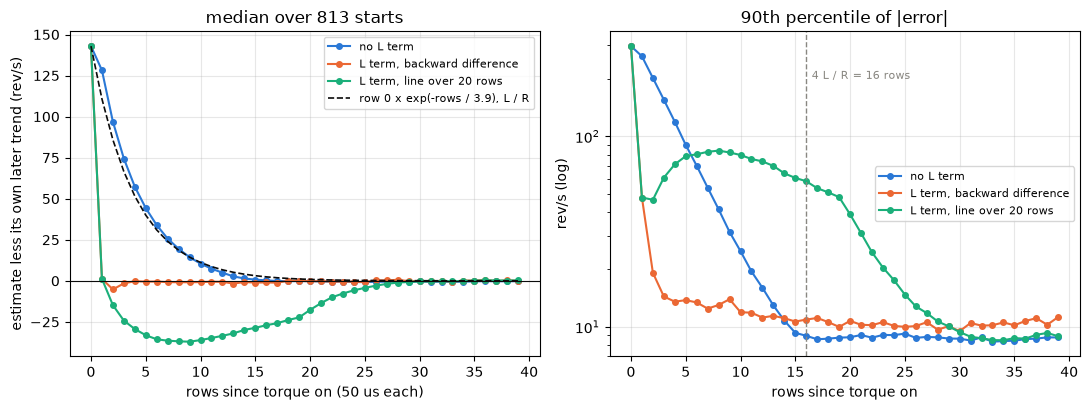

In [112]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
k = np.arange(40)
for (name, label), c in zip([("none", "no L term"),
                             ("ends 1", "L term, backward difference"),
                             ("line 20", "L term, line over 20 rows")],
                            (BLUE, ORANGE, GREEN)):
    a1.plot(k, PROF_MED.loc[name].to_numpy(), color=c, marker="o", ms=4,
            label=label)
    a2.semilogy(k, PROF_P90.loc[name].to_numpy(), color=c, marker="o",
                ms=4, label=label)
a1.plot(k, pm[0] * np.exp(-k / TAU_E_ROWS), color=INK, lw=1.2, ls="--",
        label=f"row 0 x exp(-rows / {TAU_E_ROWS:.1f}), L / R")
a1.axhline(0, color=INK, lw=0.8)
a1.legend(fontsize=8)
figures.label(a1, x="rows since torque on (50 us each)",
              y="estimate less its own later trend (rev/s)",
              title=f"median over {len(V_START)} starts")
N_START = int(np.ceil(4 * TAU_E_ROWS))          # rows, 4 L / R
a2.axvline(N_START, color=MUTED, lw=1, ls="--")
a2.text(N_START + 0.5, 200, f"4 L / R = {N_START} rows", color=MUTED,
        fontsize=8)
a2.legend(fontsize=8)
figures.label(a2, x="rows since torque on", y="rev/s (log)",
              title="90th percentile of |error|")
figures.finish(fig)

What you are looking at. Left, the median error of the first 40 rows after torque on over every start, with no L term (blue), with the backward difference (orange) and with a 20-row line (green), and the dashed decay of row 0's median with the identification's L / R. Right, the 90th percentile of the error's magnitude on a log scale, with the dashed line at 4 L / R.

The estimate reads the applied volts as speed until the current builds. Row 0 reads +143 rev/s at the median over 813 starts, +38 at under 15 % duty up to +500 at 100 %, 56 to 83 % of the applied volts over Ke. The median decays with 3.44 rows against the identification's L / R of 3.93. From row 14 the 90th percentile of the error stays inside 1.25 times its settled level, 13 to 15 by duty class, 3.6 L / R. The L term does not shorten it in a usable form. The backward difference brings the median to zero from row 1, at its noise, and the 20-row line makes it worse (row 28, -37 rev/s at rows 8 to 10). The rule taken from this is 4 L / R rows, 16 here, after torque on and after a flip of the drive's direction. Confidence high.

The same thing happens after every duty step, scaled by the step (section 8). In closed loop the duty moves every tick, so this is not a flag. It is a direct path from the duty to the estimate, 0.751 of the volts' step over Ke over the first 4 rows, 0.299 over the next 6 and 0.114 over the next 30, which a loop design reads.

### (b) The dropout rows

The rule flags a row whose current is under stage 3's share (`oscnb.tel`'s dropout fraction) of a one-pole mean of the rows not flagged. It keeps that one-pole mean and a count of flagged rows running, updated once per row. There is no flag while the mean is under 5 sd of the current's own noise at rest (section 6's rest windows), in the first 10 L / R rows of a run, or for more than 2 L / R rows running, after which the level is taken to have moved and the reference restarts. It is scored against stage 3's marking (the same share of a centered local mean) on the run-ups, then by what holding the last value or skipping does behind a filter.

In [113]:
from oscnb import tel

rest_band = Q1_BANDS[Q1_BANDS.kind == "rest"]
I_NOISE_A = float(rest_band.crest_sd_counts.iloc[0]) * CHAIN.a_per_count
DROP_FRAC = float(tel.DROPOUT_FRAC)             # stage 3's share
DROP_HOLD = int(round(10 * TAU_E_ROWS))         # rows, no flag at a start
DROP_FLOOR_A = 5 * I_NOISE_A                    # A, no flag under it
DROP_MAX = int(np.ceil(2 * TAU_E_ROWS))         # rows a flag may run
lens = []
for _, g in RUN_W.groupby(["set", "k", "dir"]):
    mk = DROPPED[int(g["run0"].iloc[0]):int(g["g1"].max())].astype(np.int8)
    edge = np.diff(np.r_[0, mk, 0])             # stage 3's marked runs
    lens += list(np.flatnonzero(edge == -1) - np.flatnonzero(edge == 1))
lens = np.array(lens)
print(f"stage 3's dropouts in the run-ups: {len(lens)} events, rows each: "
      f"median {np.median(lens):.0f}, max {lens.max()}; the rule lets a "
      f"flag run {DROP_MAX} rows (2 L / R, rounded up)")
print(f"rule: under {DROP_FRAC} of the recent mean, no flag under "
      f"{DROP_FLOOR_A * 1e3:.1f} mA (5 x the rest noise "
      f"{I_NOISE_A * 1e3:.2f} mA) or in the first {DROP_HOLD} rows")

stage 3's dropouts in the run-ups: 52 events, rows each: median 1, max 1; the rule lets a flag run 8 rows (2 L / R, rounded up)
rule: under 0.25 of the recent mean, no flag under 5.0 mA (5 x the rest noise 1.00 mA) or in the first 39 rows


In [114]:
det, eff = [], []
for (name, kk_, dd), g in RUN_W.groupby(["set", "k", "dir"]):
    g = g[g["ok"]].sort_values("t")
    run0 = int(g["run0"].iloc[0])
    E = est(run0, int(g["g1"].max()), float(g["ntc_c"].iloc[0]))
    wt, wp = solve(E)
    f = E["first"]
    s3 = DROPPED[E["idx"]]                      # stage 3's marked rows
    k = (E["idx"] - run0).astype(float)
    tk = np.r_[0.0, g["t"].to_numpy() * FS]
    tv = np.r_[0.0, g["truth"].to_numpy()]
    scored = (k >= 40) & (k < len(k) - 20)
    for n_ref in (16, 32, 64):
        fl = speed.dropout_flag(E["i_w"], DROP_FRAC, speed.pole_alpha(n_ref),
                                DROP_FLOOR_A, f, DROP_HOLD, DROP_MAX)
        det.append(dict(n_ref=n_ref, s3=int(s3[scored].sum()),
                        mine=int(fl[scored].sum()),
                        both=int((s3 & fl)[scored].sum()),
                        rows=int(scored.sum())))
    fl = speed.dropout_flag(E["i_w"], DROP_FRAC, speed.pole_alpha(32),
                            DROP_FLOOR_A, f, DROP_HOLD, DROP_MAX)
    truth = np.interp(k - 15.5, tk, tv)         # delayed as a 32-row box
    m = k >= tk[1] + 64
    band = band_of(truth)
    a16 = speed.pole_alpha(16)
    for how, y in (
            ("none", speed.boxcar(wp, 32, f)),
            ("hold-last", speed.boxcar(speed.hold_last(wp, ~fl, f), 32, f)),
            ("skip (pole)", speed.one_pole_skip(wp, a16, ~fl, f)),
            ("pole, none", speed.one_pole(wp, a16, f)),
            ("stage 3 rows out",
             speed.boxcar(speed.hold_last(wp, ~s3, f), 32, f))):
        for bn in ("160-250", "250-350", "350-450", "450-600"):
            mm = m & (band == bn)
            if mm.sum() > 20:
                e = y[mm] - truth[mm]
                eff.append(dict(how=how, band=bn, run=f"{name}/{kk_}/{dd}",
                                bias=e.mean(), rms=np.sqrt(np.mean(e ** 2)),
                                share=float(fl[mm].mean())))

In [115]:
V_DROP = pd.DataFrame(det).groupby("n_ref").sum()
V_DROP["recall"] = V_DROP.both / V_DROP.s3
V_DROP["precision"] = V_DROP.both / V_DROP.mine
d0 = V_DROP.iloc[0]
print(f"run-ups: stage 3 marks {int(d0.s3)} of {int(d0.rows)} rows "
      f"({100 * d0.s3 / d0.rows:.2f} %)")
for n_ref, d in V_DROP.iterrows():
    print(f"  reference over {n_ref:2d} rows: flags {int(d.mine)}, hit rate "
          f"{100 * d.recall:.1f} %, of its flags stage 3's "
          f"{100 * d.precision:.1f} %")
V_EFFECT = pd.DataFrame(eff)
print("behind a 32-row boxcar (pole: 16 rows), product form, error against "
      "the order count: bias +/- se / rms by band")
for how in V_EFFECT.how.unique():
    print(f"  {how:17s} " + "  ".join(
        f"{bn}: {g.bias.mean():+.2f}+/-{se(g.bias):.2f} / "
        f"{np.sqrt((g.rms ** 2).mean()):.1f}"
        for bn, g in V_EFFECT[V_EFFECT.how == how].groupby("band")))
print("  dropout rows by band (share of rows flagged): " + "  ".join(
    f"{bn}: {100 * g.share.mean():.2f} %"
    for bn, g in V_EFFECT[V_EFFECT.how == "none"].groupby("band")))

run-ups: stage 3 marks 45 of 34651 rows (0.13 %)
  reference over 16 rows: flags 47, hit rate 100.0 %, of its flags stage 3's 95.7 %
  reference over 32 rows: flags 47, hit rate 100.0 %, of its flags stage 3's 95.7 %
  reference over 64 rows: flags 47, hit rate 100.0 %, of its flags stage 3's 95.7 %


behind a 32-row boxcar (pole: 16 rows), product form, error against the order count: bias +/- se / rms by band
  none              160-250: -2.78+/-0.64 / 5.0  250-350: -3.02+/-0.37 / 4.8  350-450: +1.81+/-0.80 / 8.5  450-600: +9.45+/-1.34 / 15.2
  hold-last         160-250: -2.78+/-0.64 / 5.0  250-350: -3.02+/-0.37 / 4.8  350-450: +1.52+/-0.75 / 7.9  450-600: +8.53+/-1.17 / 13.8
  skip (pole)       160-250: -2.62+/-0.61 / 5.1  250-350: -3.16+/-0.37 / 5.0  350-450: +1.51+/-0.76 / 8.1  450-600: +8.62+/-1.20 / 14.0
  pole, none        160-250: -2.62+/-0.61 / 5.1  250-350: -3.16+/-0.37 / 5.0  350-450: +1.76+/-0.80 / 8.6  450-600: +9.41+/-1.34 / 15.1
  stage 3 rows out  160-250: -2.78+/-0.64 / 5.0  250-350: -3.02+/-0.37 / 4.8  350-450: +1.53+/-0.75 / 7.9  450-600: +8.57+/-1.18 / 13.9
  dropout rows by band (share of rows flagged): 160-250: 0.00 %  250-350: 0.00 %  350-450: 0.08 %  450-600: 0.55 %


On the steady windows stage 3 marked its dropout rows against the window's mean, and the brush forms were fitted with those rows in. Per window, the rows per second each rule marks, the change of the window mean with hold-last, and the noise behind 32 rows with no rule, with hold-last and with a median of 3 ahead of the boxcar.

In [116]:
rows = []
for r in STEADY[STEADY.kind != "rest"].itertuples():
    E = est(r.run0, r.g1, r.ntc_c)
    wt, wp = solve(E)
    m = E["idx"] >= r.g0
    if m.sum() < 400:
        continue
    f = E["first"]
    fl = speed.dropout_flag(E["i_w"], DROP_FRAC, speed.pole_alpha(32),
                            DROP_FLOOR_A, f, DROP_HOLD, DROP_MAX)
    s3 = tel.dropout_rows((E["crest"] - E["zero"])[m])  # window's mean
    deg = 2 if r.truth > 250 else 1
    held_t = speed.hold_last(wt, ~fl, f)
    filt = lambda y: np.std(detrend(speed.boxcar(y, 32, f)[m], deg))  # noqa
    rows.append(dict(
        kind=r.kind, band=r.band, s3_rate=s3.mean() * FS,
        rate=fl[m].mean() * FS, both=int((s3 & fl[m]).sum()),
        n_s3=int(s3.sum()), n_fl=int(fl[m].sum()),
        i_ma=1e3 * E["i_w"][m].mean(), none_t=wt[m].mean() - r.truth,
        hold_t=held_t[m].mean() - r.truth, none_p=wp[m].mean() - r.truth,
        hold_p=speed.hold_last(wp, ~fl, f)[m].mean() - r.truth,
        sd_none=filt(wt), sd_hold=filt(held_t),
        sd_med=filt(speed.median3(wt, f))))
V_STEADY = pd.DataFrame(rows)
for (kind, bn), g in V_STEADY.groupby(["kind", "band"], sort=False):
    print(f"{kind:9s} {bn:8s} n {len(g):2d} {g.i_ma.mean():4.0f} mA: stage 3"
          f" {g.s3_rate.mean():6.1f}, rule {g.rate.mean():6.1f} rows/s (hit "
          f"{100 * g.both.sum() / max(g.n_s3.sum(), 1):3.0f} %, its own "
          f"{100 * g.both.sum() / max(g.n_fl.sum(), 1):3.0f} %); table "
          f"{(g.hold_t - g.none_t).mean():+.2f} +/- "
          f"{se(g.hold_t - g.none_t):.2f}, product "
          f"{(g.hold_p - g.none_p).mean():+.2f}; "
          f"{np.sqrt((g.sd_none ** 2).mean()):.2f} -> "
          f"{np.sqrt((g.sd_hold ** 2).mean()):.2f} "
          f"({np.sqrt((g.sd_med ** 2).mean()):.2f})")

ladder    30-100   n 34   65 mA: stage 3    0.0, rule    0.0 rows/s (hit   0 %, its own   0 %); table +0.00 +/- 0.00, product +0.00; 3.40 -> 3.40 (3.38)
ladder    0-30     n  2   64 mA: stage 3    0.0, rule    0.0 rows/s (hit   0 %, its own   0 %); table +0.00 +/- 0.00, product +0.00; 4.72 -> 4.72 (4.70)
ladder    100-160  n 18   84 mA: stage 3    0.0, rule    0.0 rows/s (hit   0 %, its own   0 %); table +0.00 +/- 0.00, product +0.00; 2.59 -> 2.59 (2.56)
ladder    160-250  n 18  103 mA: stage 3    0.0, rule    0.0 rows/s (hit   0 %, its own   0 %); table +0.00 +/- 0.00, product +0.00; 1.30 -> 1.30 (1.27)
ladder    250-350  n 18  127 mA: stage 3    0.0, rule    0.0 rows/s (hit   0 %, its own   0 %); table +0.00 +/- 0.00, product +0.00; 0.93 -> 0.93 (0.90)
ladder    350-450  n 15  204 mA: stage 3   18.3, rule   15.7 rows/s (hit  88 %, its own 100 %); table -0.12 +/- 0.05, product -0.17; 1.92 -> 1.71 (1.63)
ladder    450-600  n  3  272 mA: stage 3    0.0, rule    0.0 rows/s (hit   0 %, it

Every dropout stage 3 marked in the run-ups is one row long (52 events), and the rule's flags match them, a hit rate of 100.0 % with 95.7 % of its 47 flags stage 3's, the same for a reference of 16, 32 or 64 rows. The only steady band with any is the ladder's 350-450, 18.3 rows/s by stage 3's rule and 15.7 by this one. Holding the last value is worth little here. The flagged rows are 0.08 % of the run-ups' rows at 350-450 and 0.55 % above 450, none below. Behind a 32-row boxcar hold-last moves the run-ups' bias from +1.81 to +1.52 and from +9.45 to +8.53 rev/s on the two top bands, and on the ladder's 350-450 it moves the window mean by -0.12 +/- 0.05 rev/s and the filtered noise from 1.92 to 1.71. A median of 3 ahead of the boxcar does the same job without a detector (1.63) at one row of delay. The forms were fitted with the dropout rows in, so the shift is a small bias against their fit, inside their own error there. Confidence high for the detection, moderate for the effect.

### The coverage

The valid flag over every driven row of the 521 sweeps, as `speed.valid_rows` computes it per row. A row is valid when its on-time is at or over the tap floor, at least 4 L / R rows (rounded up) have passed since torque on and since the drive's direction flipped, and it is not a dropout row. The state it keeps is the rows since the last start and the last flip and the dropout rule's one-pole mean and flag count. Beside it, not in the flag, `window_valid`'s own zeros, the share under a 96-tick floor, and the valid rows inside 4 L / R of a duty step larger than twice the row noise of section 6's 30-100 rev/s holds.

In [117]:
NOISE_REV_S = float(Q1_BANDS.query("kind == 'hold' and band == '30-100'")
                    .table_sd.iloc[0])          # rev/s, the crawl's noise
ALPHA_DROP = speed.pole_alpha(32)
rows = []
for s in SW.itertuples():
    E = est(int(s.i0), int(s.i1))
    if len(E["idx"]) == 0:
        continue
    valid, tap_ok, started, drop = speed.valid_rows(
        E["duty"], E["i_w"], E["first"], E["flip"], TAP_FLOOR, N_START,
        N_START, DROP_FRAC, ALPHA_DROP, DROP_FLOOR_A, DROP_HOLD, DROP_MAX)
    dv = (np.abs(np.diff(E["duty"], prepend=E["duty"][0]))
          / CHAIN.half_period_ticks * np.abs(E["v_on"]) / KE)
    step = (dv > 2 * NOISE_REV_S) & ~E["first"] & ~E["flip"]
    after = speed.rows_since(step) < N_START
    name = (s.experiment if s.experiment != "load"
            else "load " + s.ds.rsplit("-", 1)[0])
    rows.append(dict(
        set=name, sweeps=1, driven=len(E["idx"]),
        tap_fail=int((~tap_ok).sum()), start=int((tap_ok & ~started).sum()),
        dropout=int((tap_ok & started & drop).sum()), valid=int(valid.sum()),
        wv_fail=int((ARR["valid"][E["idx"]] == 0).sum()),
        tap_fail_96=int((np.abs(E["duty"]) < FLOOR_MARGIN).sum()),
        after_step=int((valid & after).sum()), runs=int(E["first"].sum()),
        flips=int(E["flip"].sum()), steps=int(step.sum())))
V_COVER = pd.DataFrame(rows).groupby("set").sum()
V_COVER.loc["all"] = V_COVER.sum()
for c in ("tap_fail", "start", "dropout", "valid", "wv_fail", "tap_fail_96",
          "after_step"):
    V_COVER[c + "_pct"] = 100 * V_COVER[c] / V_COVER.driven
print(f"tap floor {TAP_FLOOR} ticks, {N_START} rows after torque on or a "
      f"flip, dropout under {DROP_FRAC} of the recent mean; duty step = more"
      f" than {2 * NOISE_REV_S:.1f} rev/s of volts in one row")

tap floor 84 ticks, 16 rows after torque on or a flip, dropout under 0.25 of the recent mean; duty step = more than 9.7 rev/s of volts in one row


In [118]:
print(f"set              sweeps   driven rows  runs flips | under floor  "
      f"start-up  dropout |  valid % | window_valid 0  under "
      f"{FLOOR_MARGIN} ticks  after a duty step")
for r in V_COVER.itertuples():
    print(f"{r.Index:16s} {r.sweeps:5d} {r.driven:12d} {r.runs:5d} "
          f"{r.flips:4d} | {r.tap_fail_pct:9.2f} % {r.start_pct:7.3f} % "
          f"{r.dropout_pct:6.3f} % | {r.valid_pct:7.2f}  | "
          f"{r.wv_fail_pct:10.2f} % {r.tap_fail_96_pct:12.2f} % "
          f"{r.after_step_pct:12.3f} %")
al = V_COVER.loc["all"]
print(f"all: lost to start-up and dropouts together "
      f"{al.start_pct + al.dropout_pct:.2f} %; window_valid alone passes "
      f"{100 - al.wv_fail_pct:.2f} %; with a {FLOOR_MARGIN}-tick floor "
      f"{100 - al.tap_fail_96_pct - al.start_pct - al.dropout_pct:.2f} %")

set              sweeps   driven rows  runs flips | under floor  start-up  dropout |  valid % | window_valid 0  under 96 ticks  after a duty step
inductance           2        11991     2    0 |      0.00 %   0.267 %  0.000 % |   99.73  |       0.00 %         0.00 %        0.042 %
ladder             123      4231408   248    0 |     23.82 %   0.094 %  0.023 % |   76.06  |      20.42 %        30.63 %        0.011 %
load bottom         18       420002    19    0 |      0.00 %   0.071 %  0.000 % |   99.93  |       0.00 %         0.00 %        0.000 %
load ladder        112       729503   239    0 |      6.57 %   0.472 %  0.000 % |   92.95  |       3.29 %         6.57 %        0.101 %
load lift           36       527979    38    0 |      0.00 %   0.111 %  0.000 % |   99.89  |       0.00 %         0.00 %        0.000 %
load steps          55      1113753   110    0 |      9.87 %   0.149 %  0.000 % |   89.98  |       5.39 %         9.87 %        0.097 %
pot-table           21      1149774   

With the floor at 84 ticks, 16 rows after torque on or a flip and the dropout rule, 85.21 % of the 10508431 driven rows of 518 sweeps are valid. Every loss but 0.17 % is the tap floor, 14.62 % of the rows, the crawls and narrow holds (23.82 % of the ladder's rows, 20.92 % of the sag's, 15.57 % of the pot table's). `window_valid` alone would pass 90.98 %, including the 72-tick rows that read 4 rev/s low. With a 96-tick floor the share is 78.72 %. The valid rows inside 16 of a duty step larger than twice the crawl's row noise are 0.049 %, since these captures run open loop. Under the floor the feedback has to come from somewhere else, the pot.

The rule, per row at the control tick, float throughout.

- The tap floor. The on-time is at least the board's floor, 84 ticks here. Stateless, one constant.
- The start-up. At least 4 L / R rows, 16 here, since torque on and since the drive's direction flipped. The state is the two row counters, the constants the identification's L and R.
- The dropout. The row is not under 0.25 of the one-pole mean (32 rows) of the unflagged rows, with no flag while that mean is under 5 sd of the current's rest noise, in the first 10 L / R rows of a run or for more than 2 L / R rows running. The state is the one-pole mean and the count of flagged rows. A flagged row holds the last value.

### The numbers sections 8 and 9 hand on

The L term's worth set against a filter's own delay, then the result-file values of the two sections. The recommendation's threshold, a filter of 32 rows of delay, is where the term's 3.9 rows fall to an eighth of the filter's delay.

In [119]:
L_CARRY_BELOW_ROWS = 32                         # rows of filter delay
q, pm9 = results.quantity, results.pm
R_S8 = {"l_term": {
    "lag_rows": q(TAU_E_ROWS, unit="rows, L / R"),
    "runup_bias_no_l": {bn: pm9(v["none"], v["none_se"], "rev/s, +/- se")
                        for bn, v in RUNUP_BINS.items()},
    "predicted": {bn: q(v["predicted"], unit="rev/s, L / R x acceleration")
                  for bn, v in RUNUP_BINS.items()},
    "removed_by_slope": {bn: {c: pm9(*v["removed"][c], "rev/s, +/- se")
                              for c in L_NAMES[1:]}
                         for bn, v in RUNUP_BINS.items()},
    "noise_ratio_by_slope_band": {
        f"{r.kind} {r.band}": {} for r in LT_NOISE.itertuples()},
    "behind_filter": {
        f"{'locked 1' if r.n == 0 else f'box {r.n}'}, {r.what}, {r.l}":
            q(r.mean, r.mean - r.se, r.mean + r.se, "rev/s, +/- se")
            if np.isfinite(r.se) else q(r.mean, unit="rev/s sd")
        for r in LT_BEHIND.itertuples()},
    "recommendation": {"carry_below_delay_rows": L_CARRY_BELOW_ROWS,
                       "slope": "least-squares line", "rows": 100}}}
for r in LT_NOISE[LT_NOISE.l != "none"].itertuples():
    R_S8["l_term"]["noise_ratio_by_slope_band"][f"{r.kind} {r.band}"][
        r.l] = {"per_row": float(r.x_sd_t), "behind_box_32": float(r.x_sd_b32),
                "window_mean_shift": float(r.d_mean_t), "n": int(r.n)}
print(len(R_S8["l_term"]), "l_term entries")

7 l_term entries


In [120]:
s10 = STEP_EXCESS[10]
R_S8["duty_step_response"] = {
    "share_rows_0_3": q(share["0-4"], unit="of the volts' step / Ke"),
    "share_rows_4_9": q(share["4-10"], unit="of the volts' step / Ke"),
    "share_rows_10_39": q(share["10-40"], unit="of the volts' step / Ke"),
    "excess_ohm": pm9(s10.dr.mean(), se(s10.dr), "ohm, 10 % steps, +/- se"),
    "excess_ohm_se": q(se(s10.dr), unit="ohm"),
    "excess_by_step": {f"{k} %": {"rev_s": pm9(g.err.mean(), se(g.err),
                                               "rev/s, +/- se"),
                                  "share": float(g.share.mean()),
                                  "ohm": pm9(g.dr.mean(), se(g.dr), "ohm"),
                                  "n": len(g)}
                       for k, g in STEP_EXCESS.items()},
    "n": int(big.tr.nunique())}
print(len(R_S8["duty_step_response"]), "duty step entries")

7 duty step entries


In [121]:
R_S9 = {"valid_rule": {
    "tap_floor_ticks": q(TAP_FLOOR, int(bad.hi.max()), FLOOR_MARGIN,
                         "ticks; bounds: the failing rung below, the first "
                         "rung with 10 runs or more"),
    "tap_floor_stage3_key_ticks": q(s3_floor["value"], unit=s3_floor["unit"]),
    "tap_floor_stage3_closing_ticks": q(s3_need, unit="ticks"),
    "start_rows": q(N_START, unit="rows, 4 L / R rounded up"),
    "start_rows_in_l_over_r": q(N_START / TAU_E_ROWS, unit="L / R"),
    "dropout_frac": q(DROP_FRAC, unit="of the one-pole mean"),
    "dropout_reference_rows": q(32, unit="rows, the one-pole"),
    "dropout_floor_a": q(DROP_FLOOR_A, unit="A, 5 sd of the rest noise"),
    "dropout_hold_rows": q(DROP_HOLD, unit="rows, 10 L / R"),
    "dropout_max_rows": q(DROP_MAX, unit="rows, 2 L / R")}}
R_S9["tap_deficit_by_ticks"] = {
    f"{g.lo}-{g.hi}": {"n": int(g.n), "sweeps": int(g.sweeps),
                       "deficit_mv": q(g.deficit, g.d_lo, g.d_hi,
                                       "mV, median [10-90 %]"),
                       "tap_sd_counts": float(g.tap_sd),
                       "as_rev_s": float(g.err),
                       "window_valid_share": float(g.wv)}
    for g in V_FLOOR.itertuples()}
R_S9["tap_deficit_by_ticks"]["drop_line"] = {
    "c0_mv": DROP_LINE[1] * 1e3, "r_ohm": DROP_LINE[0], "resid_sd_mv": SD_WIDE}
print(len(R_S9["tap_deficit_by_ticks"]), "on-time bins")

12 on-time bins


In [122]:
R_S9["dropout_rule_vs_stage3"] = {
    f"reference {n} rows": {"hit_rate": float(d.recall),
                            "precision": float(d.precision),
                            "n": int(d.s3), "flags": int(d.mine)}
    for n, d in V_DROP.iterrows()}
R_S9["dropout_hold_last_effect"] = {
    how: {bn: {"bias": pm9(g.bias.mean(), se(g.bias), "rev/s, +/- se"),
               "rms": q(np.sqrt((g.rms ** 2).mean()), unit="rev/s")}
          for bn, g in V_EFFECT[V_EFFECT.how == how].groupby("band")}
    for how in V_EFFECT.how.unique()}
R_S9["startup_profile"] = {
    "median": {f"row {j}": float(PROF_MED.loc["none", f"k{j}"]) for j in SHOWK},
    "p90": {f"row {j}": float(PROF_P90.loc["none", f"k{j}"]) for j in SHOWK},
    "decay_rows": q(START_DECAY_ROWS, unit="rows, median, rows 2-12"),
    "settled_rows": {k: q(v, unit="rows") for k, v in START_ROWS.items()},
    "settled_rows_by_duty": START_BY_DUTY,
    "row0_by_duty": {str(d): {"median": float(g["e0_none"].median()),
                              "volts_over_ke": float(g.v_ke.median()),
                              "n": len(g)}
                     for d, g in V_START.groupby("duty", observed=True)}}
print(len(R_S9["valid_rule"]), "valid rule entries")

10 valid rule entries


In [123]:
R_S9["rest_bias_by_current"] = {
    form: {"a": pm9(v["a"], v["a_se"], "rev/s, +/- se"),
           "b_per_a": pm9(v["b"], v["b_se"], "rev/s per A, +/- se"),
           "ohm": q(v["ohm"], unit="ohm"), "resid_sd": v["resid_sd"],
           "bins": {str(g.bin): pm9(getattr(g, form), getattr(g, form + "_se"),
                                    "rev/s, +/- se")
                    for g in V_REST_BINS.itertuples()}}
    for form, v in REST_LINES.items()}
R_S9["rest_bias_by_current"]["mean"] = {
    c: pm9(R9[c].mean(), se(R9[c]), "rev/s, +/- se")
    for c in ("table", "product", "plain")}
R_S9["valid_coverage_by_set"] = {
    s: {"sweeps": int(r.sweeps), "driven_rows": int(r.driven),
        "under_floor_pct": float(r.tap_fail_pct),
        "start_up_pct": float(r.start_pct),
        "dropout_pct": float(r.dropout_pct), "valid_pct": float(r.valid_pct),
        "window_valid_0_pct": float(r.wv_fail_pct),
        f"under_{FLOOR_MARGIN}_ticks_pct": float(r.tap_fail_96_pct),
        "after_duty_step_pct": float(r.after_step_pct)}
    for s, r in V_COVER.iterrows()}
print(sum(len(v) for v in R_S9.values()), "entries under",
      len(R_S9), "keys")

53 entries under 7 keys


## 10. What stage 5 reads from here

One table carries what a velocity loop needs from this estimate. The bias by band and form is the brush forms' held-out score of section 4 with the coast-tail zero, the window mean against the truth. The noise per tick is section 6's per-row sd of the table form, with the product form beside it. The delay is section 7's measured added delay in rows on the run-ups for the working filters. The valid rule and its share are section 9's.

In [124]:
sc = SC[(SC["zero"] == "tail") & (SC["level"] == "window")]
pick = [("ladder, two repeats", "ladder (third repeat)"),
        ("ladder alone", "holds (free, low)"), ("ladder alone", "refs"),
        ("ladder alone", "run-up"), ("ladder alone", "lifts"),
        ("ladder alone", "load holds")]
rows5 = []
for fit, name in pick:
    g = sc[(sc["fit"] == fit) & (sc["set"] == name)]
    for band, gb in g.groupby("band", sort=False):
        b = gb.set_index("form")
        rows5.append({"set": name, "band": band,
                      "rev_s": round(b["rev_s"].iloc[0], 1),
                      "mA": round(b["i_a"].iloc[0] * 1e3),
                      "table": round(b.loc["table", "bias"], 2),
                      "product": round(b.loc["product", "bias"], 2)})
BIAS5 = pd.DataFrame(rows5)
print("bias by band and form (rev/s, window mean less truth, held out):")
print(BIAS5.to_string(index=False))
nz5 = Q1_BANDS[["kind", "band", "truth", "table_sd", "product_sd"]]
print("\nnoise per tick (rev/s sd per row):")
print(nz5.round(2).to_string(index=False))

bias by band and form (rev/s, window mean less truth, held out):
                  set    band  rev_s  mA  table  product
ladder (third repeat)  30-100   94.0  73  -0.31     0.12
ladder (third repeat) 100-160  137.5  85  -0.03     0.01
ladder (third repeat) 160-250  211.8 103   0.06    -0.08
ladder (third repeat) 250-350  303.3 127   0.15    -0.17
ladder (third repeat) 350-450  413.2 204  -2.81     1.14
ladder (third repeat) 450-600  456.9 272   5.96    -1.71
    holds (free, low)    0-30   23.4  39  -0.88     0.89
    holds (free, low)  30-100   35.6  42  -0.55     0.73
    holds (free, low) 160-250  210.4  98   1.12     1.35
    holds (free, low) 250-350  253.6 105  -0.32    -0.40
                 refs 100-160  141.4  81   0.54     0.84
               run-up 160-250  218.9 655  30.00    -1.34
               run-up 250-350  306.2 512  27.10    -1.92
               run-up 350-450  408.7 349  12.45     2.31
               run-up 450-600  474.4 249   3.33     7.69
                lifts  

In [125]:
work = ["raw", "box 16", "box 32", "pole 32", "lock 1", "lock 2"]
d5 = Q2_DELAY[(Q2_DELAY["tag"] == "run-up") & (Q2_DELAY["form"] == "product")
              & Q2_DELAY["filter"].isin(work)]
print("delay per filter (rows; run-ups, measured added delay):")
print(d5[["filter", "nominal", "added", "added_se", "rms"]].round(1)
      .to_string(index=False))
allv = V_COVER.loc["all"]
print(f"\nvalid rule: on-time at least {TAP_FLOOR} ticks ({FLOOR_MARGIN} the "
      f"first rung with enough runs; stage 3: {s3_floor['value']:.0f} by its "
      f"key, {s3_need} in its closing table), {N_START} rows "
      f"({N_START / FS * 1e3:.2f} ms) after torque on or a flip, not a "
      f"dropout row (under {DROP_FRAC} of the recent mean, at most "
      f"{DROP_MAX} rows running)")
print(f"valid share of driven rows {allv['valid_pct']:.2f} % over "
      f"{int(allv['sweeps'])} sweeps; under the floor "
      f"{allv['tap_fail_pct']:.2f} %, start-up {allv['start_pct']:.3f} %, "
      f"dropout {allv['dropout_pct']:.3f} %")

delay per filter (rows; run-ups, measured added delay):
 filter  nominal  added  added_se  rms
    raw      0.0    0.0       0.0 23.7
 box 16      7.5    8.0       0.2  8.2
 box 32     15.5   16.4       0.3 10.9
pole 32     31.5   32.8       0.3 18.2
 lock 1      NaN    6.4       0.2  8.5
 lock 2      NaN   13.3       0.3 10.0

valid rule: on-time at least 84 ticks (96 the first rung with enough runs; stage 3: 72 by its key, 93 in its closing table), 16 rows (0.80 ms) after torque on or a flip, not a dropout row (under 0.25 of the recent mean, at most 8 rows running)
valid share of driven rows 85.21 % over 518 sweeps; under the floor 14.62 %, start-up 0.144 %, dropout 0.025 %


What a velocity loop reads, for this servo on this board. The estimate runs once per control tick at 20000 rows/s, in float. Its state is the tracked zero's two zeros and fresh counters, the previous row's speed and direction for the table's two newton steps, the filter's own state and the valid rule's counters. Its constants are the chain's scales and edge lags, R at its board temperature with copper's slope, V0, g, the brake line, L, Ke and one of the two brush forms, all from the result files of stages 1 to 3, the current-zero notebook's result and section 4.

- **Bias by band and form.** On the free shaft both forms read within about 1 rev/s of the truth from 30 to 350 rev/s held out (table -0.31 to +0.15, product -0.17 to +0.12 on the ladder's third repeat), and within 1.35 rev/s on the holds and references. Under current at speed the table reads +30.00, +27.10 and +12.45 rev/s high in the run-ups from 160 to 450 rev/s, and the product -1.34, -1.92 and +2.31. At low speed under current both read high, the table +3.46 to +7.42 and the product +3.58 to +4.32 rev/s on the lifts, and +2.81 and +4.75 on the load holds at rest. On the top rungs, 350 to 600 rev/s, neither form is resolved.
- **Noise per tick.** 0.59 rev/s at rest under a narrow drive, 3.84 and 4.86 on the crawl holds, 6.84 at 70 rev/s, 9.47 at 137, 10.54 at 212, 10.83 at 303 and 12.95 and 12.09 on the top rungs, table form. The product form reads the same under 100 rev/s, 13.05 against 10.83 at 303 and 17.46 and 14.24 on the top rungs. It is the commutation ripple, periodic at six times the speed, so averaging n rows does not divide it by the square root of n.
- **Delay per filter.** The DC delay, (N - 1) / 2 rows for a boxcar and (1 - alpha) / alpha for a one-pole, measured within about a row. On the run-ups a boxcar of 16 adds 8.0 rows, of 32 adds 16.4, a one-pole of 32 adds 32.8, and the window locked to one or two commutation periods adds 6.4 and 13.3. Without the L term the estimate trails by L / R, about 4 rows, under acceleration. A duty step passes into the estimate at once, 0.751 of the volts' step over Ke over its first 4 rows, 0.299 over the next 6 and 0.114 over the next 30. That direct path is for the loop design to carry.
- **The valid rule.** On-time at least 84 ticks, 16 rows (0.80 ms) after torque on or a flip of the drive's direction, and not a dropout row, held at its last value. It passes 85.21 % of the driven rows over 518 sweeps. Every loss but the start-up's 0.144 % and the dropouts' 0.025 % is the tap floor, 14.62 % of the driven rows, the crawls and narrow holds. Under the floor the speed feedback has to come from elsewhere, the pot.
- **Start-up.** Seed the filter after the 16 start-up rows, not with them.
- **The stopped rotor** reads forward speed growing with the current (section 9's line), a bias for the velocity notebook to remove, not a flag.

### The gaps

Each gap with the capture that would close it.

1. **The brush form.** The choice between the table and the product is open. Holds at one speed and two currents, at a few speeds across the crawl and the lower ladder (the tag on the hub), would give the shape of X against current at a fixed speed, whether the product's slope at partial duty equals the run-ups', and how the low-speed offset fades to zero at rest.
2. **The run-ups' direction term.** With no dropout term the product fitted with the run-ups carries a direction term of +36.02 mV against the ladder's +12.39. 100 % run-ups on the 3.7 V rail, with half the current and few dropouts, scored row by row with the dropout rows out, would separate the dropouts, the L slope and a direction-dependent brush term.
3. **The top of the range.** The two top rungs are still rising inside their windows. The 7.4 V top rungs held twice as long would settle them.
4. **The tap floor.** It lies between 72 and 84 ticks by this data, 96 is the first rung with enough runs, and stage 3's closing table says 93. A hold ladder at rest from 72 to 96 ticks in steps of 4 would settle it.
5. **The duty step's residue.** 11 to 12 % of a duty step's volts stays in the estimate after the L / R spike, +0.61 ohm on the current's step. The steps on the RL dummy (no EMF) and the same steps with the horn locked would separate the board's reading from the motor.
6. **The stopped rotor's slope.** At rest the estimate's bias rises about 0.31 ohm's worth with the current. The bias against time inside each hold (existing rows), then holds of 0.2 s against 3 s at one current, would separate winding heating from a property of standstill.
7. **The crawl's slow part.** Under 100 rev/s a part of the noise sits under half the commutation rate. The per-period tach intervals against the estimate's period means in the same windows (existing rows) would separate the shaft's wander from the estimate's own.
8. **The rows' slow channels.** The rows carry no NTC and no rail. One sweep's raw telemetry frames against the loader would show whether the stream or the loader leaves them out.
9. **Closed loop.** Every filter here was scored open loop. A closed-loop hold is stage 5's bench.

### The result file

The result file packs every grade above. Every number in it comes from one servo on one board, mg90-d on dev-v006-2A-D, over stage 3's captures of that pair. Repeats here are across repeats, rails, sittings and days of this pair, not across servos.

The first group is sections 2 and 3, with the form, the constants it read, the port's gate by set, band and form, the rows' spread, the inputs' costs and the tracked zero's cost.

In [126]:
q = results.quantity
UNITS = {"n": "windows", "rev_s": "rev/s", "dz_mean": "counts",
         "dz_rms": "counts", "sweeps": "sweeps"}


def pack(row, keys, unit="rev/s"):
    """A table row as {key: quantity}, units from UNITS or `unit`."""
    return {k: q(row[k], unit=UNITS.get(k, unit)) for k in keys
            if np.isfinite(row[k])}


def nest(df, levels, keys, unit="rev/s"):
    """A table as nested dicts by `levels`, each leaf packed."""
    out = {}
    for _, r in df.iterrows():
        d = out
        for lv in levels[:-1]:
            d = d.setdefault(str(r[lv]), {})
        d[str(r[levels[-1]])] = pack(r, keys, unit)
    return out

In [127]:
c, m = CHAIN, MOTOR
QUANTITIES = {
    "estimate_rows_form": COMP3["estimate_form"] + " Per row: the tracked "
    "zero, the row's V_on for the lags, k_d = 0, direction = duty's sign.",
    "constants_used": {
        "counts_per_a": q(1 / c.a_per_count, unit="counts/A"),
        "tap_counts_per_v": q(c.tap_counts_per_v, unit="counts/V"),
        "r_ohm": q(m.r_ohm, unit="ohm"), "t0_c": q(m.t0_c, unit="C"),
        "v0_v": q(m.v0_v, unit="V"), "g_s": q(m.g_s, unit="S"),
        "brake_b0_v": q(m.brake_b0_v, unit="V"),
        "brake_b1_ohm": q(m.brake_b1_ohm, unit="ohm"),
        "l_h": q(m.l_h, unit="H"), "ke_v_per_rev_s": q(KE, unit="V per rev/s"),
        "k_d_candidate": q(MOTOR_KD.k_d_v_per_dropout_s,
                           unit="V per dropout/s"),
        "alpha_cu": q(speed.ALPHA_CU, unit="per C")},
    "nan_row_columns": {k: q(v, unit="rows") for k, v in nan_cells.items()},
    "dir_against_duty_sign_rows": q(int(opposed.sum()), unit="rows"),
}
print(len(QUANTITIES), "keys so far")

4 keys so far


In [128]:
free = G[~G["set"].str.contains("run-up")]
under = free[free["rev_s"] < 350]
QUANTITIES.update({
    "port_gate_by_set_band": nest(
        G, ["set", "band", "form"],
        ["n", "rev_s", "s3_bias", "s3_rms", "row_bias", "row_rms", "d_mean",
         "d_sd", "d_max"]),
    "port_gate_flat_band_rev_s": q(under["d_mean"].abs().max(),
                                   under["d_mean"].min(),
                                   under["d_mean"].max(), "rev/s"),
    "row_sd_in_window_by_band": nest(
        G[G["form"] == "signed"], ["set", "band"], ["n", "row_sd_in_window"]),
    "input_cost": nest(
        INPUTS, ["input", "set", "band"],
        ["n", "d_mean", "d_sd", "d_max", "d_product_mean", "row_sd_base",
         "row_sd_alt"]),
})
lt = {"raw_backward": P_RU, "none": CONTROLS["no L term on either side"][0],
      "window_slope": CONTROLS["L with the window's slope on each row"][0]}
S_RU100 = SetRows(RU, "tail", runup=True)       # the 100-row slope
w100 = S_RU100.solve(TAB_FORM)
sd100 = pd.Series(S_RU100.R.sd(w100), index=RU.index)
L_NOISE = {}
for band, g in RU.groupby("band"):
    L_NOISE[band] = {k: q(v.loc[g.index, "sd_signed"].mean(), unit="rev/s")
                     for k, v in lt.items()}
    L_NOISE[band]["trailing_100"] = q(sd100.loc[g.index].mean(),
                                      unit="rev/s")
QUANTITIES["l_term_row_noise"] = L_NOISE
print({b: {k: round(v["value"], 1) for k, v in d.items()}
       for b, d in L_NOISE.items()})

{'160-250': {'raw_backward': 167.3, 'none': 43.1, 'window_slope': 43.1, 'trailing_100': 44.0}, '250-350': {'raw_backward': 127.1, 'none': 26.6, 'window_slope': 26.5, 'trailing_100': 27.2}, '350-450': {'raw_backward': 87.0, 'none': 16.2, 'window_slope': 16.2, 'trailing_100': 16.3}, '450-600': {'raw_backward': 79.2, 'none': 17.1, 'window_slope': 17.2, 'trailing_100': 17.7}}


In [129]:
zc = ZC.assign(rule=np.where(ZC["zero"] == list(ZEROS)[0], "tracked",
                             "design"))
QUANTITIES["tracked_zero_cost"] = nest(
    zc, ["rule", "set", "band", "state"],
    ["n", "sweeps", "dz_mean", "dz_rms", "dw_mean", "dw_sd", "dw_rms",
     "dw_worst", "dw_rms_pct"])
per_sweep = {}
for zname, rule in zip(ZEROS, ("tracked", "design")):
    g = PW[PW["zero"] == zname]
    for st, gg in g.groupby("state"):
        ps = gg.groupby("sweep")["dw_signed"].mean()
        se = ps.std(ddof=1) / np.sqrt(len(ps))
        per_sweep.setdefault(rule, {})[st] = {
            "mean": q(ps.mean(), ps.mean() - se, ps.mean() + se,
                      "rev/s, +/- se"),
            "sd": q(ps.std(ddof=1), unit="rev/s"),
            "sweeps": q(len(ps), unit="sweeps")}
QUANTITIES["tracked_zero_cost_per_sweep"] = per_sweep
k_cnt = (PW_TRACK["dw_signed"] / PW_TRACK["dz_counts"]).replace(
    [np.inf, -np.inf], np.nan)
ks = PW_TRACK.assign(k=k_cnt).groupby("state")["k"].median()
QUANTITIES["rev_s_per_count"] = q(REV_S_PER_COUNT, ks.min(), ks.max(),
                                  "rev/s per count of zero")
QUANTITIES["tracked_zero_cold_start_derived"] = {
    c: {"runs": q(v["runs"], unit="runs"), "rms_counts": q(v["rms"],
        unit="counts"), "worst_counts": q(v["worst"], unit="counts"),
        "rms_rev_s": q(v["rms"] * REV_S_PER_COUNT, unit="rev/s")}
    for c, v in COLD_Z.items()}
print(len(QUANTITIES), "keys so far")

13 keys so far


The sections 4 to 9 results join the file, and the two tables beside it, the filter table and the per-row noise by band, go to csv files of the same name.

In [130]:
for part in (R_S4, R_S5, R_S6, R_S7, R_S8, R_S9):
    QUANTITIES.update(part)
QUANTITIES["stage5_bias_by_band_form"] = BIAS5.to_dict("records")
NOTES = (
    "One servo on one board, mg90-d on dev-v006-2A-D, stage 3's captures. "
    "The estimate per row: tracked zero (stage 1's tracker, the state "
    "after the row before), the row's V_on for the edge lags, k_d = 0, "
    "direction = the duty's sign, R(T) from the sweep's probe NTC. Two "
    "brush forms side by side, the choice open: the signed table (two "
    "newton steps from the row before) and the product (closed). Truths: "
    "ripple tach (steady windows, duty steps), stage 3's order count "
    "(run-ups), pot through stage 3's table (lifts, load holds; the pot "
    "only selects the holds at rest). Brackets: +/- se unless the unit "
    "says otherwise. Filter table in .filters.csv, per-row noise by band "
    "in .noise.csv.")
path = results.write(STAGE, EXPERIMENT, PAIR_DIR.resolve(), pair=PAIR,
                     notes=NOTES, **QUANTITIES)
base = results.path(STAGE, EXPERIMENT, pair=PAIR)
FILTERS_CSV.to_csv(base.with_suffix(".filters.csv"), index=False,
                   float_format="%.6g")
NOISE_CSV.to_csv(base.with_suffix(".noise.csv"), index=False,
                 float_format="%.6g")
written = results.read(STAGE, EXPERIMENT, pair=PAIR)
print("wrote", path, "with", len(QUANTITIES), "keys, capture",
      written["capture"])
print("and", results.rel(base.with_suffix(".filters.csv")), "and",
      results.rel(base.with_suffix(".noise.csv")))

wrote stages/4-estimators/speed/results/mg90-d__dev-v006-2A-D.json with 45 keys, capture telemetry/mg90-d__dev-v006-2A-D
and stages/4-estimators/speed/results/mg90-d__dev-v006-2A-D.filters.csv and stages/4-estimators/speed/results/mg90-d__dev-v006-2A-D.noise.csv
